# Household trip generation: full-dataset EDA

The current analysis uses all 93,307 supplied households, without a training/test partition, following the revised project direction. The original workbook and historical split artifacts remain unchanged. All descriptive results below are regenerated from the full data; available-value denominators are explicit. Final regression variables, encoding, and exclusions remain decisions for the preparation review. Any later fit using these same data will describe in-sample fit, not held-out predictive performance.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from IPython.display import display as show, Image

## 1. Paths and settings

In [2]:
BASE_DIR = Path.cwd()
INPUTS = BASE_DIR / 'inputs'
INTERMEDIARIES = BASE_DIR / 'intermediaries'
FINAL_OUTPUTS = BASE_DIR / 'final_outputs'
TABLES = FINAL_OUTPUTS / 'tables'
FIGURES = FINAL_OUTPUTS / 'figures'
WORKBOOK = INPUTS / 'households.xlsx'
PREPARED_FILE = INTERMEDIARIES / 'households_prepared.csv'
SHEET = '2006-hhld'
FIGURE_DPI = 400

for folder in [INPUTS, INTERMEDIARIES, FINAL_OUTPUTS, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# Data fields and cleaning rules.
FIELDS = ['hnum', 'gta01hhld', 'dwelltype', 'rec-mail', 'n-call', 'tripday',
          'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
          'nstudent', 'nhhldtrip', 'expf']
ZONES = {'Toronto': (1, 481), 'Durham': (501, 765),
         'York': (1001, 1353), 'Peel': (1501, 1753)}
HIGH_VEHICLE = 10  # A sensitivity flag, not an exclusion from the main sample.
SIZE_TOP, VEHICLE_TOP, ALTERNATIVE_VEHICLE_TOP = 5, 3, 4

COUNTS = ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'nemphome', 'nstudent', 'workers']
COMPOSITION = ['nempft', 'nemppt', 'nemphome', 'nstudent']
LABELS = {
    'nperson': 'Household size', 'nvehicle': 'Vehicles available (raw; 99 = unknown)',
    'nvehicle_clean': 'Vehicles available',
    'nlicence': 'Licensed drivers', 'nempft': 'Full-time workers',
    'nemppt': 'Part-time workers', 'nemphome': 'Home workers',
    'nstudent': 'Students', 'workers': 'Total workers', 'expf': 'Expansion factor',
    'nhhldtrip': 'Weekday household trips', 'dwelling': 'Dwelling type',
    'weekday': 'Survey weekday', 'region': 'Region',
}
ORDERS = {
    'dwelling': ['House', 'Apartment', 'Townhouse', 'Unknown'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
    'region': ['Toronto', 'Durham', 'York', 'Peel'],
}
SUPPORT_REVIEW_N = 30  # Review marker, never a deletion rule.

# Display settings.
# Display caps; exact counts remain unchanged.
CAPS = dict(zip(COUNTS, [8, 6, 6, 5, 3, 2, 5, 6]))
DRIVER_SIZE_TOP, DRIVER_TOP, DRIVER_ALTERNATIVE_TOP = 5, 4, 3
CROSS_CLASS_FIELDS = ['nperson', 'nlicence']
TRIP_CAP = 25

# Shared figure theme: brighter, publication-friendly colours with high-contrast text.
BLUE, VIOLET, ORANGE, AQUA = '#2F80ED', '#8B5CF6', '#F59E0B', '#14B8A6'
PINK = '#EC4899'
INK = '#243447'
COLOURS = {
    'nperson': BLUE, 'nvehicle_clean': AQUA, 'nlicence': '#06B6D4',
    'workers': VIOLET, 'nempft': VIOLET, 'nemppt': '#A855F7',
    'nemphome': PINK, 'nstudent': ORANGE,
    'dwelling': BLUE, 'weekday': AQUA, 'region': '#3B82F6',
}
MEAN_CMAP = LinearSegmentedColormap.from_list(
    'trip_rates', ['#FFF7ED', '#FDBA74', '#60A5FA', '#2563EB'])
COUNT_CMAP = LinearSegmentedColormap.from_list(
    'household_counts', ['#ECFDF5', '#5EEAD4', '#14B8A6', '#0F766E'])
CORR_CMAP = LinearSegmentedColormap.from_list(
    'correlations', ['#F59E0B', '#FFFDF5', '#60A5FA', '#2563EB'])
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK,
    'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'xtick.color': INK, 'ytick.color': INK,
    'figure.facecolor': 'white', 'axes.facecolor': '#FBFDFF',
    'savefig.facecolor': 'white', 'lines.linewidth': 1.8,
})

def style_axes(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#B8CAE0')
    ax.grid(axis='y', color='#DDE8F5', linewidth=.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=3, color='#9FB5CE')

def panel(ax, label):
    ax.text(0, 1.04, label, transform=ax.transAxes, ha='left', va='bottom',
            fontsize=10, fontweight='bold', color=INK)

## 2. Read the household data

In [3]:
raw = pd.read_excel(WORKBOOK, sheet_name=SHEET, usecols='B:P', dtype=object,
                    engine='openpyxl')
assert raw.columns.tolist() == FIELDS, 'The 15 fields in B:P differ from the expected schema.'
print(f'{len(raw):,} households; {len(FIELDS)} analytical fields; '
      f'{raw["gta01hhld"].nunique():,} residential zones.')
show(raw[['hnum', 'gta01hhld', 'nperson', 'nvehicle', 'dwelltype']].head())

93,307 households; 15 analytical fields; 1,179 residential zones.


,hnum,gta01hhld,nperson,nvehicle,dwelltype
0,209654,1,4,2,1
1,215249,1,2,2,2
2,216552,1,2,2,1
3,219744,1,3,2,1
4,226356,1,4,1,1


In [4]:
raw_dictionary = [
    ('hnum', 'Identifier', 'Household sample ID', 'Identifier only; not a predictor'),
    ('gta01hhld', 'Identifier', 'Residential zone in the 2001 system', 'Aggregation; not numeric predictor'),
    ('dwelltype', 'Category', '1 house; 2 apartment; 3 townhouse; 9 unknown', 'Candidate control'),
    ('rec-mail', 'Survey process', 'Y received letter; N did not; 9 unknown', 'Not a predictor'),
    ('n-call', 'Survey process', 'Calls or edits to complete interview', 'Not a predictor'),
    ('tripday', 'Category', '1 Monday through 5 Friday', 'Candidate control'),
    ('nperson', 'Count', 'All residents, including children under 11', 'Proposed core predictor'),
    ('nvehicle', 'Count with unknown', 'Personal-use vehicles; 99 provisionally unknown', 'Household characteristic'),
    ('nlicence', 'Count', 'Residents holding a driving licence', 'Cross-classification predictor'),
    ('nempft', 'Count', 'Full-time workers including home workers', 'Composition predictor'),
    ('nemppt', 'Count', 'Part-time workers including home workers', 'Composition predictor'),
    ('nemphome', 'Overlapping count', 'Home workers already inside full/part-time counts', 'Composition predictor'),
    ('nstudent', 'Count', 'Full/part-time students; includes ages 6-10; can overlap workers', 'Composition predictor'),
    ('nhhldtrip', 'Count', 'Recorded person trips on survey weekday; ages 11+', 'Outcome'),
    ('expf', 'Weight', 'Household expansion factor; positive', 'Weighting choice belongs to methodology'),
]
original_dictionary = pd.DataFrame(raw_dictionary, columns=['Field', 'Type', 'Definition', 'Role'])
show(original_dictionary)

,Field,Type,Definition,Role
0,hnum,Identifier,Household sample ID,Identifier only; not a predictor
1,gta01hhld,Identifier,Residential zone in the 2001 system,Aggregation; not numeric predictor
2,dwelltype,Category,1 house; 2 apartment; 3 townhouse; 9 unknown,Candidate control
3,rec-mail,Survey process,Y received letter; N did not; 9 unknown,Not a predictor
4,n-call,Survey process,Calls or edits to complete interview,Not a predictor
5,tripday,Category,1 Monday through 5 Friday,Candidate control
6,nperson,Count,"All residents, including children under 11",Proposed core predictor
7,nvehicle,Count with unknown,Personal-use vehicles; 99 provisionally unknown,Household characteristic
8,nlicence,Count,Residents holding a driving licence,Cross-classification predictor
9,nempft,Count,Full-time workers including home workers,Composition predictor


## 3. Data quality checks

In [5]:
checks = []

def record_check(name, count, kind='blocking', note=''):
    checks.append({'Check': name, 'Flagged records or cells': int(count),
                   'Status': kind, 'Note': note})

# Count blanks before any conversion of the mixed numeric/text rec-mail field.
blank = raw.isna() | raw.map(lambda value: isinstance(value, str) and not value.strip())
record_check('Blank cells in named fields', blank.sum().sum())
record_check('Duplicate household IDs', raw['hnum'].duplicated().sum())
record_check('Duplicate complete named records', raw.duplicated().sum())
raw_numeric = {}
bounds = {'hnum': (1, 999999), 'gta01hhld': (1, 999999), 'n-call': (1, None),
          'nperson': (1, 99), 'nvehicle': (0, 99), 'nlicence': (0, 9),
          'nempft': (0, 9), 'nemppt': (0, 9), 'nemphome': (0, 9),
          'nstudent': (0, 9), 'nhhldtrip': (0, 99)}
for field in FIELDS:
    if field == 'rec-mail':
        continue
    values = pd.to_numeric(raw[field], errors='coerce')
    raw_numeric[field] = values
    record_check(f'{field}: nonnumeric or nonfinite', (~np.isfinite(values)).sum())
    if field != 'expf':
        record_check(f'{field}: noninteger', (values.notna() & values.mod(1).ne(0)).sum())
    if field in bounds:
        low, high = bounds[field]
        bad = values.lt(low)
        if high is not None:
            bad |= values.gt(high)
        record_check(f'{field}: outside permitted audit range', bad.sum())
n = pd.DataFrame(raw_numeric, index=raw.index)
record_check('Nonpositive expansion factors', n['expf'].le(0).sum())
record_check('Unexpected dwelling code', (~n['dwelltype'].isin([1, 2, 3, 9])).sum())
record_check('Unexpected weekday code', (~n['tripday'].isin([1, 2, 3, 4, 5])).sum())
mail = raw['rec-mail'].astype('string')
record_check('Unexpected advance-letter code', (~mail.isin(['Y', 'N', '9'])).sum())
known_zone = pd.Series(False, index=raw.index)
for low, high in ZONES.values():
    known_zone |= n['gta01hhld'].between(low, high)
record_check('Zone outside documented study-region ranges', (~known_zone).sum())
workers = n['nempft'] + n['nemppt']
for name, bad in [
    ('Licences exceed residents', n['nlicence'] > n['nperson']),
    ('Students exceed residents', n['nstudent'] > n['nperson']),
    ('Workers exceed residents', workers > n['nperson']),
    ('Home workers exceed total workers', n['nemphome'] > workers),
]:
    record_check(name, bad.sum())
raw_checks = pd.DataFrame(checks)
failures = raw_checks[raw_checks['Flagged records or cells'] > 0]
assert failures.empty, 'Input checks require review: ' + '; '.join(failures['Check'])
raw_numeric = n
show(raw_checks)

,Check,Flagged records or cells,Status,Note
0,Blank cells in named fields,0,blocking,
1,Duplicate household IDs,0,blocking,
2,Duplicate complete named records,0,blocking,
3,hnum: nonnumeric or nonfinite,0,blocking,
4,hnum: noninteger,0,blocking,
5,hnum: outside permitted audit range,0,blocking,
6,gta01hhld: nonnumeric or nonfinite,0,blocking,
7,gta01hhld: noninteger,0,blocking,
8,gta01hhld: outside permitted audit range,0,blocking,
9,dwelltype: nonnumeric or nonfinite,0,blocking,


## 4. Supplied data description

In [6]:
zone_counts = raw.groupby('gta01hhld').size()
structure = pd.DataFrame([
    ('Households supplied', len(raw)),
    ('Analytical fields', len(FIELDS)),
    ('Residential zones', len(zone_counts)),
    ('Blank cells in analytical fields', int(raw.isna().sum().sum())),
    ('Duplicate household IDs', int(raw['hnum'].duplicated().sum())),
    ('Smallest zone sample', int(zone_counts.min())),
    ('Median zone sample', float(zone_counts.median())),
    ('Largest zone sample', int(zone_counts.max())),
    ('Zones with fewer than 5 households', int(zone_counts.lt(5).sum())),
], columns=['Description', 'Value'])

vehicle_values = raw_numeric['nvehicle']
known_vehicles = vehicle_values.ne(99)
vehicle_frequencies = (vehicle_values[known_vehicles].astype(int).value_counts()
                       .sort_index().rename_axis('raw_vehicle_count').reset_index(name='households'))
vehicle_frequencies['source_records'] = len(raw)
vehicle_frequencies['numeric_plot_records'] = int(known_vehicles.sum())

category_rows = []
for field in ['dwelltype', 'rec-mail', 'tripday']:
    for value, count in raw[field].astype('string').value_counts().sort_index().items():
        category_rows.append({'field': field, 'raw_code_display': value,
                              'households': count, 'source_records': len(raw)})
raw_categories = pd.DataFrame(category_rows)
show(structure)
show(raw_categories)
structure.to_csv(TABLES / 'Data_structure.csv', index=False)
vehicle_frequencies.to_csv(TABLES / 'PS09_vehicle_frequencies.csv', index=False)
raw_categories.to_csv(TABLES / 'PS10_categorical_frequencies.csv', index=False)

,Description,Value
0,Households supplied,93307.0
1,Analytical fields,15.0
2,Residential zones,1179.0
3,Blank cells in analytical fields,0.0
4,Duplicate household IDs,0.0
5,Smallest zone sample,1.0
6,Median zone sample,72.0
7,Largest zone sample,502.0
8,Zones with fewer than 5 households,149.0


,field,raw_code_display,households,source_records
0,dwelltype,1,58360,93307
1,dwelltype,2,27977,93307
2,dwelltype,3,6961,93307
3,dwelltype,9,9,93307
4,rec-mail,9,576,93307
5,rec-mail,N,47054,93307
6,rec-mail,Y,45677,93307
7,tripday,1,16652,93307
8,tripday,2,18273,93307
9,tripday,3,17728,93307


### Pre-cleaning numeric descriptives

These summaries use all supplied households. Raw source codes remain visible, including the provisionally unknown vehicle code 99. No training/test partition is used anywhere in the current analysis.

In [7]:
def descriptive(values):
    """Numeric descriptives using all finite, nonmissing values supplied to the function."""
    x = pd.to_numeric(values, errors='coerce').dropna().to_numpy(dtype=float)
    return {'n': len(x), 'mean': x.mean(), 'sd': x.std(ddof=1), 'minimum': x.min(),
            'p25': np.quantile(x, .25), 'median': np.median(x),
            'p75': np.quantile(x, .75), 'maximum': x.max(),
            'zero_n': int((x == 0).sum()), 'zero_pct': 100 * (x == 0).mean()}

# Match the later ED02 descriptive layout, but use the entire source file before cleaning
# with no partition or eligibility exclusion. Workers are a transparent arithmetic
# derivation (full-time + part-time); no records are filtered for this table.
raw_descriptive_data = raw_numeric.copy()
raw_descriptive_data['workers'] = raw_numeric['nempft'] + raw_numeric['nemppt']
RAW_DESCRIPTIVE_FIELDS = [
    'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
    'nstudent', 'workers', 'expf', 'nhhldtrip'
]
raw_numeric_rows = [
    {'sample': 'Raw supplied data', 'variable': field, 'characteristic': LABELS[field],
     **descriptive(raw_descriptive_data[field])}
    for field in RAW_DESCRIPTIVE_FIELDS
]
raw_numeric_descriptives = pd.DataFrame(raw_numeric_rows)
raw_numeric_descriptives.to_csv(
    TABLES / 'DP00_raw_numeric_descriptives.csv', index=False, encoding='utf-8-sig',
    lineterminator='\n', float_format='%.10g')
show(raw_numeric_descriptives)

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
0,Raw supplied data,nperson,Household size,93307,2.741177,1.418985,1.00,2.00,2.00,4.00,16.00,0,0.000000
1,Raw supplied data,nvehicle,Vehicles available (raw; 99 = unknown),93307,1.383347,1.025687,0.00,1.00,1.00,2.00,99.00,15295,16.392125
2,Raw supplied data,nlicence,Licensed drivers,93307,1.730095,0.982728,0.00,1.00,2.00,2.00,9.00,8964,9.606996
3,Raw supplied data,nempft,Full-time workers,93307,1.113025,0.926627,0.00,0.00,1.00,2.00,7.00,27902,29.903437
4,Raw supplied data,nemppt,Part-time workers,93307,0.238235,0.511955,0.00,0.00,0.00,0.00,5.00,74410,79.747500
5,Raw supplied data,nemphome,Home workers,93307,0.108041,0.354863,0.00,0.00,0.00,0.00,7.00,84512,90.574126
6,Raw supplied data,nstudent,Students,93307,0.635151,0.953827,0.00,0.00,0.00,1.00,9.00,57826,61.973914
7,Raw supplied data,workers,Total workers,93307,1.351260,1.049564,0.00,1.00,1.00,2.00,10.00,22980,24.628377
8,Raw supplied data,expf,Expansion factor,93307,19.383845,2.508741,10.83,17.67,19.35,20.98,28.06,0,0.000000
9,Raw supplied data,nhhldtrip,Weekday household trips,93307,5.643253,4.562479,0.00,2.00,4.00,8.00,55.00,10480,11.231740


### Vehicle frequencies

In [8]:
def save_figure(fig, name):
    """Save a 400-dpi PNG and display it in the notebook."""
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=FIGURE_DPI, facecolor='white')
    plt.close(fig)
    show(Image(filename=str(path), width=1000))

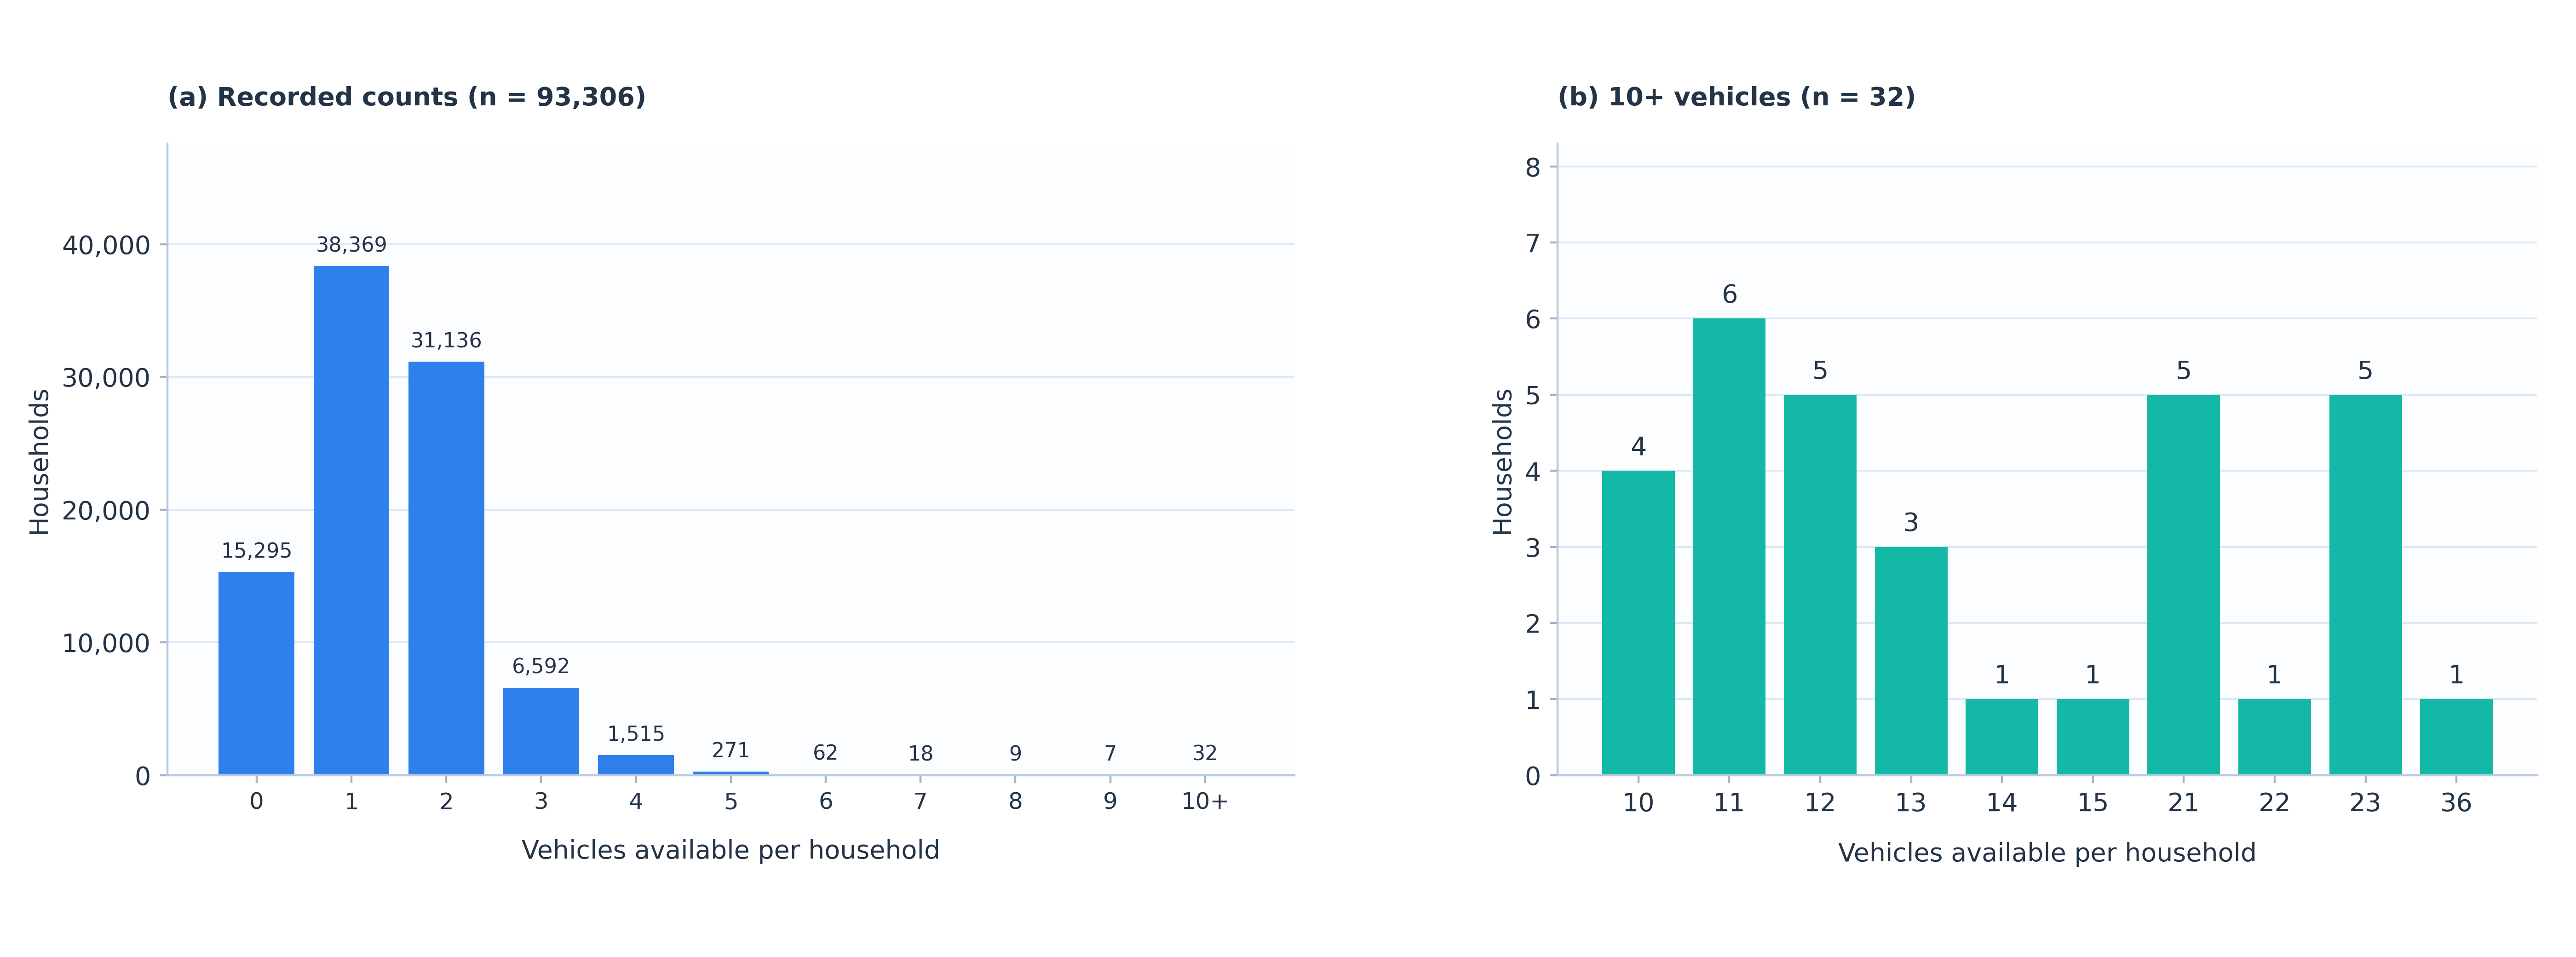

In [9]:
stats = {'vehicle_numeric_plot_records': int(known_vehicles.sum()),
         'vehicle_unknown_99': int(vehicle_values.eq(99).sum()),
         'source_records': len(raw), 'vehicle_other_unplotted_records': 0}
counts = vehicle_frequencies.set_index("raw_vehicle_count")["households"]
tail = counts[counts.index >= HIGH_VEHICLE]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
fig.subplots_adjust(left=.065, right=.985, bottom=.19, top=.85, wspace=.25)
main_values = [int(counts.get(k, 0)) for k in range(HIGH_VEHICLE)] + [int(tail.sum())]
bars = axes[0].bar(range(len(main_values)), main_values, color=BLUE)
axes[0].set_xticks(range(len(main_values)), [str(k) for k in range(HIGH_VEHICLE)] + ["10+"])
axes[0].tick_params(axis="x", labelsize=9)
axes[0].bar_label(bars, labels=[f"{v:,}" if v else "" for v in main_values], padding=4, fontsize=8, rotation=0)
axes[0].set_ylim(0, max(main_values, default=1) * 1.24 + 1)
axes[0].set_title(
    f"(a) Recorded counts (n = {int(stats['vehicle_numeric_plot_records']):,})",
    loc="left", fontsize=10, fontweight="bold", color=INK, pad=15,
)
axes[0].set_xlabel("Vehicles available per household", labelpad=10)
axes[0].set_ylabel("Households")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
if not tail.empty:
    positions = np.arange(len(tail))
    bars = axes[1].bar(positions, tail.values, color=AQUA)
    axes[1].set_xticks(positions, [str(v) for v in tail.index])
    axes[1].bar_label(bars, padding=4, fontsize=10)
    axes[1].set_ylim(0, float(tail.max()) * 1.3 + .5)
else:
    axes[1].text(.5, .5, "No numerical values of 10 or more", ha="center", transform=axes[1].transAxes)
    axes[1].set_xticks([])
axes[1].set_title(
    f"(b) 10+ vehicles (n = {int(tail.sum()):,})",
    loc="left", fontsize=10, fontweight="bold", color=INK, pad=15,
)
axes[1].set_xlabel("Vehicles available per household", labelpad=10)
axes[1].set_ylabel("Households")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes:
    style_axes(ax)

save_figure(fig, 'S1_vehicle_frequencies')

## 5. Data cleaning

In [10]:
def category(counts, top):
    """Create text categories while preserving missing values as missing."""
    result = counts.astype('Int64').astype('string')
    return result.mask(counts.ge(top).fillna(False), f'{top}+')

master = raw.copy()
# Source order is retained so each numeric series still refers to its raw row.
n = raw_numeric.reset_index(drop=True)
master['unknown_vehicle'] = n['nvehicle'].eq(99)
master['unknown_dwelling'] = n['dwelltype'].eq(9)
master['unknown_advance_letter'] = raw['rec-mail'].astype('string').eq('9').to_numpy()
master['nvehicle_clean'] = n['nvehicle'].mask(master['unknown_vehicle']).astype('Int64')
master['dwelltype_clean'] = n['dwelltype'].mask(master['unknown_dwelling']).astype('Int64')
master['rec_mail_clean'] = raw['rec-mail'].astype('string').mask(master['unknown_advance_letter'])
master['workers'] = (n['nempft'] + n['nemppt']).astype('Int64')
master['high_vehicle'] = master['nvehicle_clean'].ge(HIGH_VEHICLE).fillna(False)
master['zero_trip'] = n['nhhldtrip'].eq(0)
master['home_double_count_exceeds_size'] = master['workers'] + n['nemphome'] > n['nperson']
master['workers_students_exceed_size'] = master['workers'] + n['nstudent'] > n['nperson']
master['eligible_core'] = ~master['unknown_vehicle']
# Completeness flags describe possible future model samples, not EDA exclusions.
# No final regression eligibility rule has been selected.
master['eligible_comparison'] = master['eligible_core'] & ~master['unknown_dwelling']
master['eligible_high_vehicle_sensitivity'] = master['eligible_comparison'] & ~master['high_vehicle']
master['ineligible_core_reason'] = np.where(master['unknown_vehicle'], 'unknown_vehicle', '')
master['ineligible_comparison_reason'] = [
    ';'.join(reason for flag, reason in [(v, 'unknown_vehicle'), (d, 'unknown_dwelling')] if flag)
    for v, d in zip(master['unknown_vehicle'], master['unknown_dwelling'])]
master['size_cat_proposed'] = category(n['nperson'], SIZE_TOP)
master['veh_cat_proposed'] = category(master['nvehicle_clean'], VEHICLE_TOP)
master['veh_cat_alternative'] = category(master['nvehicle_clean'], ALTERNATIVE_VEHICLE_TOP)
master['dwelling'] = n['dwelltype'].map({1: 'House', 2: 'Apartment', 3: 'Townhouse', 9: 'Unknown'})
master['weekday'] = n['tripday'].map(dict(enumerate(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], start=1)))
master['region'] = ''
for name, (low, high) in ZONES.items():
    master.loc[n['gta01hhld'].between(low, high), 'region'] = name

analysis = master.copy()
print(f'Full-dataset EDA: {len(analysis):,} households retained; no rows excluded.')
print(f'Unavailable values: {master["unknown_vehicle"].sum():,} vehicle count; '
      f'{master["unknown_dwelling"].sum():,} dwelling codes retained as Unknown.')
assert len(analysis) == len(raw), 'EDA must retain every supplied household.'

Full-dataset EDA: 93,307 households retained; no rows excluded.
Unavailable values: 1 vehicle count; 9 dwelling codes retained as Unknown.


## 6. Full-dataset analysis and preserved historical files

All supplied households are used for EDA, with available-value denominators for each variable. The original workbook and historical split assignment, training, testing, and split-summary files are preserved without modification. They are not read or used to select the current analysis sample. Existing completeness flags are diagnostic only; final modeling exclusions remain undecided.

In [11]:
assert master[FIELDS].equals(raw.reset_index(drop=True)), 'Original fields changed during preparation.'
master.to_csv(PREPARED_FILE, index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.15g')
show(pd.DataFrame({'Sample': ['Full supplied dataset'], 'Households': [len(analysis)],
                   'Rows excluded from EDA': [0]}))

,Sample,Households,Rows excluded from EDA
0,Full supplied dataset,93307,0


### Derived variables and preparation flags

In [12]:
derived = {
    'nvehicle_clean': 'nvehicle with provisional unknown 99 set to missing',
    'dwelltype_clean': 'dwelltype with unknown 9 set to missing',
    'rec_mail_clean': 'Advance-letter text with unknown 9 set to missing',
    'workers': 'nempft + nemppt; home workers are not added again',
    'unknown_vehicle': 'Raw nvehicle equals 99',
    'unknown_dwelling': 'Raw dwelltype equals 9',
    'unknown_advance_letter': 'Raw rec-mail equals code 9; no eligibility exclusion',
    'high_vehicle': 'Known vehicle count at least 10; flag, not automatic deletion',
    'zero_trip': 'Recorded trips equal zero; retain',
    'home_double_count_exceeds_size': 'workers + nemphome exceeds nperson; informational',
    'workers_students_exceed_size': 'workers + nstudent exceeds nperson; overlapping statuses',
    'eligible_core': 'Known vehicles; provisional completeness flag only',
    'eligible_comparison': 'Known vehicles and dwelling; provisional complete-case flag only',
    'eligible_high_vehicle_sensitivity': 'Known vehicles/dwelling and fewer than 10 vehicles; sensitivity flag only',
    'ineligible_core_reason': 'Reason vehicle completeness flag is false; not a final exclusion',
    'ineligible_comparison_reason': 'Completeness issues separated by semicolon; not final exclusions',
    'size_cat_proposed': '1,2,3,4,5+; proposal for EDA, not a final model boundary',
    'veh_cat_proposed': '0,1,2,3+; unknown remains missing',
    'veh_cat_alternative': '0,1,2,3,4+; unknown remains missing',
    'dwelling': 'Descriptive label, including Unknown; not numeric model coding',
    'weekday': 'Descriptive Monday-Friday label',
    'region': 'Region inferred from documented zone ranges',
}

derived_dictionary = pd.DataFrame([
    {'Field': field,
     'Type': 'Flag' if pd.api.types.is_bool_dtype(master[field]) else 'Derived',
     'Definition': definition, 'Role': 'Preparation or analysis'}
    for field, definition in derived.items()
])
dictionary = pd.concat([original_dictionary, derived_dictionary], ignore_index=True)
dictionary.to_csv(TABLES / 'DP01_data_dictionary.csv', index=False)
show(derived_dictionary[['Field', 'Definition']])

,Field,Definition
0,nvehicle_clean,nvehicle with provisional unknown 99 set to mi...
1,dwelltype_clean,dwelltype with unknown 9 set to missing
2,rec_mail_clean,Advance-letter text with unknown 9 set to missing
3,workers,nempft + nemppt; home workers are not added again
4,unknown_vehicle,Raw nvehicle equals 99
5,unknown_dwelling,Raw dwelltype equals 9
6,unknown_advance_letter,Raw rec-mail equals code 9; no eligibility exc...
7,high_vehicle,"Known vehicle count at least 10; flag, not aut..."
8,zero_trip,Recorded trips equal zero; retain
9,home_double_count_exceeds_size,workers + nemphome exceeds nperson; informational


In [13]:
FLAG_DECISIONS = {
    'unknown_vehicle': 'Retained in full EDA; vehicle-specific summaries use available values; model handling undecided',
    'unknown_dwelling': 'Retained as Unknown in full EDA; model handling undecided',
    'unknown_advance_letter': 'Retained; survey-process field is not a substantive predictor',
    'high_vehicle': 'Retained in main samples; flagged for a possible later sensitivity check',
    'zero_trip': 'Retained; no exclusion based on zero trips',
    'home_double_count_exceeds_size': 'Retained; do not add home workers to full- and part-time totals',
    'workers_students_exceed_size': 'Retained; employment and student statuses may overlap',
}

flags = ['unknown_vehicle', 'unknown_dwelling', 'unknown_advance_letter',
         'high_vehicle', 'zero_trip', 'home_double_count_exceeds_size', 'workers_students_exceed_size']
flag_table = pd.DataFrame([{'Flag': f, 'Households': int(master[f].sum()),
                            'Definition': derived[f], 'Decision': FLAG_DECISIONS[f]} for f in flags])
extra_checks = pd.DataFrame([{'Check': r.Flag, 'Flagged records or cells': r.Households,
                              'Status': 'handling recorded',
                              'Note': r.Definition, 'Decision': r.Decision} for r in flag_table.itertuples()])
raw_checks = raw_checks.assign(Decision='Stop before writing if this check is nonzero')
checks = pd.concat([raw_checks, extra_checks], ignore_index=True)

show(flag_table[['Flag', 'Households', 'Decision']])
checks.to_csv(INTERMEDIARIES / 'DP02_quality_checks.csv', index=False)
flag_table.to_csv(INTERMEDIARIES / 'DP05_preparation_flags.csv', index=False)

,Flag,Households,Decision
0,unknown_vehicle,1,Retained in full EDA; vehicle-specific summari...
1,unknown_dwelling,9,Retained as Unknown in full EDA; model handlin...
2,unknown_advance_letter,576,Retained; survey-process field is not a substa...
3,high_vehicle,32,Retained in main samples; flagged for a possib...
4,zero_trip,10480,Retained; no exclusion based on zero trips
5,home_double_count_exceeds_size,3702,Retained; do not add home workers to full- and...
6,workers_students_exceed_size,6533,Retained; employment and student statuses may ...


## 7. Sample flow

In [14]:
masks = {
    'Full dataset (main EDA)': pd.Series(True, index=master.index),
    'Known vehicle count (diagnostic only)': master['eligible_core'],
    'Known vehicle and dwelling (diagnostic only)': master['eligible_comparison'],
    'Known vehicle/dwelling, fewer than 10 vehicles (sensitivity only)': master['eligible_high_vehicle_sensitivity'],
}
sample_summary = pd.DataFrame([
    {'Cohort': name, 'Households': int(mask.sum()),
     'Zones represented': master.loc[mask, 'gta01hhld'].nunique(),
     'Use': 'Main EDA; no exclusions' if name.startswith('Full') else 'Provisional diagnostic; not a final model sample'}
    for name, mask in masks.items()
])
flow = pd.DataFrame([
    ('Supplied households', len(raw), 'Original workbook preserved'),
    ('Prepared master and main EDA', len(master), 'All supplied rows retained; unknowns recoded or labeled'),
    ('Unavailable vehicle count', int(master['unknown_vehicle'].sum()), 'Omitted only from calculations requiring numeric vehicles'),
    ('Unknown dwelling code', int(master['unknown_dwelling'].sum()), 'Shown as Unknown; no row exclusion'),
    ('High vehicle count', int(master['high_vehicle'].sum()), 'Retained; sensitivity analysis only'),
], columns=['View or issue', 'Households', 'Handling'])
zones = master.groupby('gta01hhld', sort=True).agg(
    households=('hnum', 'size'), known_vehicle_households=('nvehicle_clean', 'count'),
    known_dwelling_households=('dwelltype_clean', 'count'))
zones['both_known_households'] = master.loc[master['eligible_comparison']].groupby('gta01hhld').size().reindex(zones.index, fill_value=0)
show(flow)
show(sample_summary)
flow.to_csv(TABLES / 'DP03_sample_flow.csv', index=False)
sample_summary.to_csv(TABLES / 'DP04_sample_summary.csv', index=False)
zones.reset_index().to_csv(INTERMEDIARIES / 'DP06_zone_coverage.csv', index=False)

,View or issue,Households,Handling
0,Supplied households,93307,Original workbook preserved
1,Prepared master and main EDA,93307,All supplied rows retained; unknowns recoded o...
2,Unavailable vehicle count,1,Omitted only from calculations requiring numer...
3,Unknown dwelling code,9,Shown as Unknown; no row exclusion
4,High vehicle count,32,Retained; sensitivity analysis only


,Cohort,Households,Zones represented,Use
0,Full dataset (main EDA),93307,1179,Main EDA; no exclusions
1,Known vehicle count (diagnostic only),93306,1179,Provisional diagnostic; not a final model sample
2,Known vehicle and dwelling (diagnostic only),93297,1179,Provisional diagnostic; not a final model sample
3,"Known vehicle/dwelling, fewer than 10 vehicles...",93265,1179,Provisional diagnostic; not a final model sample


### EDA sample and denominators

The main sample contains every supplied household. Numeric summaries use nonmissing values for that variable. Dwelling Unknown is displayed explicitly. Joint analyses involving vehicles require a known vehicle count and state that denominator separately. No final modeling sample is selected here.

In [15]:
tables = {'ED01_sample_reconciliation': sample_summary}
print(f'Characteristics and trip EDA: {len(analysis):,} households, with no training/test partition.')
assert set(analysis['hnum']) == set(raw['hnum']), 'The full household sample must be retained.'

Characteristics and trip EDA: 93,307 households, with no training/test partition.


## 8. Expected relationships

In [16]:
EXPECTATIONS = {
    'nperson': ('Generally positive; increments need not be constant', 'Literature supported'),
    'nvehicle_clean': ('Generally positive; increments need not be constant', 'Literature supported'),
    'nlicence': ('Generally positive through mobility access', 'Reasoned'),
    'nempft': ('Generally positive for total trips, with possible offsets', 'Partly reasoned'),
    'nemppt': ('Generally positive for total trips, with possible offsets', 'Partly reasoned'),
    'nemphome': ('No direction conditional on full-time and part-time counts', 'No signed expectation'),
    'nstudent': ('Generally positive through education and escort needs', 'Reasoned'),
    'dwelling': ('No predetermined ranking', 'No signed expectation'),
    'weekday': ('No predetermined ranking', 'No signed expectation'),
}
show(pd.DataFrame.from_dict(EXPECTATIONS, orient='index', columns=['Expectation', 'Basis']))

,Expectation,Basis
nperson,Generally positive; increments need not be con...,Literature supported
nvehicle_clean,Generally positive; increments need not be con...,Literature supported
nlicence,Generally positive through mobility access,Reasoned
nempft,"Generally positive for total trips, with possi...",Partly reasoned
nemppt,"Generally positive for total trips, with possi...",Partly reasoned
nemphome,No direction conditional on full-time and part...,No signed expectation
nstudent,Generally positive through education and escor...,Reasoned
dwelling,No predetermined ranking,No signed expectation
weekday,No predetermined ranking,No signed expectation


## 9. Descriptive statistics

In [17]:
def capped(series, cap):
    return series.clip(upper=cap).astype('Int64')


def ticks(values, cap):
    return [f'{v}+' if v == cap else str(v) for v in values]

In [18]:
numeric_rows, profiles = [], []
cohorts = {'Full dataset (available values)': analysis}
for sample, frame in cohorts.items():
    for field in COUNTS + ['expf']:
        numeric_rows.append({'sample': sample, 'variable': field, 'characteristic': LABELS[field],
                        **descriptive(frame[field])})
    for field in COUNTS + list(ORDERS):
        counts = frame[field].value_counts().sort_index()
        if field in ORDERS:
            counts = counts.reindex(ORDERS[field], fill_value=0)
        profiles.extend({'sample': sample, 'variable': field, 'characteristic': LABELS[field],
                         'level': str(level), 'n': int(n), 'percent': 100 * n / len(frame),
                         'source_n': len(frame), 'available_n': int(frame[field].notna().sum()),
                         'missing_n': int(frame[field].isna().sum())}
                        for level, n in counts.items())

tables['ED02_numeric_descriptives'] = pd.DataFrame(numeric_rows)
tables['ED02_numeric_descriptives'].to_csv(TABLES / 'ED02_numeric_descriptives.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
tables['ED03_characteristic_profiles'] = pd.DataFrame(profiles)
tables['ED03_characteristic_profiles'].to_csv(TABLES / 'ED03_characteristic_profiles.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED02_numeric_descriptives'])
show(tables['ED03_characteristic_profiles'].head(15))

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
0,Full dataset (available values),nperson,Household size,93307,2.741177,1.418985,1.00,2.00,2.00,4.00,16.00,0,0.000000
1,Full dataset (available values),nvehicle_clean,Vehicles available,93306,1.382301,0.974636,0.00,1.00,1.00,2.00,36.00,15295,16.392301
2,Full dataset (available values),nlicence,Licensed drivers,93307,1.730095,0.982728,0.00,1.00,2.00,2.00,9.00,8964,9.606996
3,Full dataset (available values),nempft,Full-time workers,93307,1.113025,0.926627,0.00,0.00,1.00,2.00,7.00,27902,29.903437
4,Full dataset (available values),nemppt,Part-time workers,93307,0.238235,0.511955,0.00,0.00,0.00,0.00,5.00,74410,79.747500
5,Full dataset (available values),nemphome,Home workers,93307,0.108041,0.354863,0.00,0.00,0.00,0.00,7.00,84512,90.574126
6,Full dataset (available values),nstudent,Students,93307,0.635151,0.953827,0.00,0.00,0.00,1.00,9.00,57826,61.973914
7,Full dataset (available values),workers,Total workers,93307,1.351260,1.049564,0.00,1.00,1.00,2.00,10.00,22980,24.628377
8,Full dataset (available values),expf,Expansion factor,93307,19.383845,2.508741,10.83,17.67,19.35,20.98,28.06,0,0.000000


,sample,variable,characteristic,level,n,percent,source_n,available_n,missing_n
0,Full dataset (available values),nperson,Household size,1,19200,20.577234,93307,93307,0
1,Full dataset (available values),nperson,Household size,2,28820,30.887286,93307,93307,0
2,Full dataset (available values),nperson,Household size,3,17476,18.729570,93307,93307,0
3,Full dataset (available values),nperson,Household size,4,17472,18.725283,93307,93307,0
4,Full dataset (available values),nperson,Household size,5,7002,7.504260,93307,93307,0
5,Full dataset (available values),nperson,Household size,6,2326,2.492846,93307,93307,0
6,Full dataset (available values),nperson,Household size,7,662,0.709486,93307,93307,0
7,Full dataset (available values),nperson,Household size,8,221,0.236853,93307,93307,0
8,Full dataset (available values),nperson,Household size,9,70,0.075021,93307,93307,0
9,Full dataset (available values),nperson,Household size,10,36,0.038582,93307,93307,0


In [19]:
caps = [{'variable': f, 'last_category': f'{CAPS[f]} or more',
         'full_dataset_n_in_last_category': int(analysis[f].ge(CAPS[f]).sum()),
         'purpose': 'Display only; exact counts retained; no model boundary fixed'} for f in COUNTS]
caps.append({'variable': 'nhhldtrip', 'last_category': f'{TRIP_CAP} or more',
             'full_dataset_n_in_last_category': int(analysis['nhhldtrip'].ge(TRIP_CAP).sum()),
             'purpose': 'Distribution display only; summaries use original trip counts'})
tables['ED13_display_boundaries'] = pd.DataFrame(caps)
tables['ED13_display_boundaries'].to_csv(INTERMEDIARIES / 'ED13_display_boundaries.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

### Household characteristics

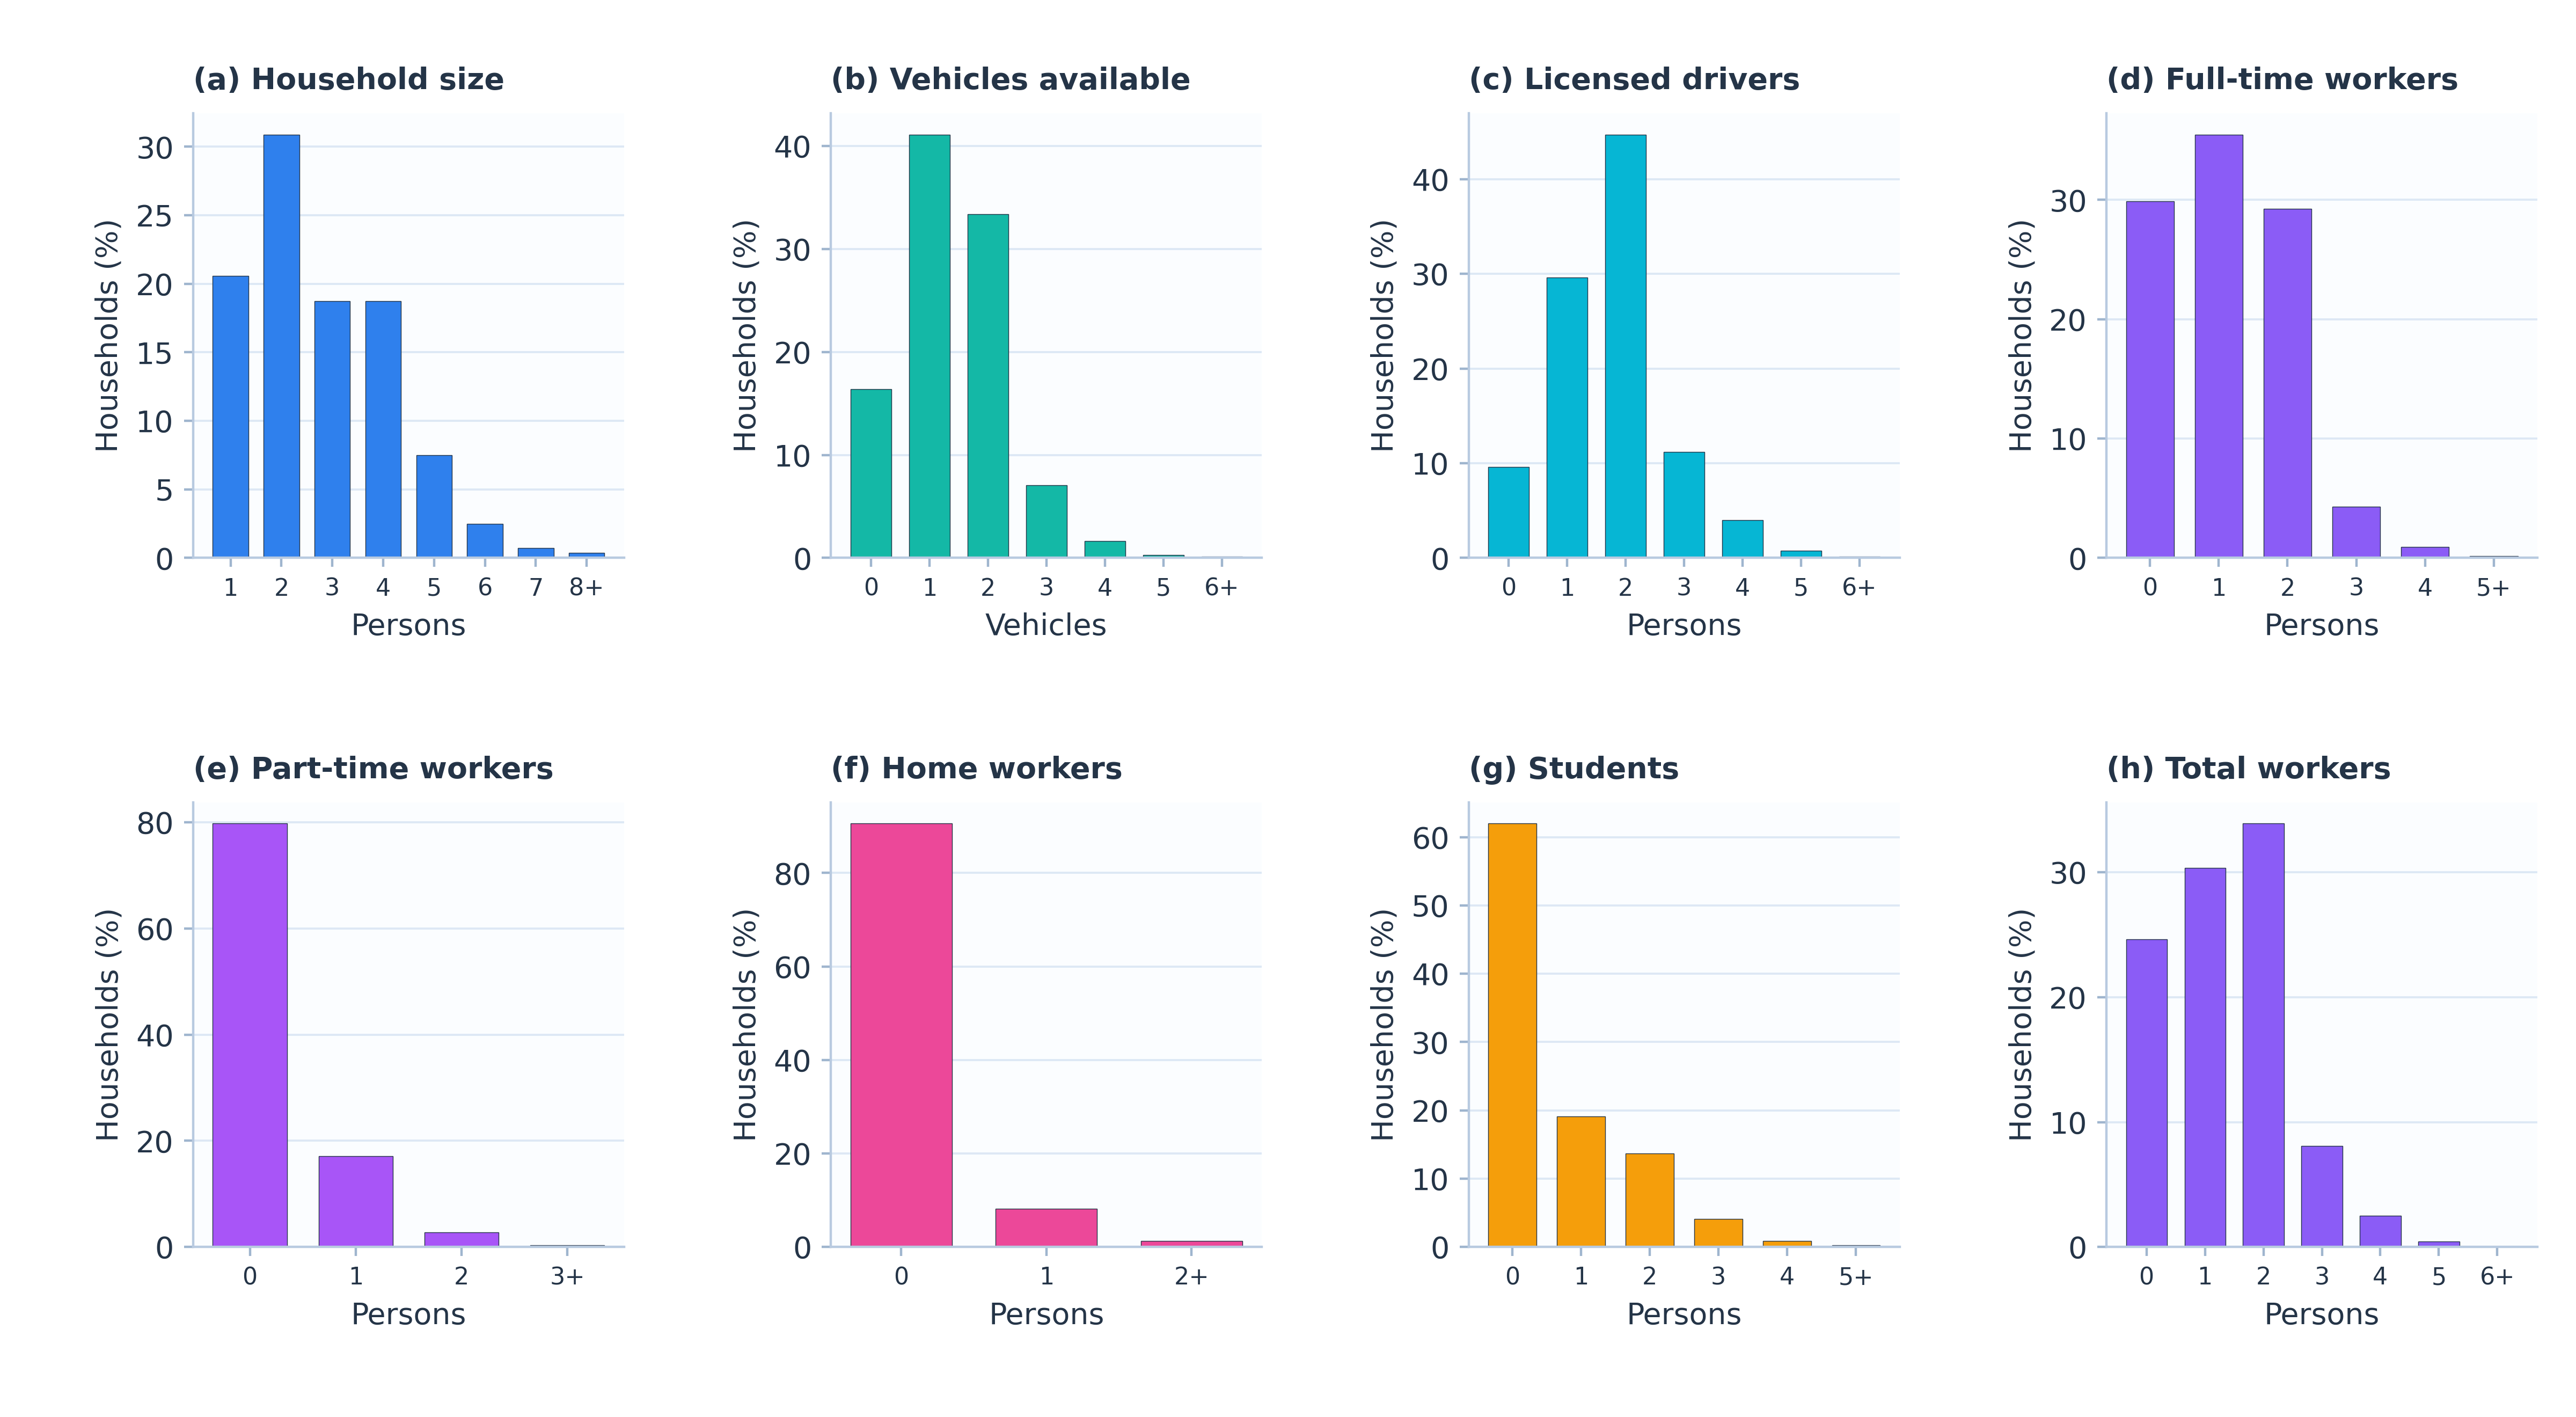

In [20]:
# ED02: predictor-only full-dataset profiles; eight panels in two rows.
fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
fig.subplots_adjust(left=.075, right=.985, bottom=.12, top=.92, wspace=.48, hspace=.55)
for i, field in enumerate(COUNTS):
    ax = axes.flat[i]
    freq = capped(analysis[field], CAPS[field]).value_counts().sort_index()
    ax.bar(range(len(freq)), 100 * freq / len(analysis), color=COLOURS[field], width=.7,
           edgecolor=INK, linewidth=.25)
    ax.set_xticks(range(len(freq)), ticks(freq.index, CAPS[field]), fontsize=8)
    ax.set_xlabel('Persons' if field != 'nvehicle_clean' else 'Vehicles')
    ax.set_ylabel('Households (%)')
    panel(ax, f'({chr(97+i)}) {LABELS[field]}')
    style_axes(ax)
save_figure(fig, 'Figure_ED02')

### Full-dataset trip distribution

In [21]:
numeric_rows.append({'sample': 'Full dataset (available values)', 'variable': 'nhhldtrip',
                'characteristic': LABELS['nhhldtrip'], **descriptive(analysis['nhhldtrip'])})
tables['ED02_numeric_descriptives'] = pd.DataFrame(numeric_rows)
tables['ED02_numeric_descriptives'].to_csv(TABLES / 'ED02_numeric_descriptives.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
trips = analysis['nhhldtrip'].value_counts().reindex(range(int(analysis['nhhldtrip'].max()) + 1),
                                                  fill_value=0).sort_index()
tables['ED04_trip_distribution'] = pd.DataFrame(
    {'trips': trips.index, 'n': trips.values, 'percent': 100 * trips.values / len(analysis)})
tables['ED04_trip_distribution'].to_csv(TABLES / 'ED04_trip_distribution.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')


show(tables['ED02_numeric_descriptives'].query('variable == "nhhldtrip"'))
show(tables['ED04_trip_distribution'])

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
9,Full dataset (available values),nhhldtrip,Weekday household trips,93307,5.643253,4.562479,0.0,2.0,4.0,8.0,55.0,10480,11.23174


,trips,n,percent
0,0,10480,11.231740
1,1,400,0.428692
2,2,16214,17.377046
3,3,4039,4.328721
4,4,16286,17.454210
5,5,4555,4.881734
6,6,11190,11.992669
7,7,3755,4.024350
8,8,7500,8.037982
9,9,2959,3.171252


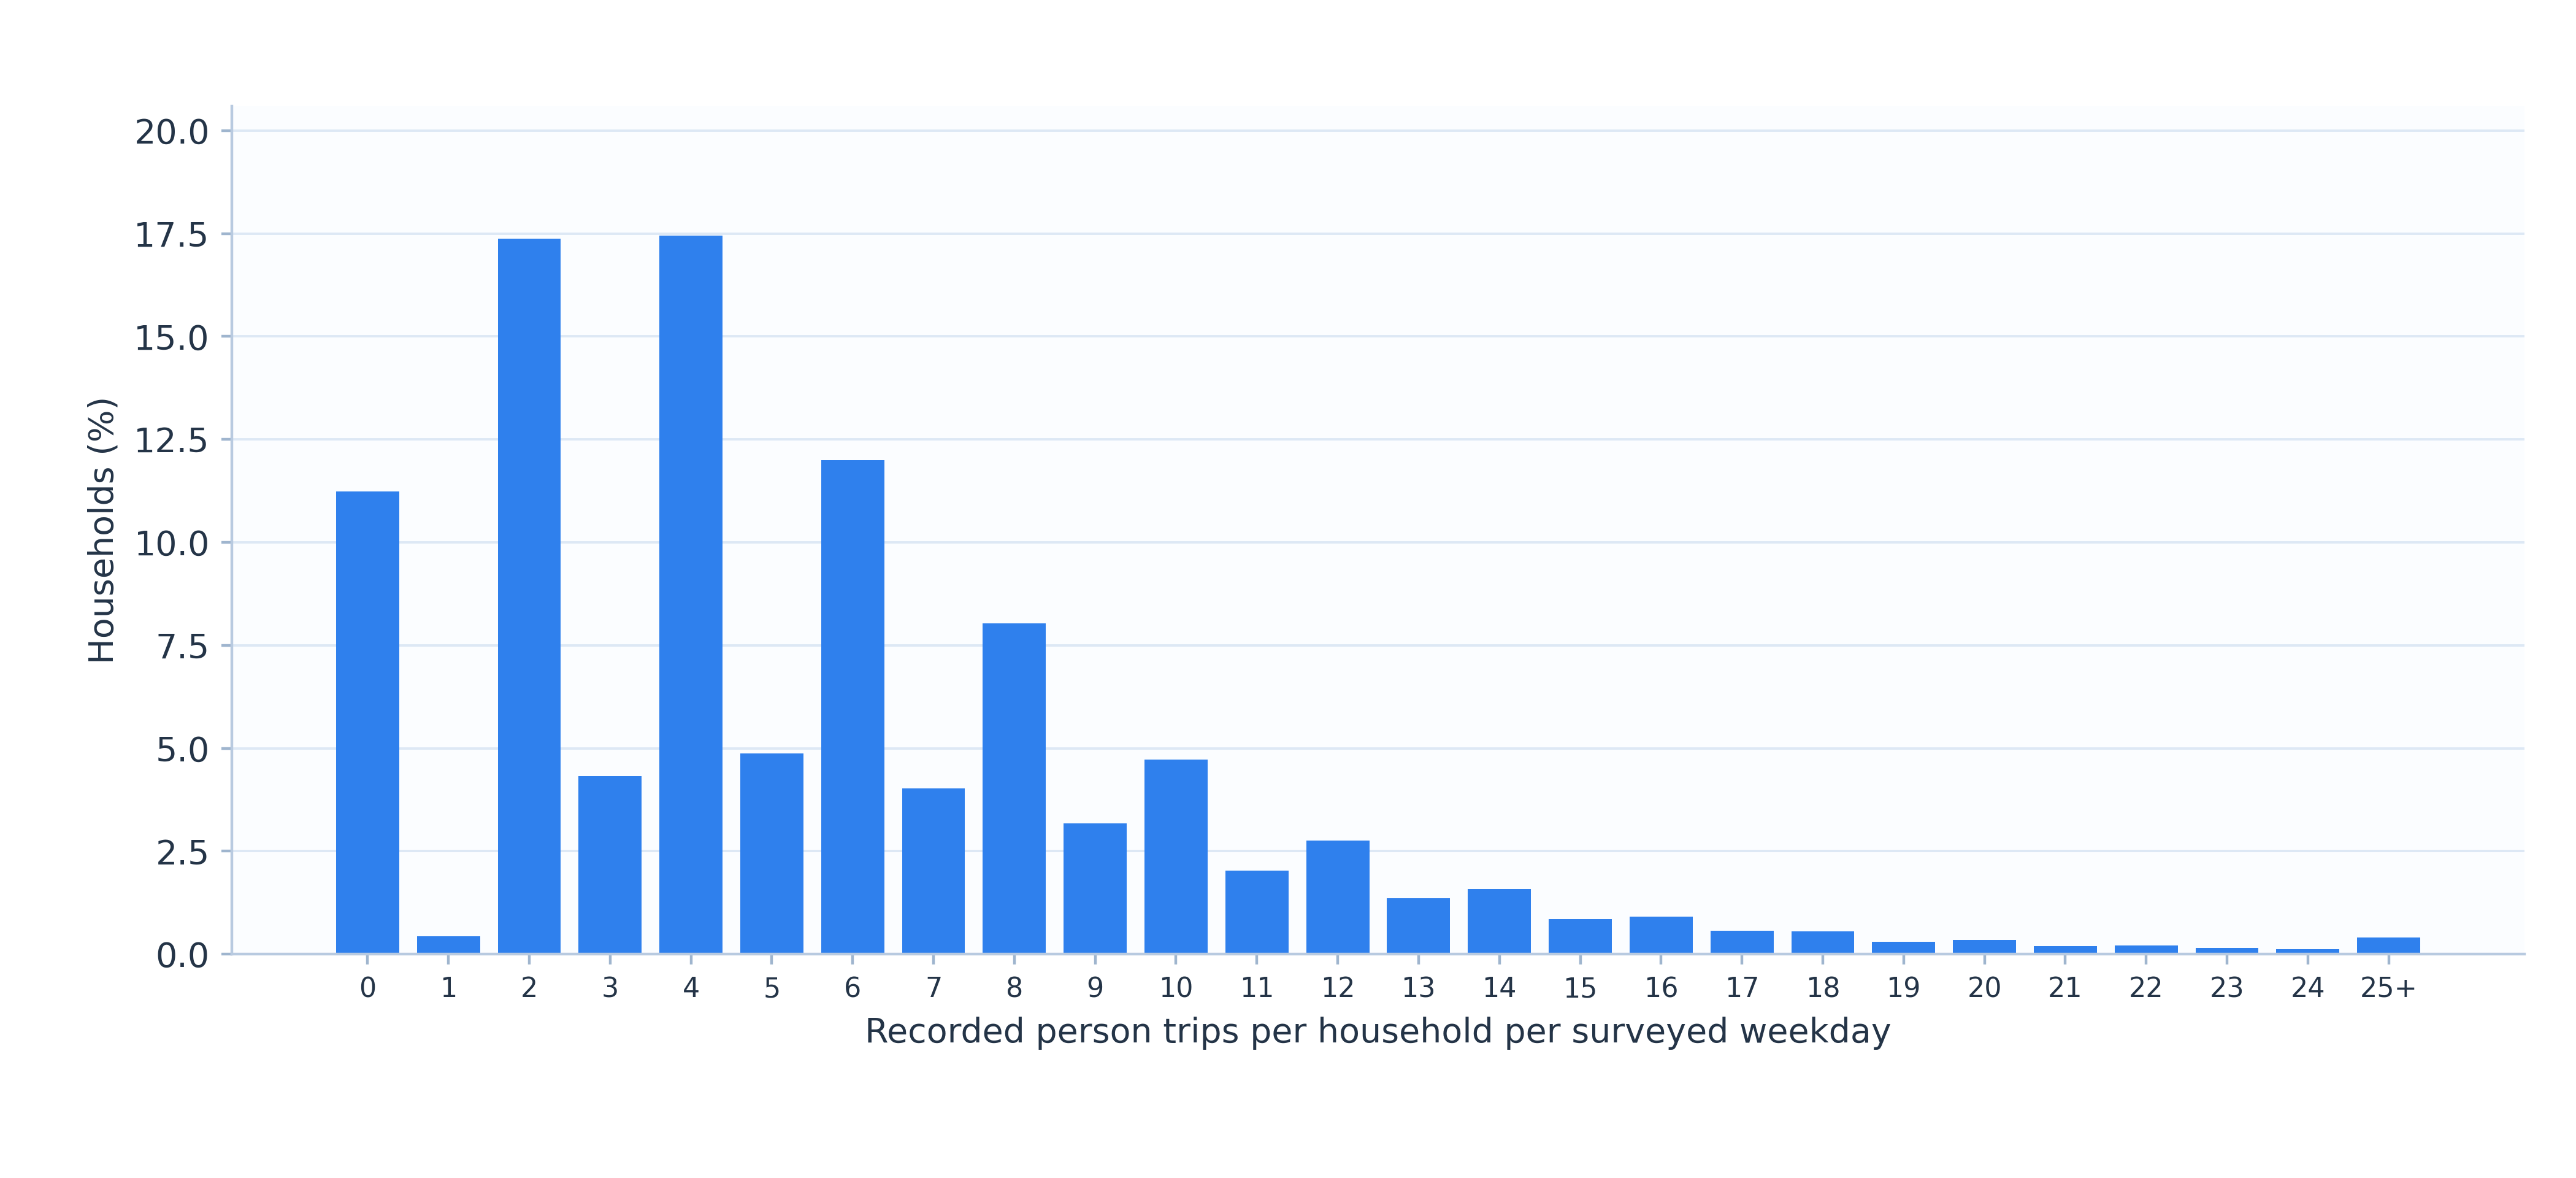

In [22]:
# ED01: discrete distribution; tail aggregation does not alter any statistic.
fig, ax = plt.subplots(figsize=(10.5, 4.8))
fig.subplots_adjust(left=.09, right=.98, bottom=.19, top=.91)
dist = capped(analysis['nhhldtrip'], TRIP_CAP).value_counts().reindex(range(TRIP_CAP + 1), fill_value=0)
pct = 100 * dist / len(analysis)
ax.bar(dist.index, pct, color=BLUE, width=.78)
ax.set_xticks(range(TRIP_CAP + 1), ticks(range(TRIP_CAP + 1), TRIP_CAP), fontsize=8)
ax.set_xlabel('Recorded person trips per household per surveyed weekday')
ax.set_ylabel('Households (%)')
ax.set_ylim(0, pct.max() * 1.18)
style_axes(ax)
save_figure(fig, 'Figure_ED01')

## 10. Trips by household characteristics

In [23]:
def group_statistics(frame, fields):
    """One row per observed group: raw n, mean, SD, zero share and weighted mean."""
    data = frame.assign(_weighted_trips=frame['nhhldtrip'] * frame['expf'],
                        _weighted_zero=frame['zero_trip'].astype(float) * frame['expf'])
    result = data.groupby(fields, observed=True, sort=True).agg(
        n=('hnum', 'size'), mean_trips=('nhhldtrip', 'mean'), sd_trips=('nhhldtrip', 'std'),
        median_trips=('nhhldtrip', 'median'), zero_n=('zero_trip', 'sum'),
        weight_sum=('expf', 'sum'), weighted_trip_sum=('_weighted_trips', 'sum'),
        weighted_zero_sum=('_weighted_zero', 'sum'),
    ).reset_index()
    result['zero_pct'] = 100 * result['zero_n'] / result['n']
    result['weighted_mean_trips'] = result['weighted_trip_sum'] / result['weight_sum']
    result['weighted_zero_pct'] = 100 * result['weighted_zero_sum'] / result['weight_sum']
    result['source_n'] = len(frame)
    result['groupable_n'] = int(frame[fields].notna().all(axis=1).sum())
    result['excluded_missing_group_n'] = result['source_n'] - result['groupable_n']
    return result.drop(columns=['weighted_trip_sum', 'weighted_zero_sum'])

def ordered_rates(analysis, field, display=False):
    if display:
        data = analysis.assign(level=capped(analysis[field], CAPS[field]))
    else:
        data = analysis.assign(level=analysis[field])
    result = group_statistics(data, ['level'])
    if field in ORDERS:
        result['level'] = pd.Categorical(result['level'], categories=ORDERS[field], ordered=True)
        result = result.sort_values('level')
    result.insert(0, 'variable', field)
    result.insert(1, 'characteristic', LABELS[field])
    result['display_label'] = [f'{x} or more' if display and x == CAPS[field] else str(x)
                               for x in result['level']]
    return result

exact = pd.concat([ordered_rates(analysis, f) for f in COUNTS + list(ORDERS)],
                  ignore_index=True)
display_rates = pd.concat([ordered_rates(analysis, f, True) for f in COUNTS], ignore_index=True)
tables['ED05_exact_group_trip_rates'] = exact
tables['ED05_exact_group_trip_rates'].to_csv(TABLES / 'ED05_exact_group_trip_rates.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
tables['ED06_display_group_trip_rates'] = display_rates
tables['ED06_display_group_trip_rates'].to_csv(TABLES / 'ED06_display_group_trip_rates.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED05_exact_group_trip_rates'].head(12))
show(exact.loc[exact['variable'].isin(list(ORDERS))])

,variable,characteristic,level,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,display_label
0,nperson,Household size,1,19200,2.028437,1.830440,2.0,5960,372524.41,31.041667,2.029957,30.843335,93307,93307,0,1
1,nperson,Household size,2,28820,4.356003,3.019682,4.0,3678,556786.5,12.761971,4.353723,12.661403,93307,93307,0,2
2,nperson,Household size,3,17476,6.399519,3.660003,6.0,486,338685.87,2.780957,6.387489,2.782561,93307,93307,0,3
3,nperson,Household size,4,17472,8.306777,4.713263,8.0,250,339229.88,1.430861,8.291281,1.445645,93307,93307,0,4
4,nperson,Household size,5,7002,9.794916,5.581172,9.0,78,136353.03,1.113967,9.782848,1.147257,93307,93307,0,5
5,nperson,Household size,6,2326,10.475064,5.823351,10.0,21,45373.08,0.902837,10.447438,0.899498,93307,93307,0,6
6,nperson,Household size,7,662,11.261329,6.378599,10.0,3,12861.99,0.453172,11.271774,0.418209,93307,93307,0,7
7,nperson,Household size,8,221,12.339367,6.854178,11.0,3,4325.23,1.357466,12.326706,1.24294,93307,93307,0,8
8,nperson,Household size,9,70,14.114286,6.645349,14.0,1,1395.19,1.428571,14.090145,1.444964,93307,93307,0,9
9,nperson,Household size,10,36,16.25,10.182267,14.0,0,700.18,0.000000,16.309078,0.0,93307,93307,0,10


,variable,characteristic,level,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,display_label
85,dwelling,Dwelling type,House,58360,6.564873,4.858576,6.0,4636,1118340.69,7.943797,6.583077,7.850841,93307,93307,0,House
86,dwelling,Dwelling type,Apartment,27977,3.621654,3.162584,3.0,5446,552708.23,19.465990,3.631908,19.218545,93307,93307,0,Apartment
87,dwelling,Dwelling type,Townhouse,6961,6.043097,4.145921,6.0,394,137420.01,5.660106,6.044656,5.616118,93307,93307,0,Townhouse
88,dwelling,Dwelling type,Unknown,9,4.444444,4.850544,4.0,4,179.51,44.444444,4.342321,47.345552,93307,93307,0,Unknown
89,weekday,Survey weekday,Monday,16652,5.434963,4.441686,4.0,2060,322860.03,12.370886,5.42733,12.255348,93307,93307,0,Monday
90,weekday,Survey weekday,Tuesday,18273,5.561484,4.491340,4.0,2144,354131.27,11.733158,5.550633,11.67423,93307,93307,0,Tuesday
91,weekday,Survey weekday,Wednesday,17728,5.681634,4.556083,4.0,1970,343367.07,11.112365,5.686271,11.024566,93307,93307,0,Wednesday
92,weekday,Survey weekday,Thursday,19414,5.62321,4.482840,4.0,2055,376263.83,10.585145,5.619172,10.526786,93307,93307,0,Thursday
93,weekday,Survey weekday,Friday,21240,5.863183,4.779573,5.0,2251,412026.24,10.597928,5.864322,10.545773,93307,93307,0,Friday
94,region,Region,Toronto,51612,4.918527,4.188406,4.0,7322,979313.82,14.186623,4.887346,14.209985,93307,93307,0,Toronto


### Household size, vehicles, licensed drivers, and total workers

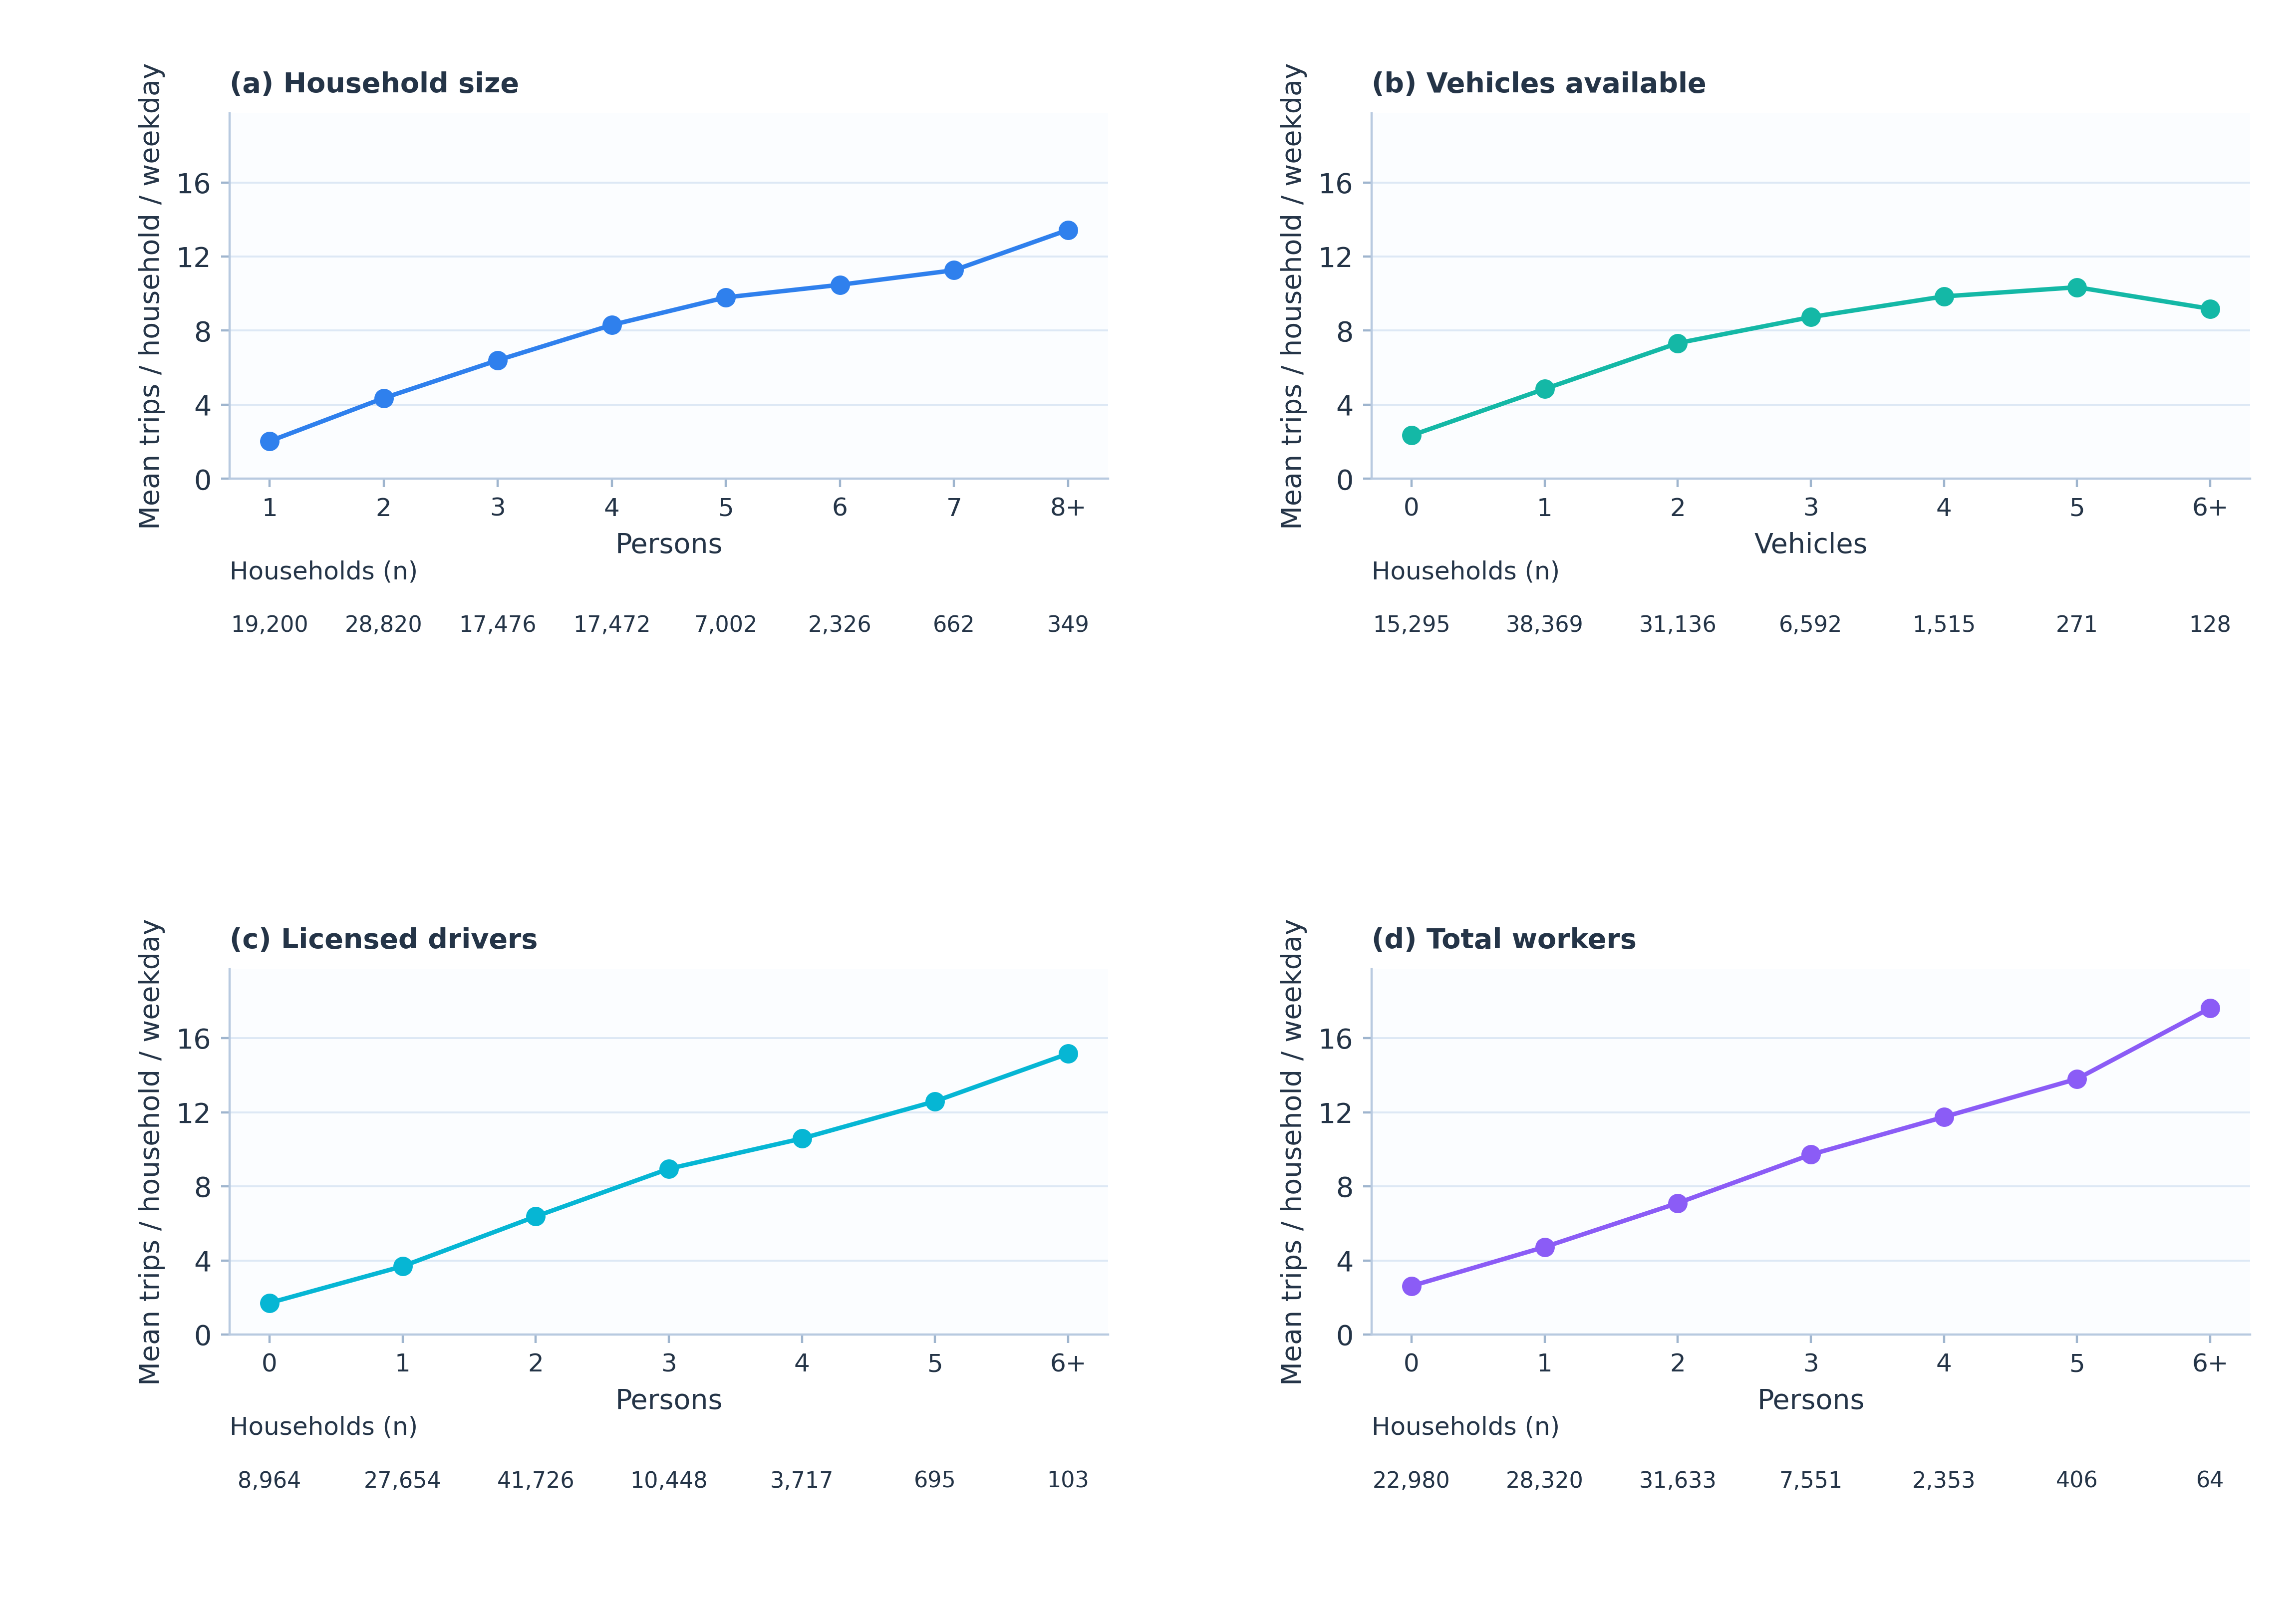

In [24]:
def plot_group_rates(fields, filename):
    """Plot up to four unadjusted trip-rate profiles with household support."""
    fig = plt.figure(figsize=(11.5, 8.1))
    outer = fig.add_gridspec(2, 2, left=.10, right=.98, bottom=.07,
                            top=.93, wspace=.30, hspace=.60)
    y_max = tables['ED06_display_group_trip_rates']['mean_trips'].max() * 1.12
    for i, field in enumerate(fields):
        inner = outer[i // 2, i % 2].subgridspec(2, 1, height_ratios=[4, .7], hspace=.49)
        ax, strip = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        categorical = field in ORDERS
        data = tables['ED05_exact_group_trip_rates' if categorical else 'ED06_display_group_trip_rates']
        data = data.loc[data['variable'].eq(field)]
        x = np.arange(len(data))
        ax.plot(x, data['mean_trips'], 'o' if categorical else 'o-',
                color=COLOURS[field], markersize=6, linewidth=1.6)
        labels = data['level'].astype(str).tolist() if categorical else ticks(data['level'], CAPS[field])
        if field == 'weekday':
            labels = [label[:3] for label in labels]
        ax.set_xticks(x, labels, fontsize=9)
        ax.set_xlabel(LABELS[field] if categorical else 'Vehicles' if field == 'nvehicle_clean' else 'Persons')
        ax.set_ylabel('Mean trips / household / weekday')
        ax.set_ylim(0, y_max)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        panel(ax, f'({chr(97+i)}) {LABELS[field]}')
        style_axes(ax)
        strip.set_xlim(ax.get_xlim())
        strip.set_ylim(0, 1)
        strip.axis('off')
        strip.text(0, 1.0, 'Households (n)', transform=strip.transAxes, fontsize=9, va='bottom')
        for position, count in zip(x, data['n']):
            strip.text(position, .35, f'{count:,}', ha='center', va='center', fontsize=8)
    save_figure(fig, filename)

plot_group_rates(['nperson', 'nvehicle_clean', 'nlicence', 'workers'], 'Figure_ED03')

### Employment and students

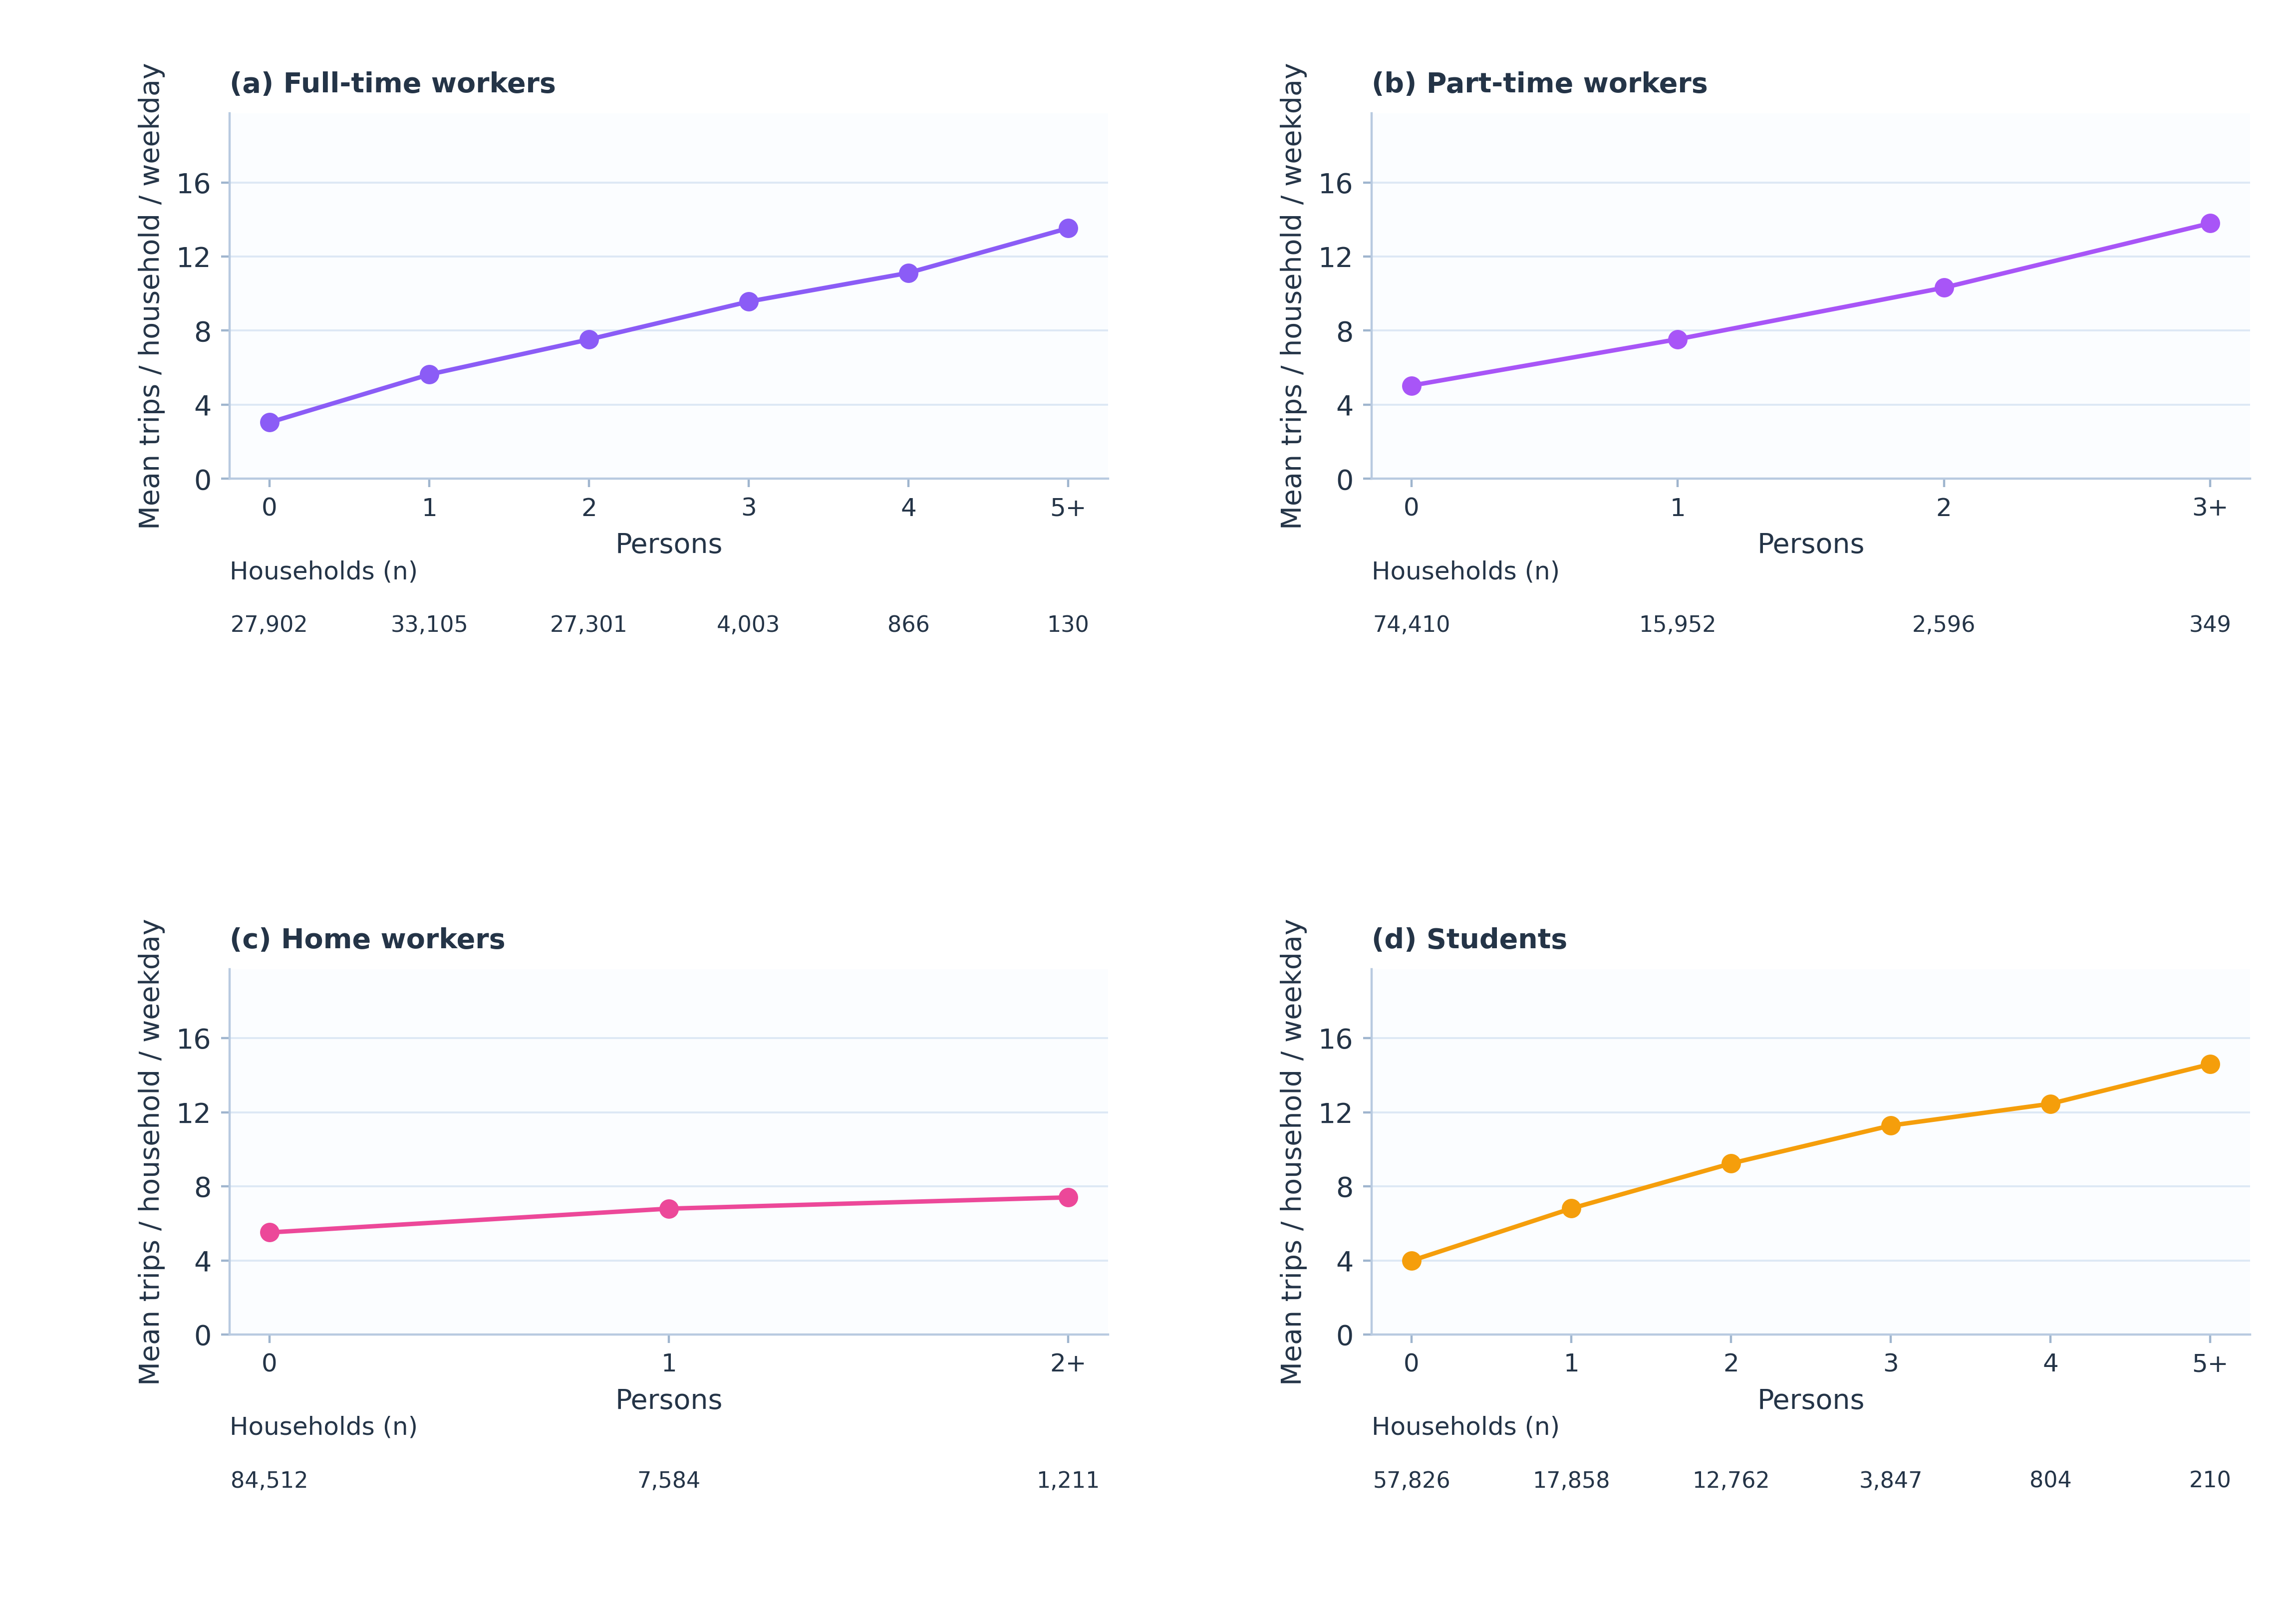

In [25]:
plot_group_rates(COMPOSITION, 'Figure_ED05')

### Dwelling type, survey weekday, and region

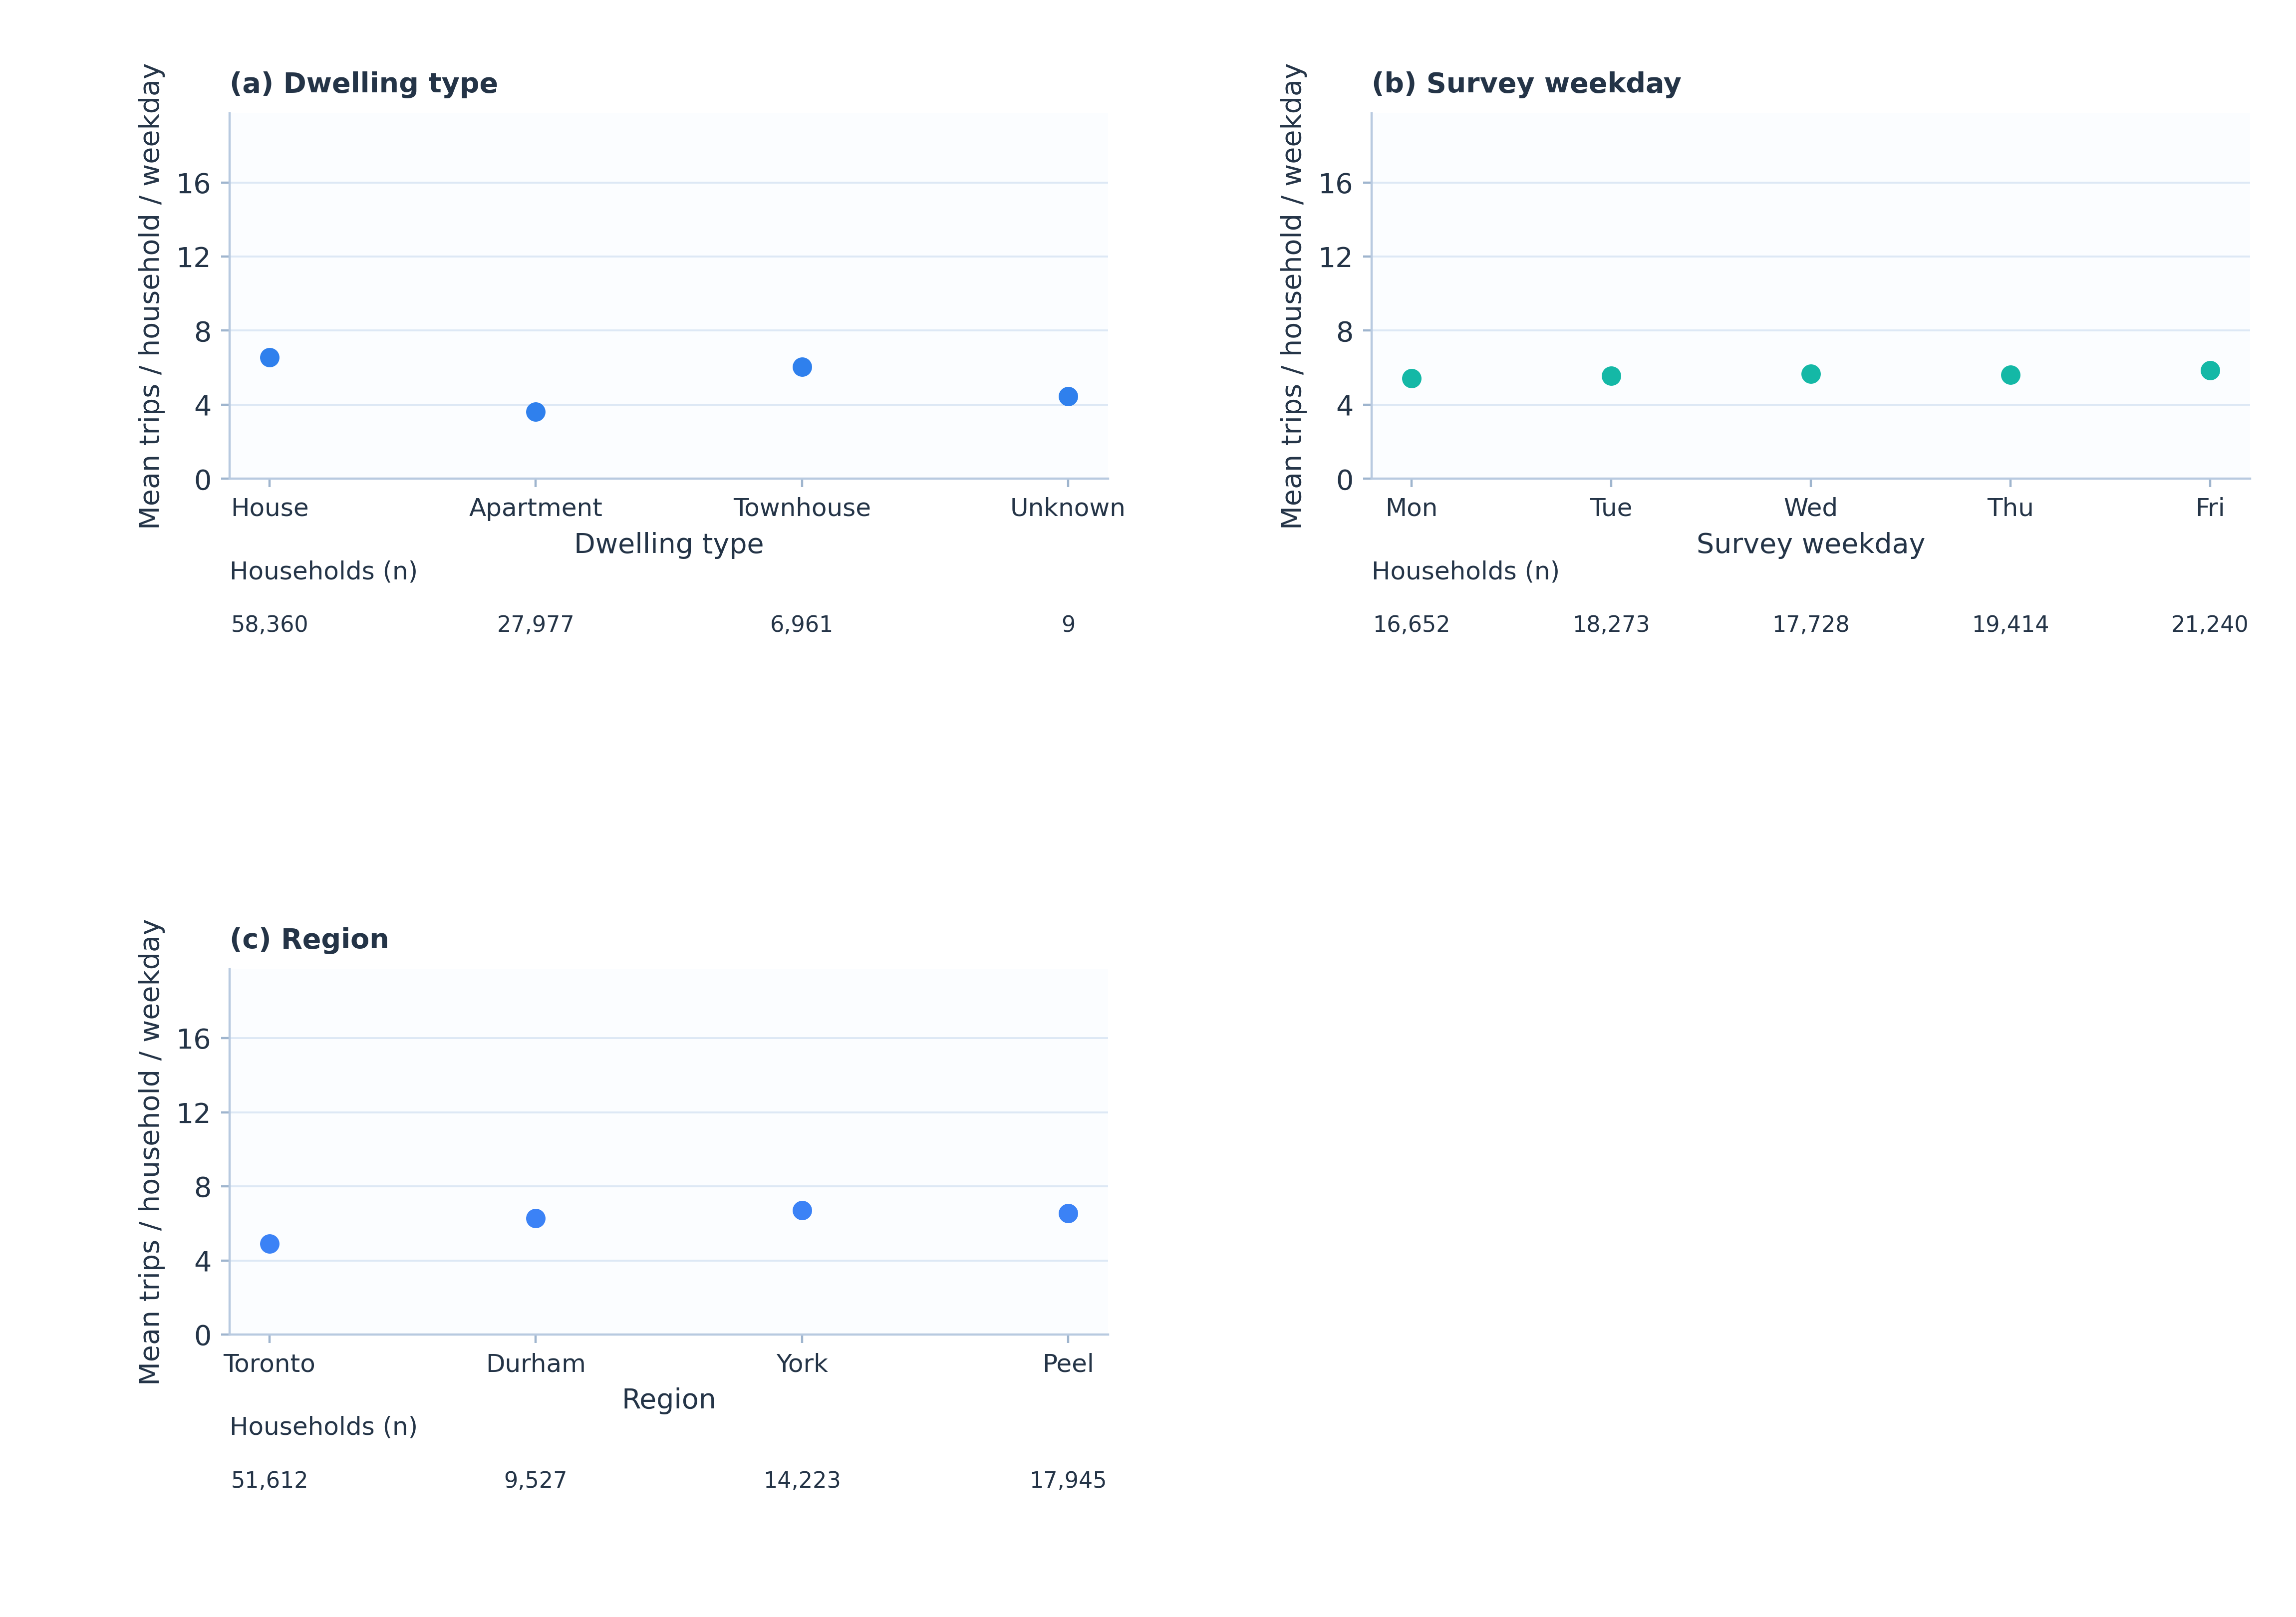

In [26]:
plot_group_rates(['dwelling', 'weekday', 'region'], 'Figure_ED09')

## 11. Joint patterns and sample support

In [27]:
def cell_statistics(analysis, size_cap, vehicle_cap):
    data = analysis.dropna(subset=['nvehicle_clean']).assign(size=capped(analysis['nperson'], size_cap),
                           vehicles=capped(analysis['nvehicle_clean'], vehicle_cap))
    observed = group_statistics(data, ['size', 'vehicles']).set_index(['size', 'vehicles'])
    grid = pd.MultiIndex.from_product([range(1, size_cap + 1), range(vehicle_cap + 1)],
                                     names=['size', 'vehicles'])
    cells = observed.reindex(grid).reset_index()
    for name in ['n', 'zero_n']:
        cells[name] = cells[name].fillna(0).astype(int)
    cells['weight_sum'] = cells['weight_sum'].fillna(0)
    cells['scheme'] = f'{size_cap}+ persons by {vehicle_cap}+ vehicles'
    cells['size_label'] = cells['size'].map(lambda x: f'{x}+' if x == size_cap else str(x))
    cells['vehicle_label'] = cells['vehicles'].map(lambda x: f'{x}+' if x == vehicle_cap else str(x))
    cells['support_below_30'] = cells['n'].lt(SUPPORT_REVIEW_N)
    return cells

cells = pd.concat([cell_statistics(analysis, 5, 3), cell_statistics(analysis, 5, 4)], ignore_index=True)
tables['ED07_classification_cells'] = cells
tables['ED07_classification_cells'].to_csv(TABLES / 'ED07_classification_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
adjacent = []
for scheme, block in cells.groupby('scheme', sort=False):
    for field, fixed in [('size', 'vehicles'), ('vehicles', 'size')]:
        for fixed_value, line in block.groupby(fixed):
            line = line.sort_values(field)
            for (_, left), (_, right) in zip(line.iloc[:-1].iterrows(), line.iloc[1:].iterrows()):
                adjacent.append({'scheme': scheme, 'changing_dimension': field,
                                 'fixed_dimension': fixed, 'fixed_value': fixed_value,
                                 'from_level': int(left[field]), 'to_level': int(right[field]),
                                 'n_from': int(left['n']), 'n_to': int(right['n']),
                                 'mean_difference': right['mean_trips'] - left['mean_trips'],
                                 'weighted_mean_difference': right['weighted_mean_trips'] - left['weighted_mean_trips']})
tables['ED08_adjacent_cell_differences'] = pd.DataFrame(adjacent)
tables['ED08_adjacent_cell_differences'].to_csv(TABLES / 'ED08_adjacent_cell_differences.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED07_classification_cells'])
show(tables['ED08_adjacent_cell_differences'].head(12))

,size,vehicles,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,vehicle_label,support_below_30
0,1,0,8433,1.324558,1.439345,2.0,3955,164242.56,46.899087,1.332406,46.532312,93306,93306,0,5+ persons by 3+ vehicles,1,0,False
1,1,1,9954,2.556359,1.898851,2.0,1883,192573.57,18.917018,2.556572,18.739436,93306,93306,0,5+ persons by 3+ vehicles,1,1,False
2,1,2,671,2.80775,2.029705,2.0,102,12998.29,15.201192,2.816504,15.272009,93306,93306,0,5+ persons by 3+ vehicles,1,2,False
3,1,3,142,3.140845,2.188272,3.0,20,2709.99,14.084507,3.111834,14.789353,93306,93306,0,5+ persons by 3+ vehicles,1,3+,False
4,2,0,4109,2.780239,2.275272,2.0,1111,80561.77,27.038209,2.797267,26.637597,93306,93306,0,5+ persons by 3+ vehicles,2,0,False
5,2,1,13607,4.257074,3.003633,4.0,1901,263364.63,13.970750,4.265059,13.791506,93306,93306,0,5+ persons by 3+ vehicles,2,1,False
6,2,2,10040,5.011554,3.018894,4.0,622,192714.48,6.195219,5.003573,6.172717,93306,93306,0,5+ persons by 3+ vehicles,2,2,False
7,2,3,1063,5.513641,3.236671,5.0,44,20127.45,4.139229,5.513799,4.072001,93306,93306,0,5+ persons by 3+ vehicles,2,3+,False
8,3,0,1500,4.141333,2.455207,4.0,125,29408.88,8.333333,4.137603,8.304124,93306,93306,0,5+ persons by 3+ vehicles,3,0,False
9,3,1,6493,6.006623,3.537292,6.0,215,126052.73,3.311258,5.995599,3.32564,93306,93306,0,5+ persons by 3+ vehicles,3,1,False


,scheme,changing_dimension,fixed_dimension,fixed_value,from_level,to_level,n_from,n_to,mean_difference,weighted_mean_difference
0,5+ persons by 3+ vehicles,size,vehicles,0,1,2,8433,4109,1.455680,1.464862
1,5+ persons by 3+ vehicles,size,vehicles,0,2,3,4109,1500,1.361095,1.340335
2,5+ persons by 3+ vehicles,size,vehicles,0,3,4,1500,854,1.071781,1.071622
3,5+ persons by 3+ vehicles,size,vehicles,0,4,5,854,399,1.285632,1.292963
4,5+ persons by 3+ vehicles,size,vehicles,1,1,2,9954,13607,1.700714,1.708487
5,5+ persons by 3+ vehicles,size,vehicles,1,2,3,13607,6493,1.749549,1.730541
6,5+ persons by 3+ vehicles,size,vehicles,1,3,4,6493,5422,1.171541,1.168706
7,5+ persons by 3+ vehicles,size,vehicles,1,4,5,5422,2893,1.406697,1.404720
8,5+ persons by 3+ vehicles,size,vehicles,2,1,2,671,10040,2.203804,2.187069
9,5+ persons by 3+ vehicles,size,vehicles,2,2,3,10040,7093,1.863534,1.860043


### Household size × licensed drivers

In [28]:
driver_blocks = []
for driver_cap in [DRIVER_TOP, DRIVER_ALTERNATIVE_TOP]:
    driver_data = analysis.assign(
        size=capped(analysis[CROSS_CLASS_FIELDS[0]], DRIVER_SIZE_TOP),
        drivers=capped(analysis[CROSS_CLASS_FIELDS[1]], driver_cap))
    observed = group_statistics(driver_data, ['size', 'drivers']).set_index(['size', 'drivers'])
    grid = pd.MultiIndex.from_product(
        [range(1, DRIVER_SIZE_TOP + 1), range(driver_cap + 1)], names=['size', 'drivers'])
    block = observed.reindex(grid).reset_index()
    for column in ['n', 'zero_n']:
        block[column] = block[column].fillna(0).astype(int)
    block['weight_sum'] = block['weight_sum'].fillna(0)
    block['scheme'] = f'{DRIVER_SIZE_TOP}+ persons by {driver_cap}+ licensed drivers'
    block['size_label'] = ticks(block['size'], DRIVER_SIZE_TOP)
    block['driver_label'] = ticks(block['drivers'], driver_cap)
    block['structurally_possible'] = block['size'].eq(DRIVER_SIZE_TOP) | block['drivers'].le(block['size'])
    block['support_below_30'] = block['n'].lt(SUPPORT_REVIEW_N)
    block['cell_status'] = np.select(
        [~block['structurally_possible'], block['n'].eq(0)],
        ['Drivers exceed household size', 'No observations'], default='Observed')
    driver_blocks.append(block)
tables['ED18_driver_classification_cells'] = pd.concat(driver_blocks, ignore_index=True)
tables['ED18_driver_classification_cells'].to_csv(TABLES / 'ED18_driver_classification_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

driver_adjacent = []
for scheme, block in tables['ED18_driver_classification_cells'].groupby('scheme', sort=False):
    for field, fixed in [('size', 'drivers'), ('drivers', 'size')]:
        for fixed_value, line in block.groupby(fixed):
            line = line.sort_values(field)
            for (_, left), (_, right) in zip(line.iloc[:-1].iterrows(), line.iloc[1:].iterrows()):
                driver_adjacent.append({
                    'scheme': scheme, 'changing_dimension': field, 'fixed_dimension': fixed,
                    'fixed_value': fixed_value, 'from_level': int(left[field]), 'to_level': int(right[field]),
                    'n_from': int(left['n']), 'n_to': int(right['n']),
                    'mean_difference': right['mean_trips'] - left['mean_trips'],
                    'weighted_mean_difference': right['weighted_mean_trips'] - left['weighted_mean_trips'],
                    'both_observed': left['n'] > 0 and right['n'] > 0,
                })
tables['ED19_driver_adjacent_differences'] = pd.DataFrame(driver_adjacent)
tables['ED19_driver_adjacent_differences'].to_csv(TABLES / 'ED19_driver_adjacent_differences.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED18_driver_classification_cells'])

,size,drivers,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,driver_label,structurally_possible,support_below_30,cell_status
0,1,0,5873,1.080368,1.346612,0.0,3251,113666.13,55.355014,1.088819,55.00409,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,1,0,True,False,Observed
1,1,1,13327,2.446237,1.859407,2.0,2709,258858.28,20.327155,2.443216,20.234211,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,1,1,True,False,Observed
2,1,2,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,2,False,True,Drivers exceed household size
3,1,3,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,3,False,True,Drivers exceed household size
4,1,4,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,4+,False,True,Drivers exceed household size
5,2,0,2062,2.101358,2.120098,2.0,826,40146.86,40.058196,2.126901,39.465303,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,0,True,False,Observed
6,2,1,7859,3.796793,2.891798,4.0,1362,152580.71,17.330449,3.803297,17.179478,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,1,True,False,Observed
7,2,2,18899,4.834542,3.004051,4.0,1490,364058.93,7.884015,4.829977,7.812013,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,2,True,False,Observed
8,2,3,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,2,3,False,True,Drivers exceed household size
9,2,4,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,2,4+,False,True,Drivers exceed household size


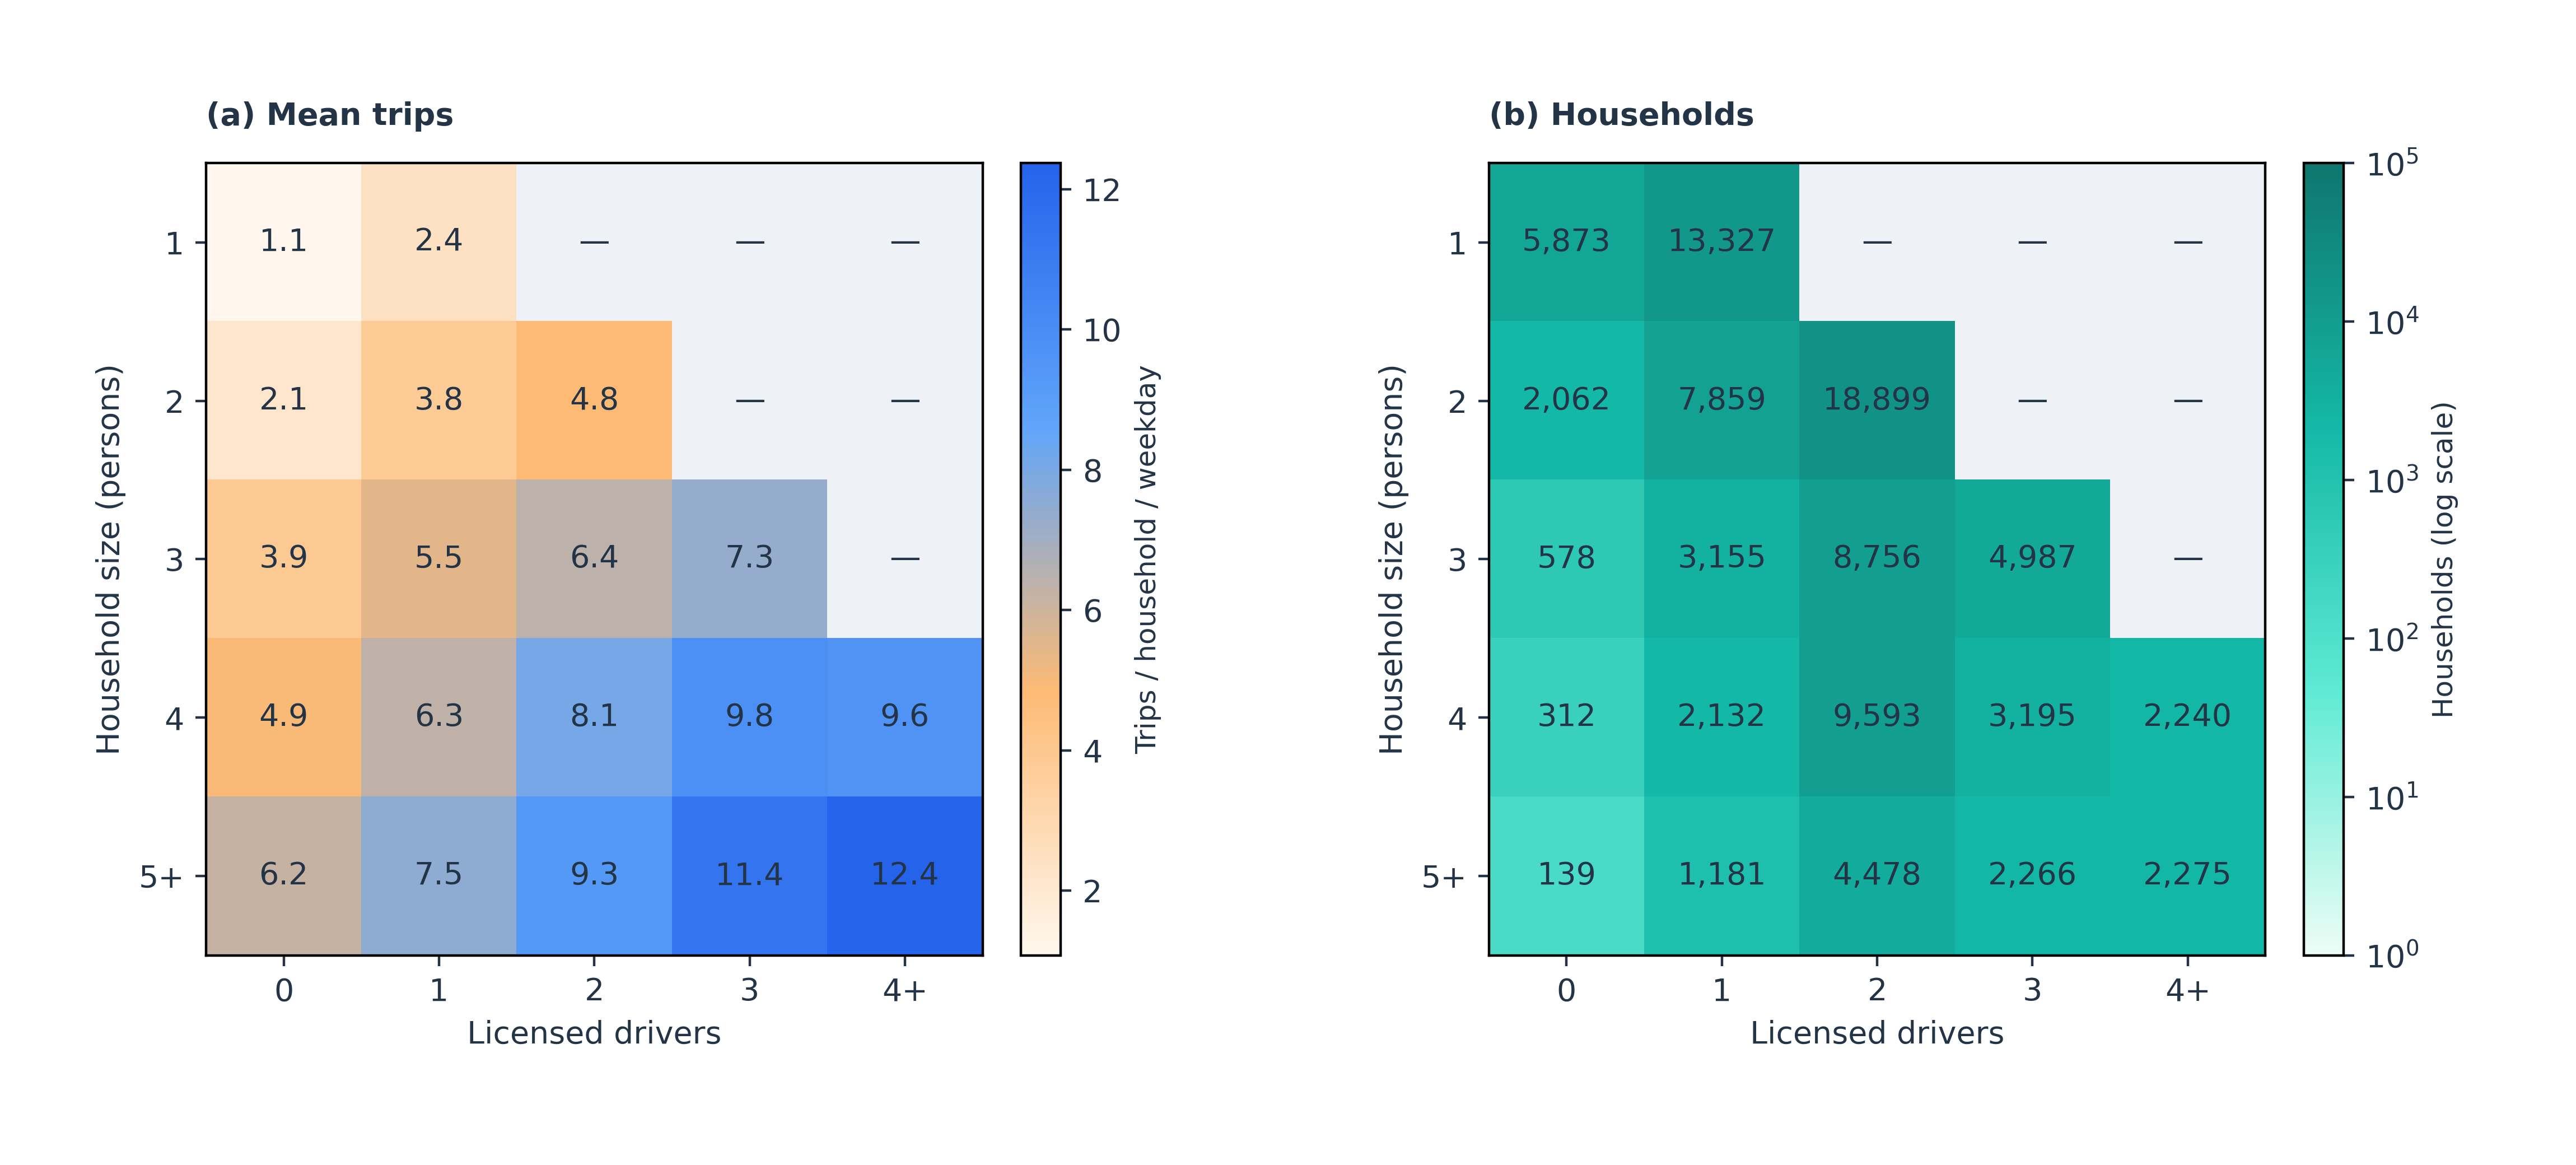

In [29]:
driver_cells = tables['ED18_driver_classification_cells'].loc[
    tables['ED18_driver_classification_cells']['scheme'].eq(
        f'{DRIVER_SIZE_TOP}+ persons by {DRIVER_TOP}+ licensed drivers')]
mean_cmap = MEAN_CMAP.copy(); mean_cmap.set_bad('#EEF2F7')
count_cmap = COUNT_CMAP.copy(); count_cmap.set_bad('#EEF2F7')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
fig.subplots_adjust(left=.08, right=.91, bottom=.18, top=.86, wspace=.50)
possible = driver_cells.pivot(index='size', columns='drivers', values='structurally_possible').to_numpy()
for i, (metric, cmap) in enumerate([('mean_trips', mean_cmap), ('n', count_cmap)]):
    ax = axes[i]
    matrix = driver_cells.pivot(index='size', columns='drivers', values=metric).to_numpy(dtype=float)
    norm = LogNorm(vmin=1, vmax=10 ** np.ceil(np.log10(matrix.max()))) if i else None
    mask = ~possible | (matrix <= 0) if i else ~possible | ~np.isfinite(matrix)
    image = ax.imshow(np.ma.masked_where(mask, matrix), cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(DRIVER_TOP + 1), ticks(range(DRIVER_TOP + 1), DRIVER_TOP))
    ax.set_yticks(range(DRIVER_SIZE_TOP), ticks(range(1, DRIVER_SIZE_TOP + 1), DRIVER_SIZE_TOP))
    ax.set_xlabel('Licensed drivers')
    ax.set_ylabel('Household size (persons)')
    panel(ax, '(a) Mean trips' if i == 0 else '(b) Households')
    for row in range(DRIVER_SIZE_TOP):
        for col in range(DRIVER_TOP + 1):
            value = matrix[row, col]
            label = '—' if not possible[row, col] or not np.isfinite(value) else f'{value:,.0f}' if i else f'{value:.1f}'
            ax.text(col, row, label, ha='center', va='center', color=INK, fontsize=10)
    cbar = fig.colorbar(image, ax=ax, fraction=.047, pad=.045)
    cbar.set_label('Households (log scale)' if i else 'Trips / household / weekday', fontsize=9)
    if i:
        cbar.minorticks_off()
save_figure(fig, 'Figure_ED10')

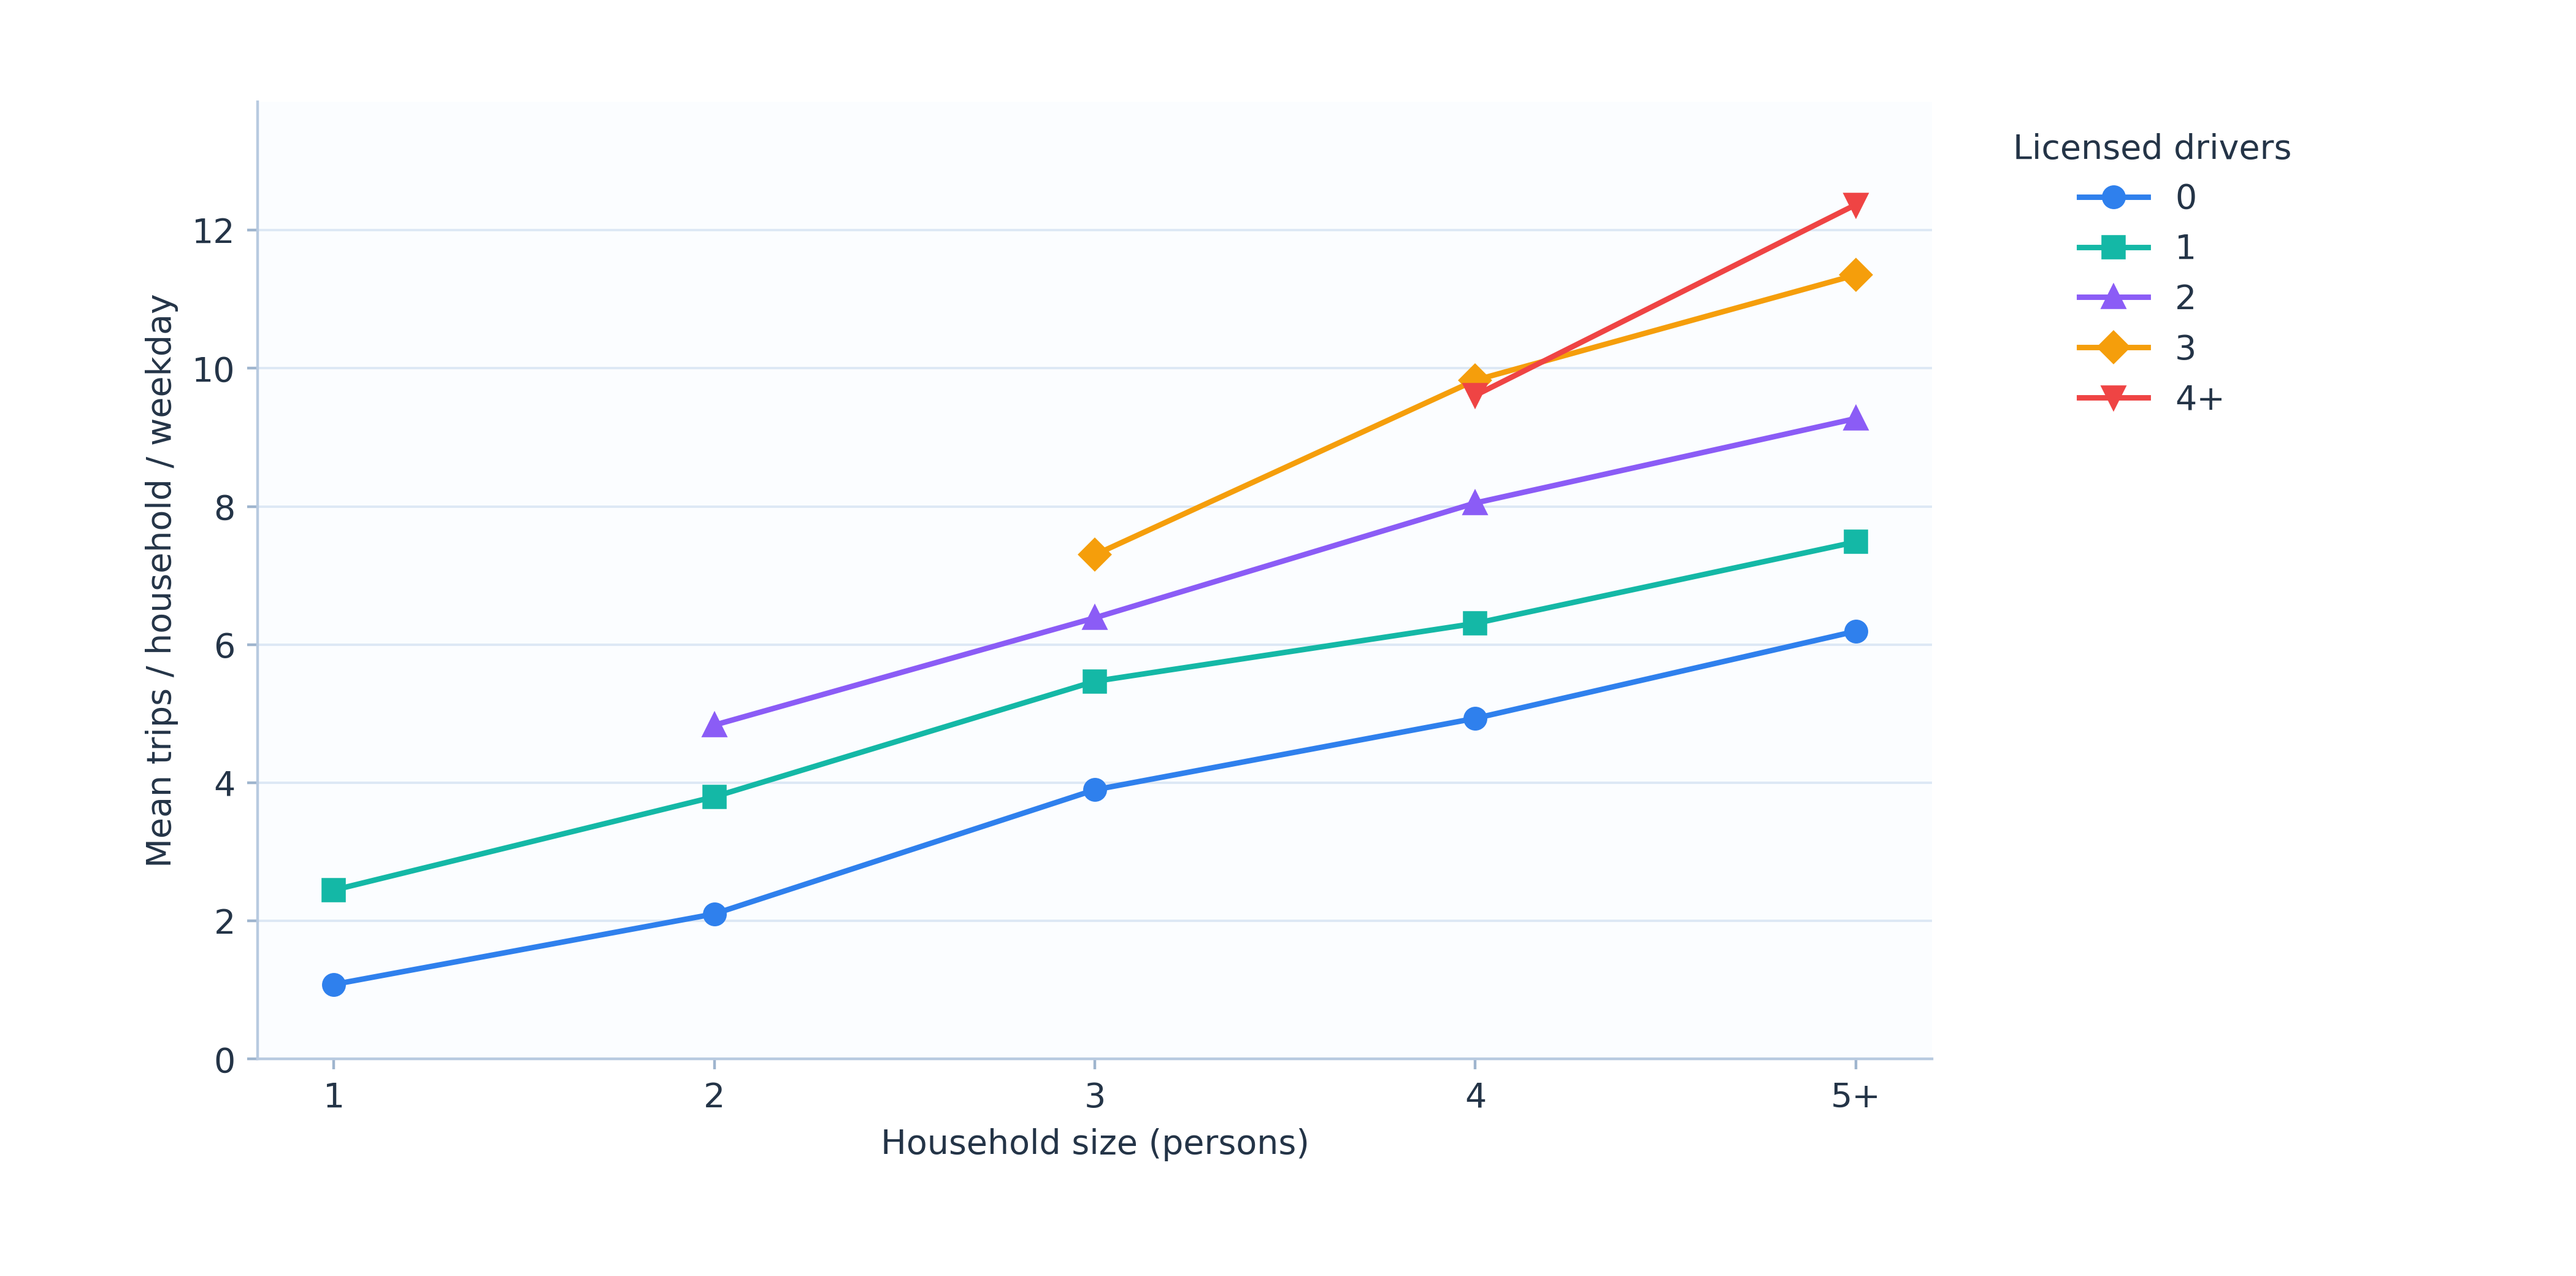

In [30]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.subplots_adjust(left=.10, right=.75, bottom=.17, top=.92)
driver_colours = [BLUE, AQUA, VIOLET, ORANGE, '#EF4444']
driver_markers = ['o', 's', '^', 'D', 'v']
for driver_count in range(DRIVER_TOP + 1):
    block = driver_cells.loc[driver_cells['drivers'].eq(driver_count)].sort_values('size')
    rates = block['mean_trips'].where(block['n'].gt(0))
    label = f'{driver_count}+' if driver_count == DRIVER_TOP else str(driver_count)
    ax.plot(block['size'], rates, marker=driver_markers[driver_count], markersize=6,
            linewidth=1.6, color=driver_colours[driver_count], label=label)
ax.set_xticks(range(1, DRIVER_SIZE_TOP + 1), ticks(range(1, DRIVER_SIZE_TOP + 1), DRIVER_SIZE_TOP))
ax.set_xlabel('Household size (persons)')
ax.set_ylabel('Mean trips / household / weekday')
ax.set_ylim(0, driver_cells['mean_trips'].max() * 1.12)
style_axes(ax)
ax.legend(title='Licensed drivers', frameon=False, bbox_to_anchor=(1.03, 1), loc='upper left')
save_figure(fig, 'Figure_ED11')

### Household size × vehicles

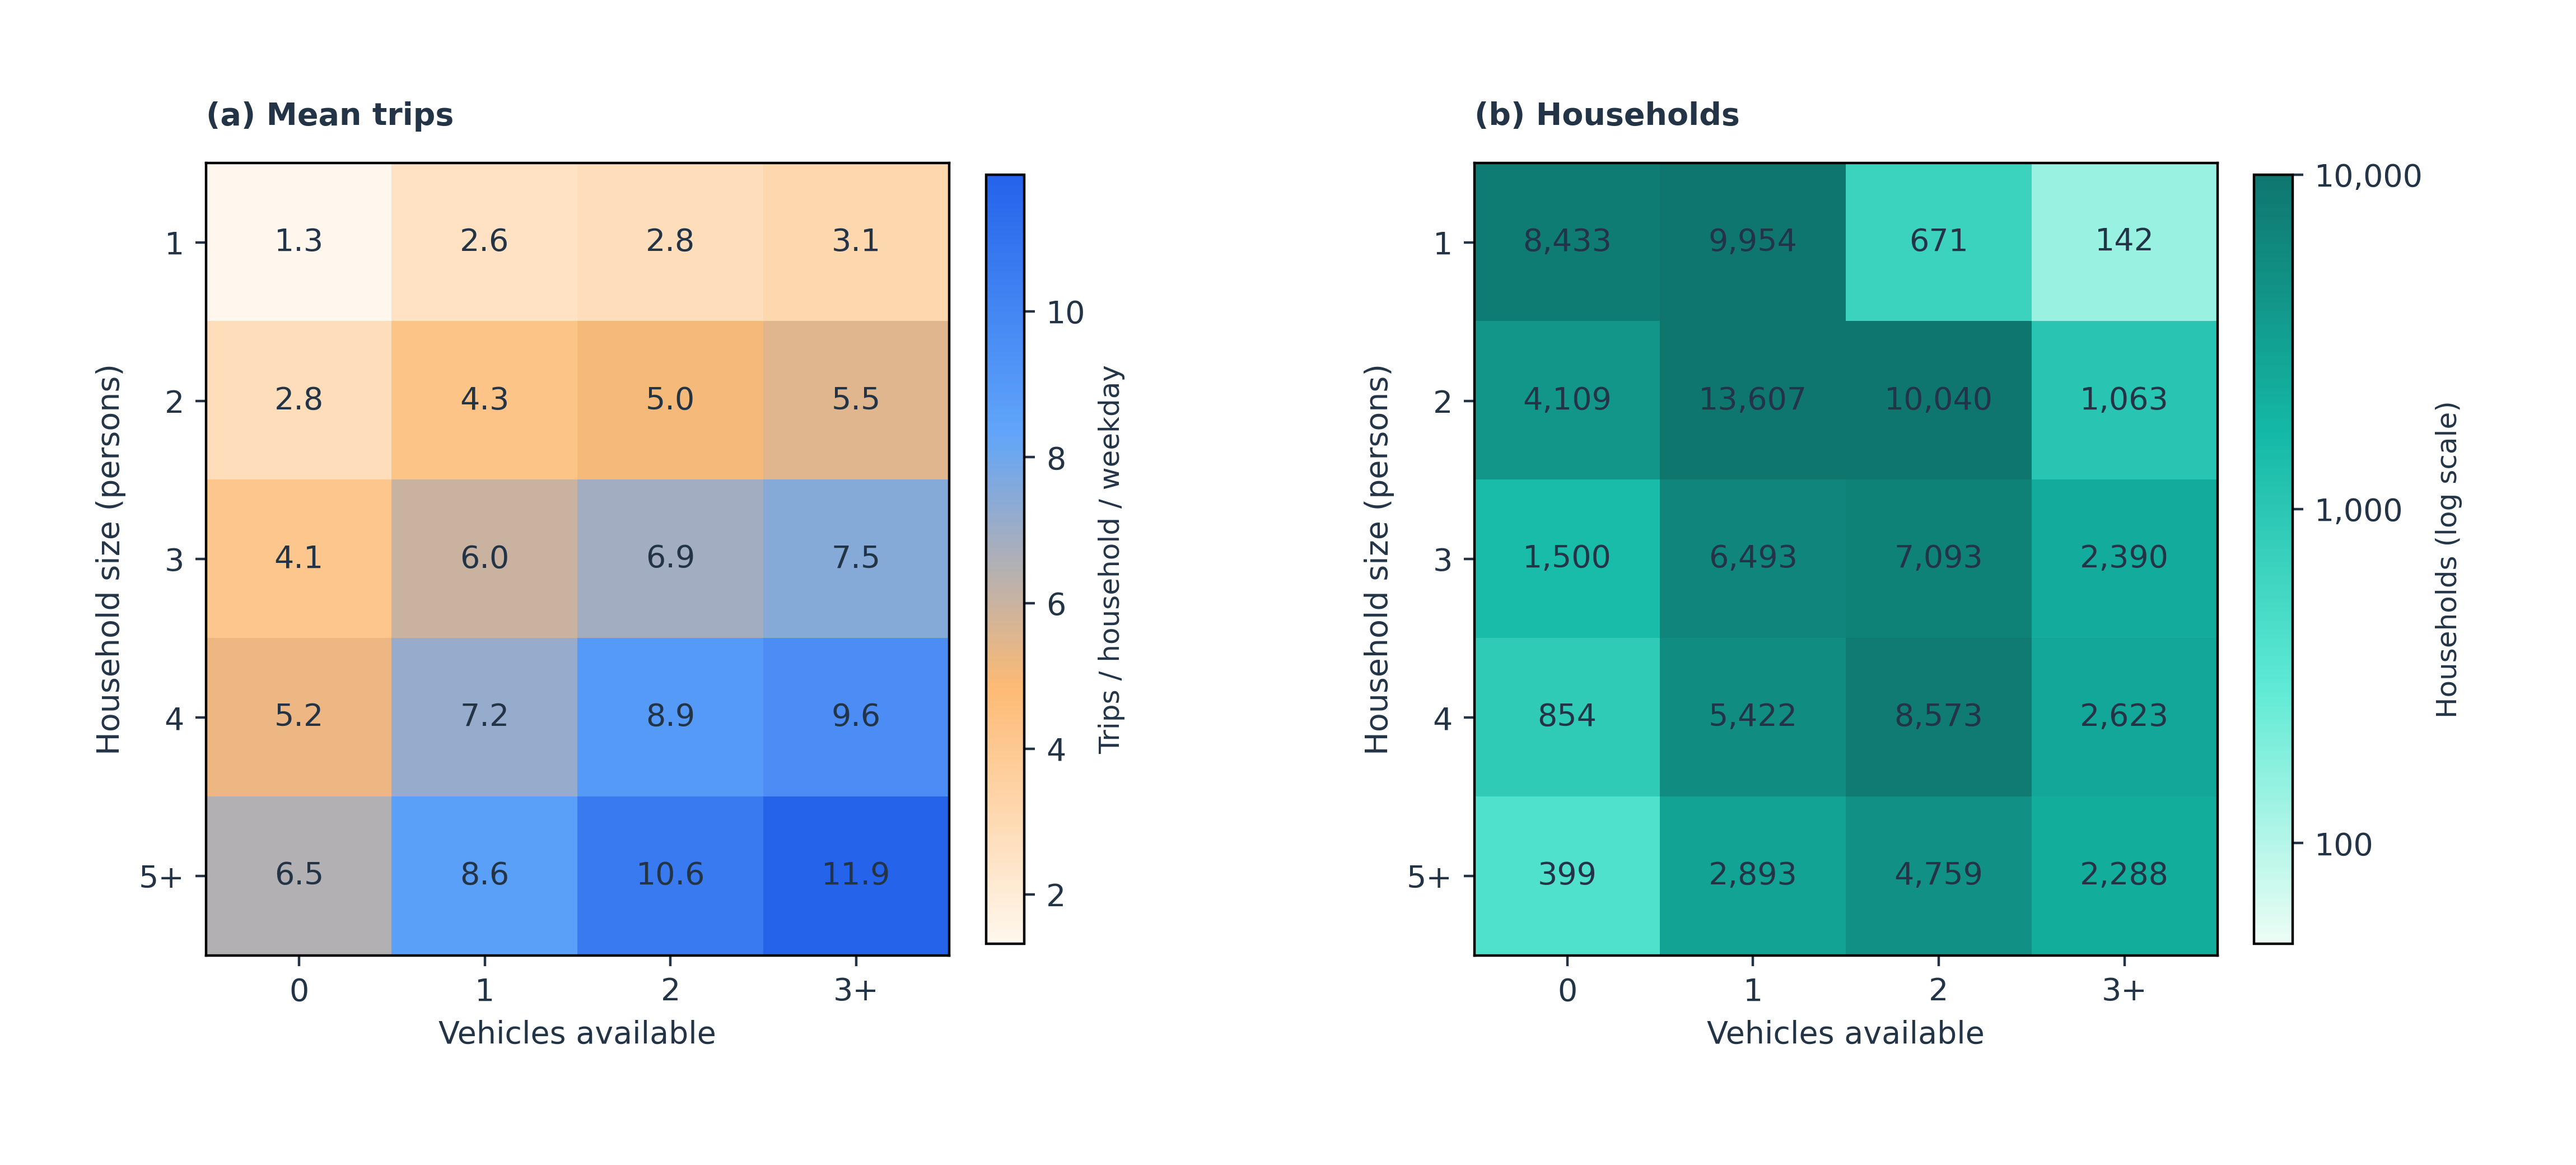

In [31]:
# Vehicle-based comparison.
cells = tables['ED07_classification_cells'].query('scheme == "5+ persons by 3+ vehicles"')
mean_cmap = MEAN_CMAP.copy(); mean_cmap.set_bad('#EEF2F7')
count_cmap = COUNT_CMAP.copy(); count_cmap.set_bad('#EEF2F7')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
fig.subplots_adjust(left=.08, right=.89, bottom=.18, top=.86, wspace=.55)
for i, (metric, cmap) in enumerate([('mean_trips', mean_cmap), ('n', count_cmap)]):
    ax = axes[i]
    matrix = cells.pivot(index='size', columns='vehicles', values=metric).to_numpy(dtype=float)
    norm = LogNorm(vmin=50, vmax=10000) if i else None
    values = np.ma.masked_where(matrix <= 0, matrix) if i else np.ma.masked_invalid(matrix)
    image = ax.imshow(values, cmap=cmap, norm=norm, aspect='auto', origin='upper')
    ax.set_xticks(range(4), ['0', '1', '2', '3+'])
    ax.set_yticks(range(5), ['1', '2', '3', '4', '5+'])
    ax.set_xlabel('Vehicles available')
    ax.set_ylabel('Household size (persons)')
    panel(ax, '(a) Mean trips' if i == 0 else '(b) Households')
    for row in range(5):
        for col in range(4):
            value = matrix[row, col]
            label = ('—' if not np.isfinite(value) else f'{value:,.0f}' if i else f'{value:.1f}')
            ax.text(col, row, label, ha='center', va='center', color=INK, fontsize=10)
    cbar = fig.colorbar(image, ax=ax, fraction=.047, pad=.045)
    cbar.set_label('Households (log scale)' if i else 'Trips / household / weekday', fontsize=9)
    if i:
        cbar.set_ticks([100, 1000, 10000])
        cbar.set_ticklabels(['100', '1,000', '10,000'])
        cbar.minorticks_off()
save_figure(fig, 'Figure_ED04')

In [32]:
blocks = []
for field in COUNTS[:2]:
    for view in ['exact', 'display']:
        available = analysis.dropna(subset=[field])
        levels = available[field].astype(int)
        trips = available['nhhldtrip'].astype(int)
        if view == 'display':
            levels, trips = capped(levels, CAPS[field]), capped(trips, TRIP_CAP)
        grid = pd.MultiIndex.from_product(
            [range(int(levels.min()), int(levels.max()) + 1), range(int(trips.max()) + 1)],
            names=['level', 'trips'])
        counts = pd.DataFrame({'level': levels, 'trips': trips}).groupby(['level', 'trips']).size()
        block = counts.reindex(grid, fill_value=0).rename('n').reset_index()
        block.insert(0, 'variable', field)
        block.insert(1, 'view', view)
        block['level_label'] = ticks(block['level'], CAPS[field]) if view == 'display' else block['level'].astype(str)
        block['trip_label'] = ticks(block['trips'], TRIP_CAP) if view == 'display' else block['trips'].astype(str)
        block['group_n'] = block.groupby('level')['n'].transform('sum')
        block['panel_n'] = len(available)
        block['source_n'] = len(analysis)
        block['missing_predictor_n'] = len(analysis) - len(available)
        blocks.append(block)
tables['ED16_trip_frequencies'] = pd.concat(blocks, ignore_index=True)
tables['ED16_trip_frequencies'].to_csv(TABLES / 'ED16_trip_frequencies.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED16_trip_frequencies'].groupby(['variable', 'view'])['n'].sum())

variable        view   
nperson         display    93307
                exact      93307
nvehicle_clean  display    93306
                exact      93306
Name: n, dtype: int64

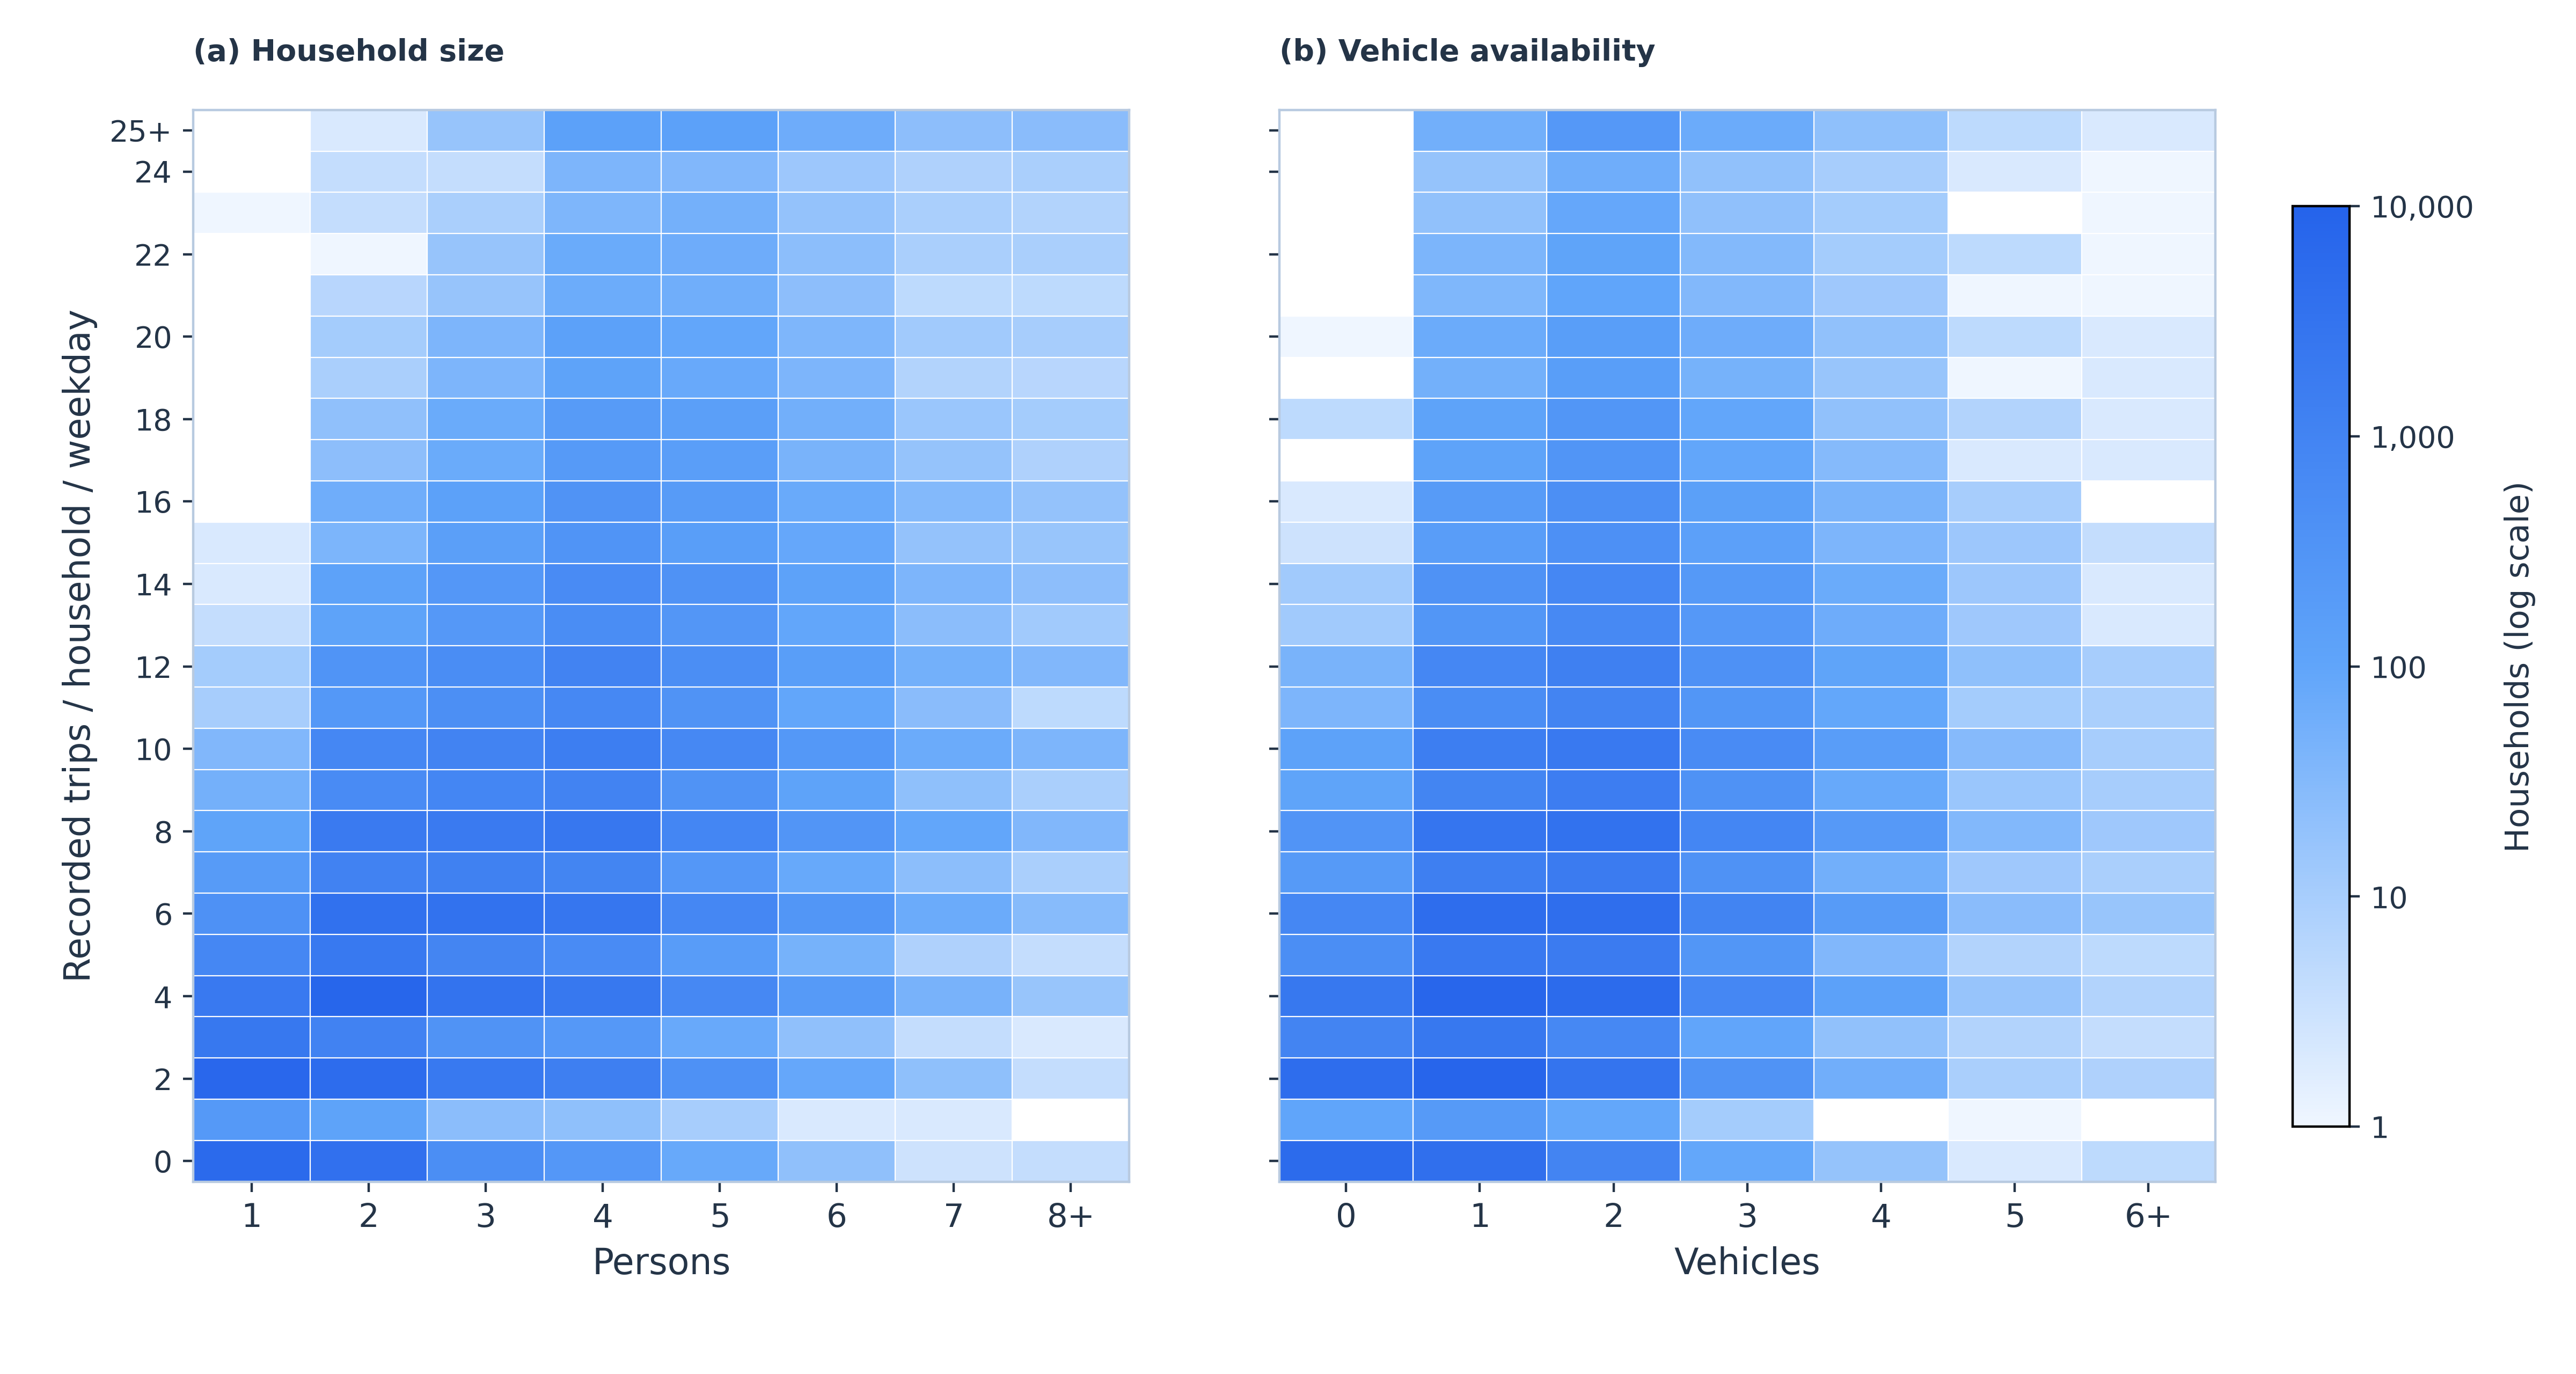

In [33]:
# ED07: discrete joint frequencies, not smoothed densities or fitted values.
frequency = tables['ED16_trip_frequencies'].query('view == "display"')
colour_max = 10 ** int(np.ceil(np.log10(frequency['n'].max())))
norm = LogNorm(vmin=1, vmax=colour_max)
cmap = LinearSegmentedColormap.from_list('household_frequency', ['#EFF6FF', '#60A5FA', '#2563EB'])
cmap.set_bad('white')
fig, axes = plt.subplots(1, 2, figsize=(12, 6.4), sharey=True)
fig.subplots_adjust(left=.075, right=.86, bottom=.14, top=.92, wspace=.16)
for i, field in enumerate(COUNTS[:2]):
    ax = axes[i]
    data = frequency.loc[frequency['variable'].eq(field)]
    grid = data.pivot(index='trips', columns='level', values='n').sort_index().sort_index(axis=1)
    values = grid.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_equal(values, 0), origin='lower', aspect='auto',
                      interpolation='nearest', cmap=cmap, norm=norm)
    ax.set_xticks(range(len(grid.columns)), ticks(grid.columns, CAPS[field]), fontsize=11)
    shown_trips = list(range(0, TRIP_CAP, 2)) + [TRIP_CAP]
    ax.set_yticks(shown_trips, ticks(shown_trips, TRIP_CAP), fontsize=10)
    ax.set_xlabel('Persons' if i == 0 else 'Vehicles', fontsize=12)
    panel(ax, '(a) Household size' if i == 0 else '(b) Vehicle availability')
    ax.set_xticks(np.arange(-.5, len(grid.columns), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(grid.index), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=.4)
    ax.tick_params(which='minor', bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_color('#B8CAE0')
axes[0].set_ylabel('Recorded trips / household / weekday', fontsize=12)
colour_axis = fig.add_axes([.89, .18, .022, .67])
colourbar = fig.colorbar(image, cax=colour_axis)
colour_ticks = [10 ** k for k in range(int(np.log10(colour_max)) + 1)]
colourbar.set_ticks(colour_ticks, labels=[f'{n:,}' for n in colour_ticks])
colourbar.minorticks_off()
colourbar.set_label('Households (log scale)', fontsize=11, labelpad=10)
save_figure(fig, 'Figure_ED07')

## 12. Correlation analysis

In [34]:
def pairwise_correlations(data):
    """Rank after pairwise missing-value removal, so tied Spearman ranks use the same rows."""
    rows = []
    for x in data.columns:
        for y in data.columns:
            pair = pd.concat([data[x], data[y]], axis=1).dropna().astype(float)
            a, b = pair.iloc[:, 0], pair.iloc[:, 1]
            rows.append({'variable_1': x, 'variable_2': y, 'n': len(pair),
                         'pearson': a.corr(b),
                         'spearman': a.rank(method='average').corr(b.rank(method='average'))})
    return pd.DataFrame(rows)

tables['ED09_predictor_correlations'] = pairwise_correlations(analysis[COUNTS])
tables['ED09_predictor_correlations'].to_csv(TABLES / 'ED09_predictor_correlations.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED09_predictor_correlations'])

,variable_1,variable_2,n,pearson,spearman
0,nperson,nperson,93307,1.000000,1.000000
1,nperson,nvehicle_clean,93306,0.425394,0.482220
2,nperson,nlicence,93307,0.598793,0.631591
3,nperson,nempft,93307,0.515168,0.533852
4,nperson,nemppt,93307,0.261946,0.257000
...,...,...,...,...,...
59,workers,nempft,93307,0.873023,0.882311
60,workers,nemppt,93307,0.469958,0.423284
61,workers,nemphome,93307,0.201397,0.203205
62,workers,nstudent,93307,0.327388,0.369030


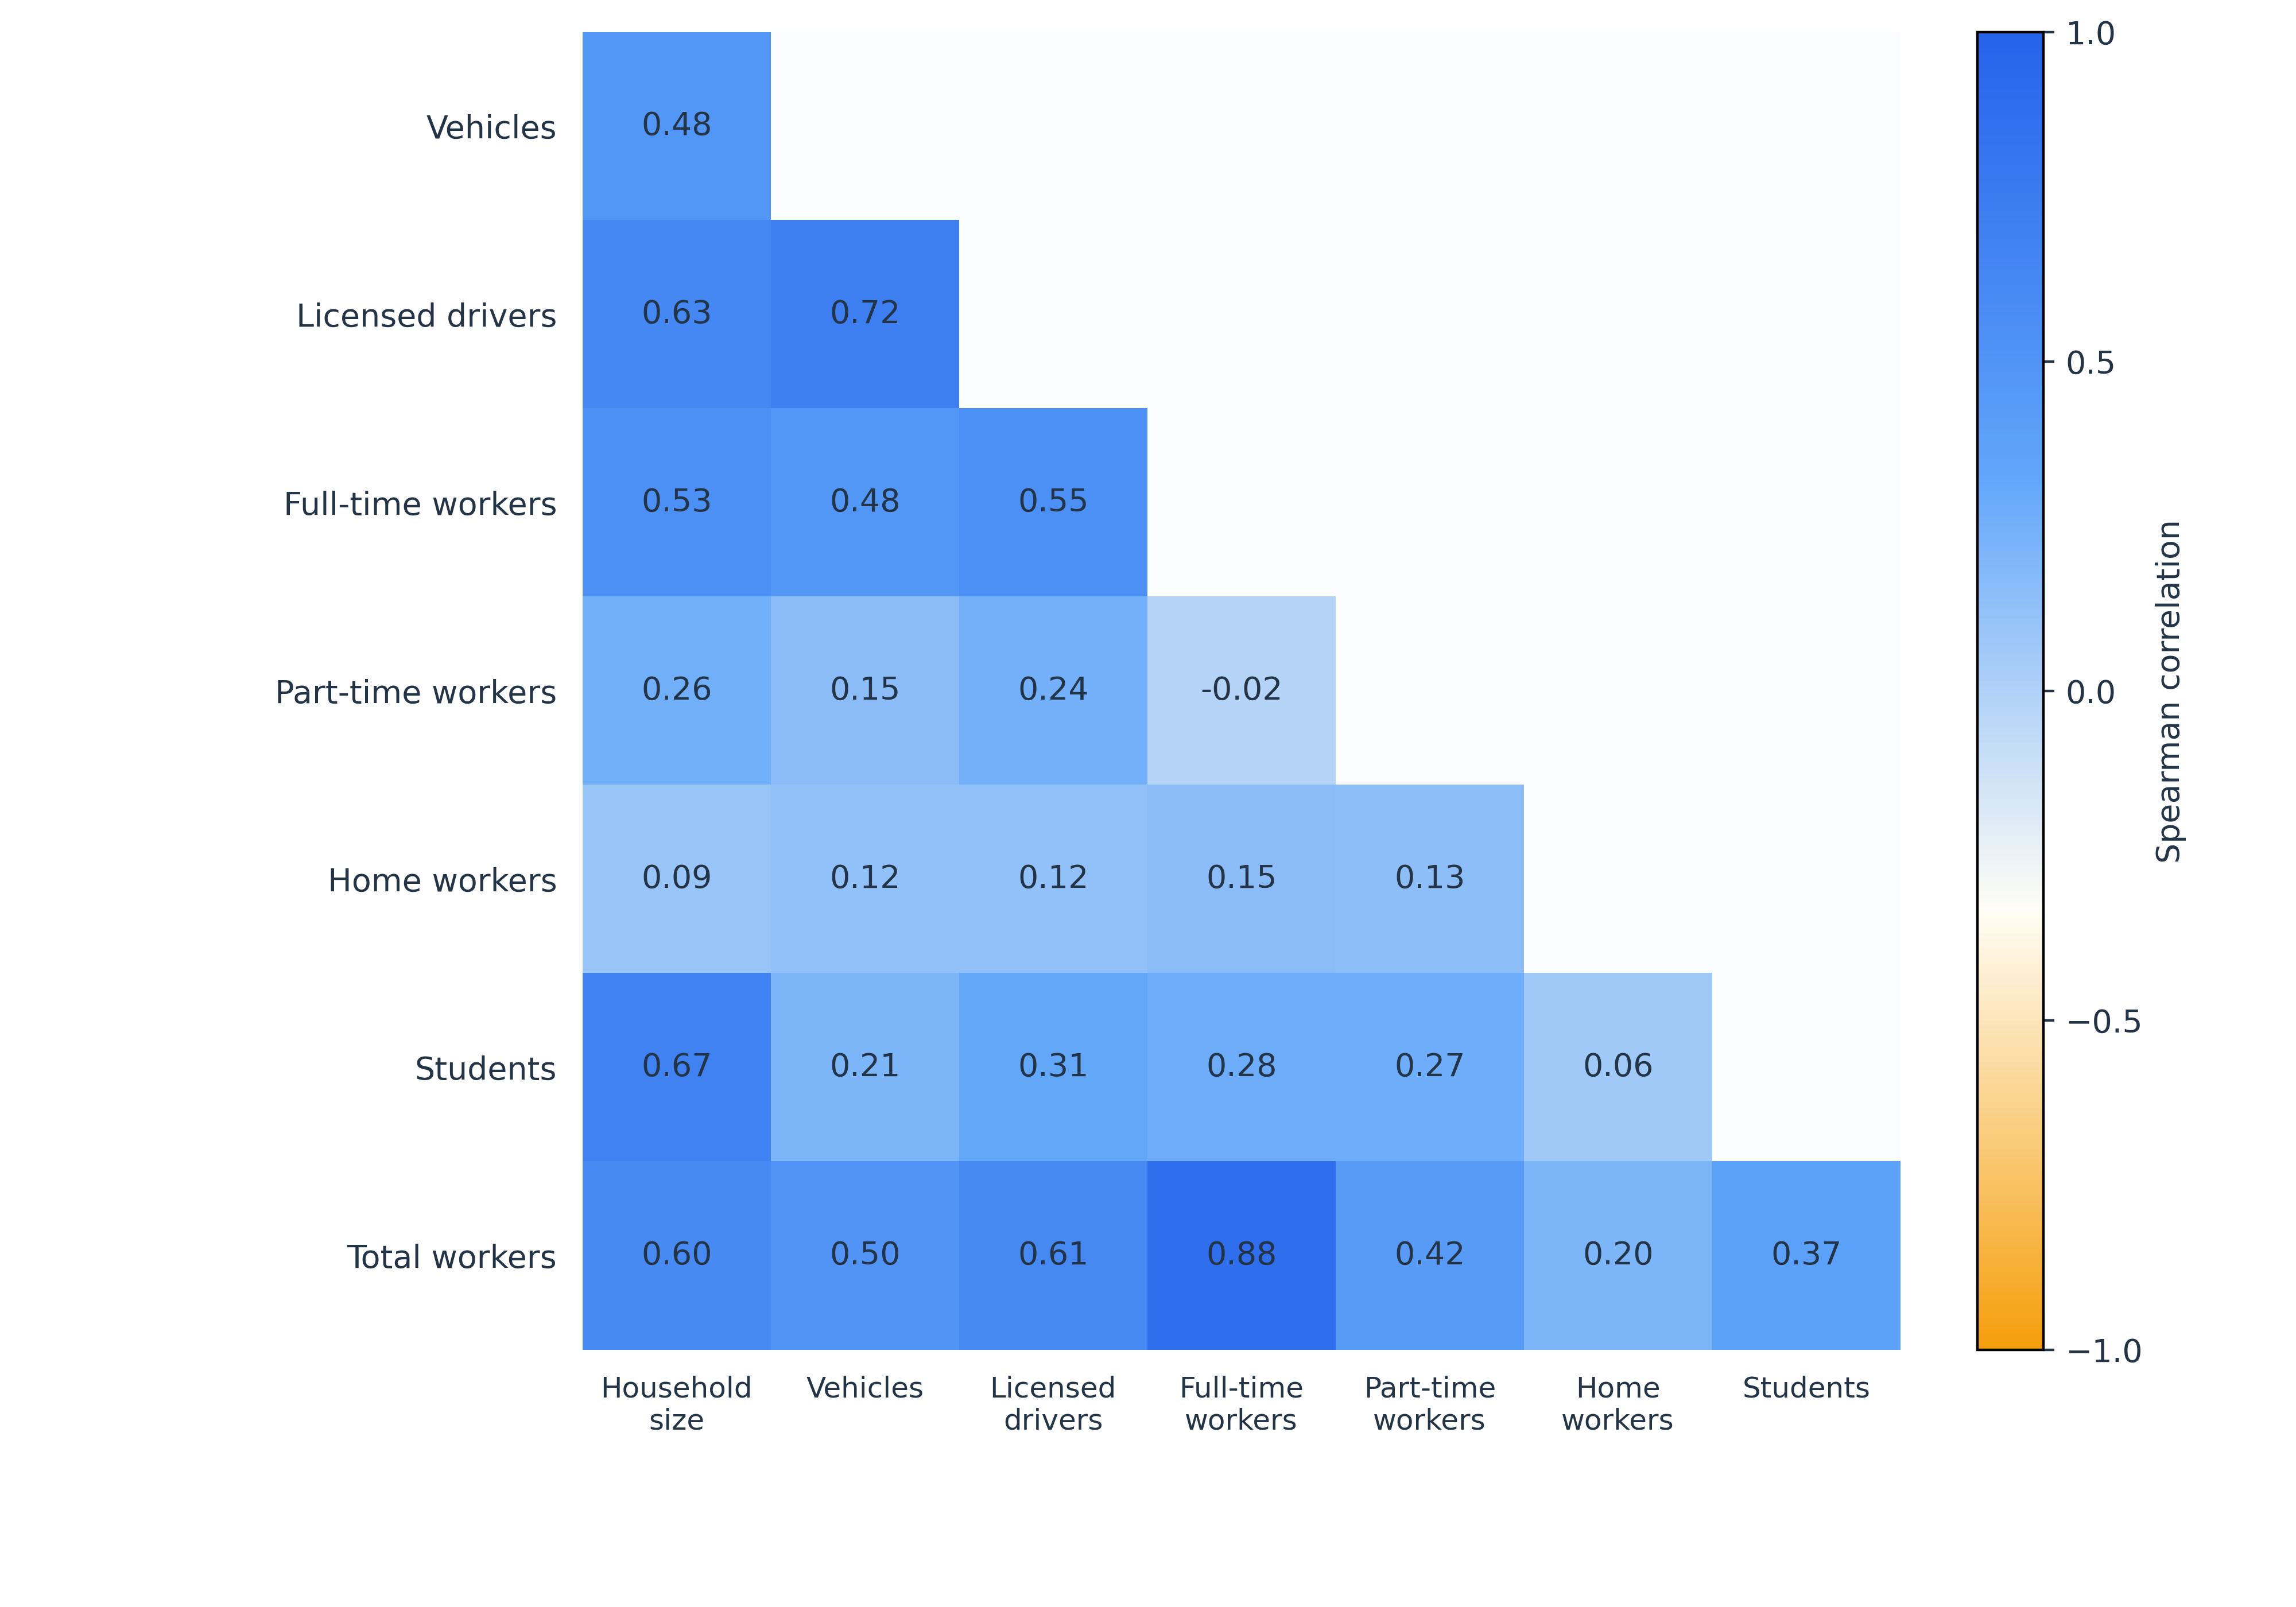

In [35]:
# ED06: rank correlation, lower triangle; Pearson retained in the backing table.
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(left=.22, right=.89, bottom=.16, top=.98)
data = tables['ED09_predictor_correlations'].pivot(index='variable_1', columns='variable_2', values='spearman')
matrix = data.reindex(index=COUNTS, columns=COUNTS).to_numpy()
masked = np.ma.masked_where(np.triu(np.ones_like(matrix), k=0).astype(bool), matrix)
image = ax.imshow(masked[1:, :-1], cmap=CORR_CMAP, vmin=-1, vmax=1)
short = ['Household\nsize', 'Vehicles', 'Licensed\ndrivers', 'Full-time\nworkers',
         'Part-time\nworkers', 'Home\nworkers', 'Students', 'Total\nworkers']
ax.set_xticks(range(len(COUNTS) - 1), short[:-1], fontsize=9)
ax.set_yticks(range(len(COUNTS) - 1), [x.replace('\n', ' ') for x in short[1:]], fontsize=10)
ax.tick_params(length=0, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)
for row in range(len(COUNTS)):
    for col in range(row):
        ax.text(col, row - 1, f'{matrix[row, col]:.2f}', ha='center', va='center', color=INK)
cbar = fig.colorbar(image, ax=ax, fraction=.043, pad=.05, ticks=[-1, -.5, 0, .5, 1])
cbar.set_label('Spearman correlation')
save_figure(fig, 'Figure_ED06')

### Household characteristics and trip outcomes

In [36]:
outcome_pairs = pairwise_correlations(analysis[COUNTS + ['nhhldtrip']])
outcome_correlations = outcome_pairs.loc[
    outcome_pairs['variable_2'].eq('nhhldtrip') & outcome_pairs['variable_1'].isin(COUNTS)
].rename(columns={'variable_1': 'variable'}).drop(columns='variable_2')
outcome_correlations['characteristic'] = outcome_correlations['variable'].map(LABELS)
outcome_correlations = outcome_correlations.set_index('variable').reindex(COUNTS).reset_index()
tables['ED17_outcome_correlations'] = outcome_correlations
outcome_correlations.to_csv(TABLES / 'ED17_outcome_correlations.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(outcome_correlations)

,variable,n,pearson,spearman,characteristic
0,nperson,93307,0.571317,0.613723,Household size
1,nvehicle_clean,93306,0.411209,0.481963,Vehicles available
2,nlicence,93307,0.512864,0.558541,Licensed drivers
3,nempft,93307,0.440895,0.506859,Full-time workers
4,nemppt,93307,0.291454,0.264192,Part-time workers
5,nemphome,93307,0.087738,0.082649,Home workers
6,nstudent,93307,0.516850,0.504856,Students
7,workers,93307,0.531417,0.580852,Total workers


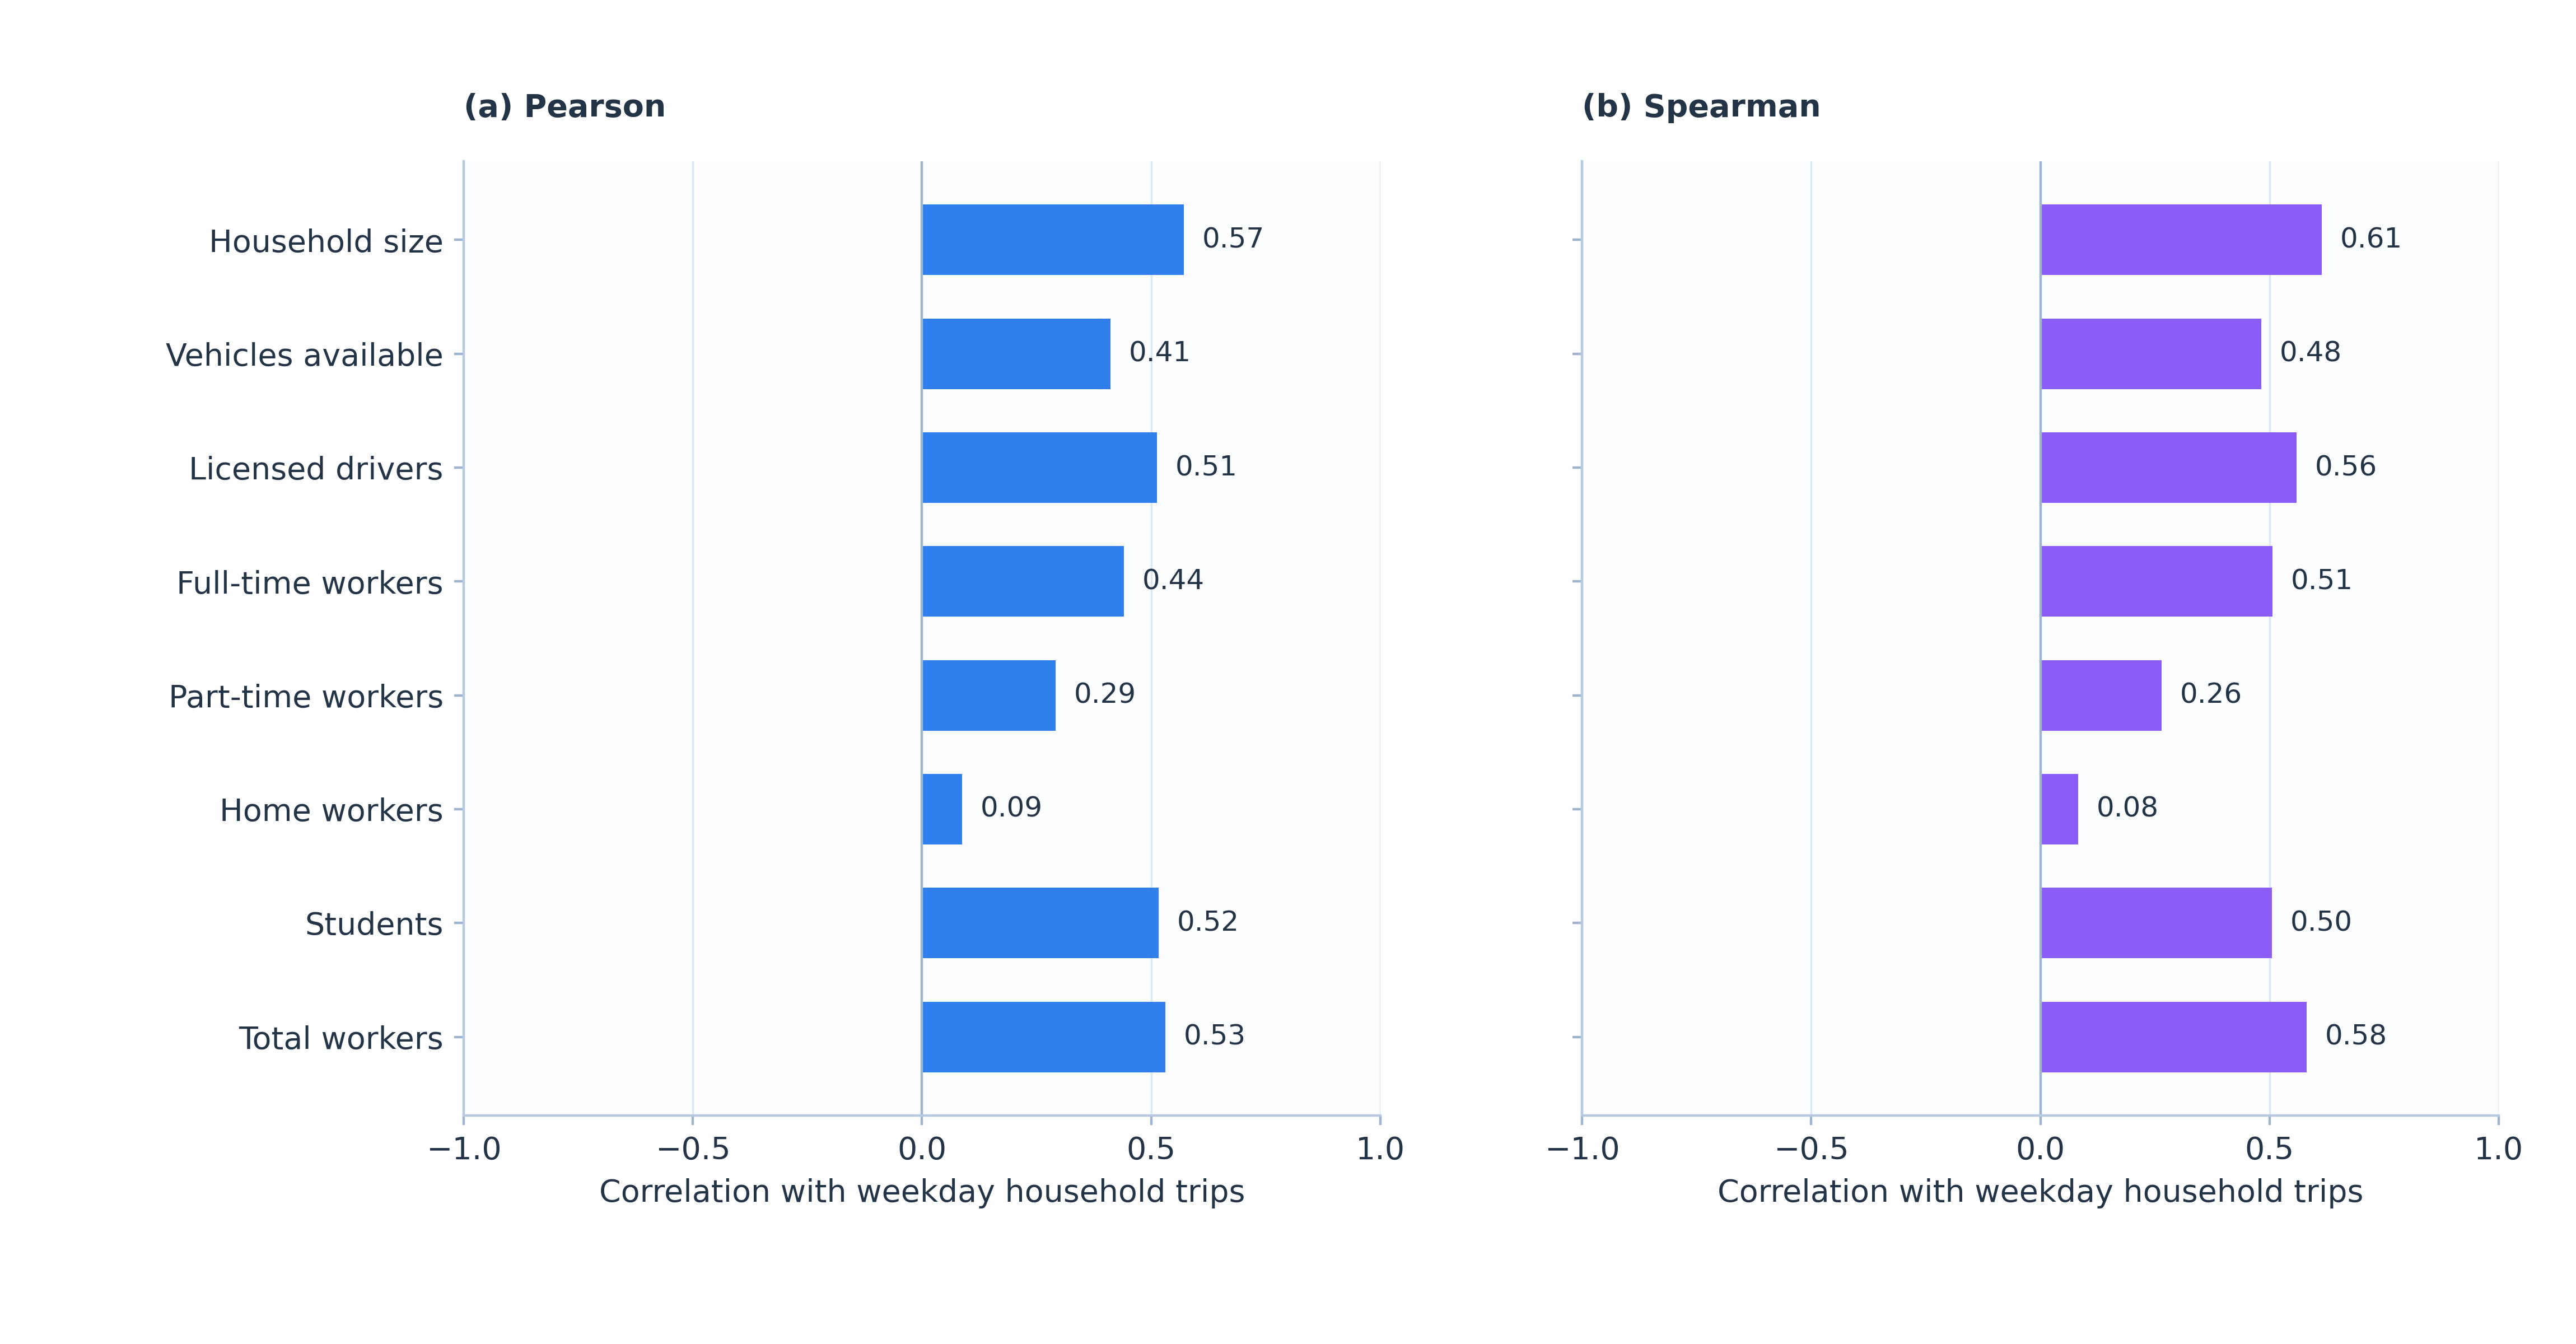

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.0), sharey=True)
fig.subplots_adjust(left=.18, right=.97, bottom=.17, top=.88, wspace=.22)
y = np.arange(len(COUNTS))
for ax, metric, colour, label in zip(
        axes, ['pearson', 'spearman'], [BLUE, VIOLET], ['(a) Pearson', '(b) Spearman']):
    values = outcome_correlations[metric].to_numpy()
    ax.barh(y, values, height=.62, color=colour)
    ax.set_yticks(y, outcome_correlations['characteristic'])
    ax.set_xlim(-1, 1)
    ax.set_xticks([-1, -.5, 0, .5, 1])
    ax.set_xlabel('Correlation with weekday household trips')
    style_axes(ax)
    ax.grid(False, axis='y')
    ax.grid(axis='x', color='#DDE8F5', linewidth=.6)
    ax.axvline(0, color='#9FB5CE', linewidth=.8)
    panel(ax, label)
    for position, value in zip(y, values):
        offset = .04 if value >= 0 else -.04
        ax.text(value + offset, position, f'{value:.2f}', va='center',
                ha='left' if value >= 0 else 'right', color=INK, fontsize=9)
axes[0].invert_yaxis()
save_figure(fig, 'Figure_ED08')

## 13. Regional variation and zone support

In [38]:
regional = []
for region in ORDERS['region']:
    subset = analysis.loc[analysis['region'].eq(region)]
    block = cell_statistics(subset, 5, 3)
    block.insert(0, 'region', region)
    block['share_of_region_pct'] = 100 * block['n'] / len(subset)
    block['weighted_share_of_region_pct'] = 100 * block['weight_sum'] / subset['expf'].sum()
    regional.append(block)
tables['ED11_regional_cells'] = pd.concat(regional, ignore_index=True)
tables['ED11_regional_cells'].to_csv(TABLES / 'ED11_regional_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
zone = zones.copy()
tables['ED12_zone_support'] = zone.reset_index().rename(columns={'gta01hhld': 'zone'})
tables['ED12_zone_support'].to_csv(TABLES / 'ED12_zone_support.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED11_regional_cells'])
show(tables['ED12_zone_support'])

,region,size,vehicles,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,...,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,vehicle_label,support_below_30,share_of_region_pct,weighted_share_of_region_pct
0,Toronto,1,0,7031,1.400085,1.461091,2.0,3119,135921.93,44.360688,...,43.929563,51611,51611,0,5+ persons by 3+ vehicles,1,0,False,13.622801,13.879303
1,Toronto,1,1,6256,2.543159,1.911317,2.0,1215,118660.63,19.421355,...,19.266298,51611,51611,0,5+ persons by 3+ vehicles,1,1,False,12.121212,12.116711
2,Toronto,1,2,318,2.86478,2.079785,2.0,50,5954.87,15.723270,...,15.486316,51611,51611,0,5+ persons by 3+ vehicles,1,2,False,0.616136,0.608066
3,Toronto,1,3,68,3.073529,2.039287,3.0,10,1288.41,14.705882,...,15.369331,51611,51611,0,5+ persons by 3+ vehicles,1,3+,False,0.131752,0.131563
4,Toronto,2,0,3561,2.875597,2.278249,3.0,903,69249.4,25.358045,...,24.8415,51611,51611,0,5+ persons by 3+ vehicles,2,0,False,6.899558,7.071216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,Peel,4,3,766,9.550914,4.405510,9.0,6,14965.71,0.783290,...,0.8603,17945,17945,0,5+ persons by 3+ vehicles,4,3+,False,4.268598,4.168365
76,Peel,5,0,41,5.853659,3.475349,6.0,3,862.15,7.317073,...,6.8074,17945,17945,0,5+ persons by 3+ vehicles,5+,0,False,0.228476,0.240133
77,Peel,5,1,701,8.603424,5.104585,8.0,11,14246.84,1.569187,...,1.661983,17945,17945,0,5+ persons by 3+ vehicles,5+,1,False,3.906381,3.968139
78,Peel,5,2,1429,10.342197,6.129877,9.0,7,28420.6,0.489853,...,0.468252,17945,17945,0,5+ persons by 3+ vehicles,5+,2,False,7.963221,7.915924


,zone,households,known_vehicle_households,known_dwelling_households,both_known_households
0,1,88,88,88,88
1,2,110,110,110,110
2,5,2,2,2,2
3,6,142,142,142,142
4,7,111,111,111,111
...,...,...,...,...,...
1174,1749,69,69,69,69
1175,1750,1,1,1,1
1176,1751,54,54,54,54
1177,1752,35,35,35,35


## 14. Sensitivity analysis

In [39]:
sensitivity = []
for name, frame in [('Full dataset', analysis),
                    ('Full dataset with fewer than 10 known vehicles or unknown vehicles retained', analysis.loc[~analysis['high_vehicle']])]:
    row = group_statistics(frame.assign(group=name), ['group']).iloc[0].to_dict()
    row['weighted_minus_unweighted'] = row['weighted_mean_trips'] - row['mean_trips']
    sensitivity.append(row)
tables['ED10_overall_sensitivity'] = pd.DataFrame(sensitivity)
tables['ED10_overall_sensitivity'].to_csv(TABLES / 'ED10_overall_sensitivity.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

sensitive = analysis.loc[~analysis['high_vehicle']]
all_cells = cell_statistics(analysis, 5, 3)
low_cells = cell_statistics(sensitive, 5, 3)
comparison = all_cells.merge(low_cells, on=['size', 'vehicles'], suffixes=('_all', '_under10'))
comparison['mean_change_under10_minus_all'] = comparison['mean_trips_under10'] - comparison['mean_trips_all']
tables['ED14_cell_vehicle_sensitivity'] = comparison[
    ['size', 'vehicles', 'n_all', 'n_under10', 'mean_trips_all', 'mean_trips_under10',
     'mean_change_under10_minus_all']]
tables['ED14_cell_vehicle_sensitivity'].to_csv(TABLES / 'ED14_cell_vehicle_sensitivity.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')


show(tables['ED10_overall_sensitivity'])
show(tables['ED14_cell_vehicle_sensitivity'])

,group,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,weighted_minus_unweighted
0,Full dataset,93307,5.643253,4.562479,4.0,10480,1808648.44,11.231740,5.640092,11.158846,93307,93307,0,-0.003160
1,Full dataset with fewer than 10 known vehicles...,93275,5.642895,4.562299,4.0,10478,1808009.31,11.233449,5.639802,11.160618,93275,93275,0,-0.003093


,size,vehicles,n_all,n_under10,mean_trips_all,mean_trips_under10,mean_change_under10_minus_all
0,1,0,8433,8433,1.324558,1.324558,0.0
1,1,1,9954,9954,2.556359,2.556359,0.0
2,1,2,671,671,2.80775,2.80775,0.0
3,1,3,142,140,3.140845,3.114286,-0.026559
4,2,0,4109,4109,2.780239,2.780239,0.0
5,2,1,13607,13607,4.257074,4.257074,0.0
6,2,2,10040,10040,5.011554,5.011554,0.0
7,2,3,1063,1057,5.513641,5.513718,0.000077
8,3,0,1500,1500,4.141333,4.141333,0.0
9,3,1,6493,6493,6.006623,6.006623,0.0


## 15. Expected and observed patterns

In [40]:
exact = tables['ED05_exact_group_trip_rates']
rows = []
for field, (expectation, basis) in EXPECTATIONS.items():
    group = exact.loc[exact['variable'].eq(field)].copy()
    is_numeric = field not in ['dwelling', 'weekday']
    positive = negative = flat = 0
    differences = []
    if is_numeric:
        group = group.assign(_level=group['level'].astype(int)).sort_values('_level')
        for (_, a), (_, b) in zip(group.iloc[:-1].iterrows(), group.iloc[1:].iterrows()):
            if b['_level'] == a['_level'] + 1 and min(a['n'], b['n']) >= 30:
                d = b['mean_trips'] - a['mean_trips']
                positive += int(d > 0)
                negative += int(d < 0)
                flat += int(d == 0)
                differences.append(f'{int(a["_level"])} to {int(b["_level"])}: {d:+.2f}')
    observation = '; '.join(
        f'{r["level"]}: {r["mean_trips"]:.2f} trips (n={int(r["n"]):,})'
        for _, r in group.iterrows())
    sparse = group.loc[group['n'].lt(30)]
    sparse_description = '; '.join(f'{r["level"]} (n={int(r["n"])})' for _, r in sparse.iterrows())
    if not is_numeric:
        assessment = 'Descriptive differences; no signed expectation'
    elif field == 'nemphome':
        assessment = 'Unadjusted pattern is mixed; the conditional expectation is not assessed by EDA'
    else:
        assessment = (f'{positive} positive, {negative} negative and {flat} unchanged adjacent '
                      'contrasts with at least 30 households at both exact levels; '
                      'descriptive consistency, not hypothesis confirmation')
    rows.append({
        'characteristic': group.iloc[0]['characteristic'], 'expectation': expectation,
        'basis': basis, 'observation': observation, 'assessment': assessment,
        'interpretation': 'Unadjusted; no hypothesis confirmation or causal effect',
        'positive_supported_steps': positive, 'negative_supported_steps': negative,
        'unchanged_supported_steps': flat,
        'supported_adjacent_differences': '; '.join(differences) or 'Not applicable',
        'exact_levels_individually_below_30': sparse_description or 'None',
        'households_in_those_exact_levels': int(sparse['n'].sum()),
        'support_rule': '30 per exact level is a project review convention, not guaranteed precision',
    })
tables['ED15_expected_versus_observed'] = pd.DataFrame(rows)
tables['ED15_expected_versus_observed'].to_csv(TABLES / 'ED15_expected_versus_observed.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED15_expected_versus_observed'][['characteristic', 'expectation', 'assessment']])

,characteristic,expectation,assessment
0,Household size,Generally positive; increments need not be con...,"9 positive, 0 negative and 0 unchanged adjacen..."
1,Vehicles available,Generally positive; increments need not be con...,"6 positive, 0 negative and 0 unchanged adjacen..."
2,Licensed drivers,Generally positive through mobility access,"6 positive, 0 negative and 0 unchanged adjacen..."
3,Full-time workers,"Generally positive for total trips, with possi...","5 positive, 0 negative and 0 unchanged adjacen..."
4,Part-time workers,"Generally positive for total trips, with possi...","4 positive, 0 negative and 0 unchanged adjacen..."
5,Home workers,No direction conditional on full-time and part...,Unadjusted pattern is mixed; the conditional e...
6,Students,Generally positive through education and escor...,"6 positive, 0 negative and 0 unchanged adjacen..."
7,Dwelling type,No predetermined ranking,Descriptive differences; no signed expectation
8,Survey weekday,No predetermined ranking,Descriptive differences; no signed expectation


## 16. Check analysis totals

In [41]:
assert len(analysis) == len(raw) == len(master), 'Full-dataset EDA lost households.'
assert tables['ED04_trip_distribution']['n'].sum() == len(analysis), 'Trip-frequency total differs from the full dataset.'
for (field, view), block in tables['ED16_trip_frequencies'].groupby(['variable', 'view']):
    assert block['n'].sum() == analysis[field].notna().sum(), f'Joint-frequency total differs: {field}, {view}'
assert tables['ED07_classification_cells'].groupby('scheme')['n'].sum().eq(analysis['nvehicle_clean'].notna().sum()).all(), 'Vehicle-classification totals differ.'
assert tables['ED18_driver_classification_cells'].groupby('scheme')['n'].sum().eq(len(analysis)).all(), 'Driver-classification totals differ.'
assert tables['ED12_zone_support']['households'].sum() == len(analysis), 'Zone total differs.'
show(sample_summary)
print('Full-dataset sample and denominator checks passed.')

,Cohort,Households,Zones represented,Use
0,Full dataset (main EDA),93307,1179,Main EDA; no exclusions
1,Known vehicle count (diagnostic only),93306,1179,Provisional diagnostic; not a final model sample
2,Known vehicle and dwelling (diagnostic only),93297,1179,Provisional diagnostic; not a final model sample
3,"Known vehicle/dwelling, fewer than 10 vehicles...",93265,1179,Provisional diagnostic; not a final model sample


Full-dataset sample and denominator checks passed.


## 17. Preparation checks before multiple linear regression

Audit available values, category support, unusual records, variable roles, and candidate predictor matrices using the full dataset. No trip-outcome model is fitted and no rows are removed. Candidate designs diagnose encoding and collinearity only; their complete-case counts are not final exclusion decisions. The report and check tables are regenerated by this section.


In [42]:
# This code is embedded in the EDA notebook by append_pre_model_checks.py.
# It inspects candidate designs without fitting a trip-outcome regression.

def save_review_table(name, frame):
    tables[name] = frame
    frame.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig',
                 lineterminator='\n', float_format='%.10g')
    return frame


numeric_audit = []
for field in COUNTS + ['nhhldtrip', 'expf']:
    x = analysis[field].dropna().astype(float)
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    numeric_audit.append({
        'variable': field, 'source_n': len(analysis), 'available_n': len(x),
        'missing_n': len(analysis) - len(x), 'unique_values': x.nunique(),
        'mean': x.mean(), 'sd': x.std(), 'min': x.min(), 'p25': q1,
        'median': x.median(), 'p75': q3, 'p95': x.quantile(.95),
        'p99': x.quantile(.99), 'max': x.max(), 'zero_n': int(x.eq(0).sum()),
        'zero_pct_available': 100 * x.eq(0).mean(), 'skewness': x.skew(),
        'outside_1_5_IQR_n': int((x.lt(q1 - 1.5 * iqr) | x.gt(q3 + 1.5 * iqr)).sum()),
        'IQR_interpretation': 'Descriptive only; not an exclusion rule; can flag common nonzero counts when IQR is zero',
    })
numeric_audit = save_review_table('MLR01_numeric_readiness', pd.DataFrame(numeric_audit))
show(numeric_audit)

,variable,source_n,available_n,missing_n,unique_values,mean,sd,min,p25,median,p75,p95,p99,max,zero_n,zero_pct_available,skewness,outside_1_5_IQR_n,IQR_interpretation
0,nperson,93307,93307,0,14,2.741177,1.418985,1.00,2.00,2.00,4.00,5.0,7.00,16.00,0,0.000000,0.803153,349,Descriptive only; not an exclusion rule; can f...
1,nvehicle_clean,93307,93306,1,20,1.382301,0.974636,0.00,1.00,1.00,2.00,3.0,4.00,36.00,15295,16.392301,2.423434,1914,Descriptive only; not an exclusion rule; can f...
2,nlicence,93307,93307,0,10,1.730095,0.982728,0.00,1.00,2.00,2.00,3.0,4.00,9.00,8964,9.606996,0.477215,4515,Descriptive only; not an exclusion rule; can f...
3,nempft,93307,93307,0,8,1.113025,0.926627,0.00,0.00,1.00,2.00,3.0,4.00,7.00,27902,29.903437,0.503906,17,Descriptive only; not an exclusion rule; can f...
4,nemppt,93307,93307,0,6,0.238235,0.511955,0.00,0.00,0.00,0.00,1.0,2.00,5.00,74410,79.747500,2.308762,18897,Descriptive only; not an exclusion rule; can f...
5,nemphome,93307,93307,0,6,0.108041,0.354863,0.00,0.00,0.00,0.00,1.0,2.00,7.00,84512,90.574126,3.634713,8795,Descriptive only; not an exclusion rule; can f...
6,nstudent,93307,93307,0,10,0.635151,0.953827,0.00,0.00,0.00,1.00,3.0,4.00,9.00,57826,61.973914,1.529894,4861,Descriptive only; not an exclusion rule; can f...
7,workers,93307,93307,0,11,1.351260,1.049564,0.00,1.00,1.00,2.00,3.0,4.00,10.00,22980,24.628377,0.520567,2823,Descriptive only; not an exclusion rule; can f...
8,nhhldtrip,93307,93307,0,48,5.643253,4.562479,0.00,2.00,4.00,8.00,14.0,21.00,55.00,10480,11.231740,1.506328,2129,Descriptive only; not an exclusion rule; can f...
9,expf,93307,93307,0,418,19.383845,2.508741,10.83,17.67,19.35,20.98,23.5,26.13,28.06,0,0.000000,0.078291,2079,Descriptive only; not an exclusion rule; can f...


In [43]:
category_audit = []
for field in ['dwelling', 'weekday', 'region', 'rec-mail']:
    for level, block in analysis.groupby(field, dropna=False, sort=False):
        category_audit.append({
            'variable': field, 'level': str(level), 'n': len(block),
            'percent_full_dataset': 100 * len(block) / len(analysis),
            'mean_trips_unadjusted': block['nhhldtrip'].mean(),
            'zero_trip_pct': 100 * block['zero_trip'].mean(),
            'review_below_30': len(block) < SUPPORT_REVIEW_N,
        })
category_audit = save_review_table('MLR02_category_readiness', pd.DataFrame(category_audit))
show(category_audit)

,variable,level,n,percent_full_dataset,mean_trips_unadjusted,zero_trip_pct,review_below_30
0,dwelling,House,58360,62.546218,6.564873,7.943797,False
1,dwelling,Apartment,27977,29.983817,3.621654,19.465990,False
2,dwelling,Townhouse,6961,7.460319,6.043097,5.660106,False
3,dwelling,Unknown,9,0.009646,4.444444,44.444444,True
4,weekday,Thursday,19414,20.806585,5.623210,10.585145,False
5,weekday,Wednesday,17728,18.999646,5.681634,11.112365,False
6,weekday,Friday,21240,22.763565,5.863183,10.597928,False
7,weekday,Tuesday,18273,19.583740,5.561484,11.733158,False
8,weekday,Monday,16652,17.846464,5.434963,12.370886,False
9,region,Toronto,51612,55.314178,4.918527,14.186623,False


In [44]:
# These markers request inspection; every marked household remains in the EDA.
review_masks = {
    'unknown_vehicle_99': analysis['unknown_vehicle'],
    'unknown_dwelling_9': analysis['unknown_dwelling'],
    'known_vehicles_at_least_10': analysis['high_vehicle'],
    'household_size_at_least_10': analysis['nperson'].ge(10),
    'recorded_trips_at_least_30': analysis['nhhldtrip'].ge(30),
}
review_flags = pd.DataFrame(review_masks).fillna(False)
review_rows = analysis.loc[review_flags.any(axis=1), FIELDS + ['nvehicle_clean', 'workers']].copy()
review_rows['review_reasons'] = review_flags.loc[review_rows.index].apply(
    lambda row: '; '.join(row.index[row]), axis=1)
review_rows['action'] = 'Retained; inspect before any model exclusion decision'
save_review_table('MLR03_rows_for_review', review_rows)
review_summary = save_review_table('MLR04_review_flag_counts', pd.DataFrame([
    {'flag': name, 'households': int(mask.sum()), 'decision': 'Review only; no deletion'}
    for name, mask in review_masks.items()
]))
show(review_summary)

,flag,households,decision
0,unknown_vehicle_99,1,Review only; no deletion
1,unknown_dwelling_9,9,Review only; no deletion
2,known_vehicles_at_least_10,32,Review only; no deletion
3,household_size_at_least_10,58,Review only; no deletion
4,recorded_trips_at_least_30,112,Review only; no deletion


In [45]:
role_rows = [
    ('hnum', 'Exclude from predictors', 'Household ID for traceability', 'No encoding'),
    ('gta01hhld', 'Aggregation / clustering', 'Zone identifier; numerical spacing has no quantitative meaning; consider zone-clustered uncertainty later', 'Do not enter as a numeric slope or blindly create 1,178 dummies'),
    ('nperson', 'Core candidate', 'Retain exact counts initially; inspect diminishing increments; includes children under 11', 'Numeric count; do not automatically one-hot encode'),
    ('nvehicle_clean', 'Core candidate / alternative access measure', 'One unknown; extreme known counts require source review; compare with licensed drivers', 'Numeric count; consider justified nonlinear specification later'),
    ('nlicence', 'Core candidate / alternative access measure', 'Shares household-size and mobility-access information; use design VIF rather than marginal correlations alone', 'Numeric count'),
    ('nempft', 'Composition candidate', 'Use with nemppt OR replace both by workers; not all three', 'Numeric count'),
    ('nemppt', 'Composition candidate', 'Separate coefficient can represent a different association from full-time employment', 'Numeric count'),
    ('workers', 'Alternative to nempft + nemppt', 'Exact arithmetic sum; including all three creates perfect collinearity', 'Numeric count'),
    ('nemphome', 'Optional composition refinement', 'Already included in employment totals; adding as a separate regressor is a conditional contrast, not adding people; do not add again to workers', 'Numeric count; assess adjusted contribution later'),
    ('nstudent', 'Composition candidate', 'Can overlap employment; includes ages 6-10 while trips are recorded for ages 11+; interpret association carefully', 'Numeric count'),
    ('dwelltype_clean / dwelling', 'Candidate categorical control', 'House, Apartment, Townhouse; nine unknowns need a missing-data decision; never treat code 9 as a dwelling magnitude', 'Known categories: 2 indicators plus intercept, House reference; Unknown fourth level only as explicit sensitivity'),
    ('tripday / weekday', 'Candidate categorical control', 'Monday-Friday are categories; coding 1-5 numerically would impose an equal linear daily increment', '4 indicators plus intercept, Monday reference'),
    ('region', 'Optional geographic control', 'Derived from documented zone ranges; broad geographic differences can confound household associations', '3 indicators plus intercept, Toronto reference'),
    ('rec-mail', 'Exclude from substantive predictor set', 'Advance-letter receipt describes survey administration; code 9 is unknown; optional nonresponse/survey sensitivity only', 'If explicitly studied later: Y/N indicator and separate unknown handling'),
    ('n-call', 'Exclude from substantive predictor set', 'Interview completion / edits describe survey process rather than a household travel-generating characteristic', 'No main-model encoding'),
    ('expf', 'Weight / expansion', 'Not a trip-generating predictor; state an explicit weighting convention and use it consistently for observed and predicted totals', 'Not an explanatory variable'),
    ('nhhldtrip', 'Outcome', 'Recorded weekday person trips; retain zeros; count-valued/skewed outcome does not by itself forbid assigned linear regression', 'Numeric outcome; do not one-hot encode'),
    ('split / flags / display categories', 'Exclude from substantive predictor set', 'Historical partition labels, diagnostic flags, and display caps are not substantive regressors; do not include both raw and derived copies', 'No automatic encoding'),
]
variable_roles = save_review_table('MLR05_variable_roles', pd.DataFrame(
    role_rows, columns=['variable', 'provisional_role', 'reason', 'encoding']))
show(variable_roles)

,variable,provisional_role,reason,encoding
0,hnum,Exclude from predictors,Household ID for traceability,No encoding
1,gta01hhld,Aggregation / clustering,Zone identifier; numerical spacing has no quan...,Do not enter as a numeric slope or blindly cre...
2,nperson,Core candidate,Retain exact counts initially; inspect diminis...,Numeric count; do not automatically one-hot en...
3,nvehicle_clean,Core candidate / alternative access measure,One unknown; extreme known counts require sour...,Numeric count; consider justified nonlinear sp...
4,nlicence,Core candidate / alternative access measure,Shares household-size and mobility-access info...,Numeric count
5,nempft,Composition candidate,Use with nemppt OR replace both by workers; no...,Numeric count
6,nemppt,Composition candidate,Separate coefficient can represent a different...,Numeric count
7,workers,Alternative to nempft + nemppt,Exact arithmetic sum; including all three crea...,Numeric count
8,nemphome,Optional composition refinement,Already included in employment totals; adding ...,Numeric count; assess adjusted contribution later
9,nstudent,Composition candidate,Can overlap employment; includes ages 6-10 whi...,Numeric count


In [46]:
# Design diagnostics regress predictors on other predictors; y is not used.
REF_LEVELS = {
    'dwelling': ['House', 'Apartment', 'Townhouse'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
    'region': ['Toronto', 'Durham', 'York', 'Peel'],
}
scenarios = {
    'Size and licensed drivers': (['nperson', 'nlicence'], []),
    'Size and vehicles': (['nperson', 'nvehicle_clean'], []),
    'Size, drivers and vehicles': (['nperson', 'nlicence', 'nvehicle_clean'], []),
    'Separate employment counts + controls': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'nstudent', 'nemphome'],
        ['dwelling', 'weekday', 'region']),
    'Total workers alternative + controls': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'workers', 'nstudent', 'nemphome'],
        ['dwelling', 'weekday', 'region']),
    'Invalid: workers and both employment components': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'workers', 'nstudent'], []),
}
design_rows, vif_rows, eligibility_rows = [], [], []
for name, (numeric_fields, categorical_fields) in scenarios.items():
    needed = numeric_fields + categorical_fields
    valid = analysis[needed].notna().all(axis=1)
    # Unknown is an EDA label, not a valid known dwelling type in these diagnostic designs.
    if 'dwelling' in categorical_fields:
        valid &= analysis['dwelling'].isin(REF_LEVELS['dwelling'])
    frame = analysis.loc[valid]
    design = frame[numeric_fields].astype(float).copy()
    for field in categorical_fields:
        values = pd.Categorical(frame[field], categories=REF_LEVELS[field], ordered=True)
        dummies = pd.get_dummies(values, prefix=field, drop_first=True, dtype=float)
        dummies.index = frame.index
        design = pd.concat([design, dummies], axis=1)
    zero_variance = design.columns[design.std(ddof=0).eq(0)].tolist()
    assert not zero_variance, f'Constant diagnostic columns: {zero_variance}'
    standardized = (design - design.mean()) / design.std(ddof=0)
    z = standardized.to_numpy(dtype=float)
    corr = z.T @ z / len(z)
    # Diagnose rank on the design itself: a Gram/correlation matrix squares
    # the condition number and can obscure exact dependencies through rounding.
    singular_values = np.linalg.svd(z, compute_uv=False)
    tolerance = singular_values.max() * max(z.shape) * np.finfo(float).eps
    rank = int((singular_values > tolerance).sum()) + 1  # centered columns + intercept
    columns_with_intercept = design.shape[1] + 1
    full_rank = rank == columns_with_intercept
    # An intercept has norm sqrt(n); standardized predictor columns do too.
    spectrum = np.append(singular_values, np.sqrt(len(z)))
    condition = float(spectrum.max() / spectrum.min()) if full_rank else np.inf
    vifs = np.diag(np.linalg.inv(corr)) if full_rank else None
    design_rows.append({
        'scenario': name, 'available_n': len(frame), 'unavailable_n': len(analysis) - len(frame),
        'columns_including_intercept': columns_with_intercept, 'rank': rank,
        'full_rank': full_rank, 'standardized_condition_number': condition,
        'max_column_VIF': float(vifs.max()) if full_rank else np.nan,
        'status': 'Candidate design only; no outcome model fitted' if full_rank else 'Do not fit: exact linear dependence',
    })
    for i, col in enumerate(design.columns):
        vif_rows.append({'scenario': name, 'predictor': col, 'available_n': len(frame),
                         'VIF': float(vifs[i]) if full_rank else np.nan,
                         'interpretation': 'Column-specific VIF; no mechanical cutoff or variable deletion' if full_rank
                         else 'Undefined for this rank-deficient design; remove algebraic duplication'})
    for field in numeric_fields:
        eligibility_rows.append({'scenario': name, 'issue': f'Missing {field}',
                                 'households': int(analysis[field].isna().sum()),
                                 'note': 'Reason counts may overlap; diagnostic availability only'})
    if 'dwelling' in categorical_fields:
        eligibility_rows.append({'scenario': name, 'issue': 'Unknown dwelling',
                                 'households': int(analysis['unknown_dwelling'].sum()),
                                 'note': 'Reason counts may overlap; diagnostic availability only'})
design_audit = save_review_table('MLR06_candidate_designs', pd.DataFrame(design_rows))
vif_audit = save_review_table('MLR07_design_VIF', pd.DataFrame(vif_rows))
save_review_table('MLR08_design_availability', pd.DataFrame(eligibility_rows))
assert analysis['workers'].eq(analysis['nempft'] + analysis['nemppt']).all()
assert not bool(design_audit.loc[design_audit['scenario'].str.startswith('Invalid'), 'full_rank'].iloc[0])
show(design_audit)
show(vif_audit.loc[vif_audit['VIF'].notna()].sort_values('VIF', ascending=False).head(20))

,scenario,available_n,unavailable_n,columns_including_intercept,rank,full_rank,standardized_condition_number,max_column_VIF,status
0,Size and licensed drivers,93307,0,3,3,True,1.996236,1.558976,Candidate design only; no outcome model fitted
1,Size and vehicles,93306,1,3,3,True,1.575007,1.220942,Candidate design only; no outcome model fitted
2,"Size, drivers and vehicles",93306,1,4,4,True,2.777605,2.372733,Candidate design only; no outcome model fitted
3,Separate employment counts + controls,93297,10,17,17,True,4.018704,3.159844,Candidate design only; no outcome model fitted
4,Total workers alternative + controls,93297,10,16,16,True,3.951511,3.102671,Candidate design only; no outcome model fitted
5,Invalid: workers and both employment components,93306,1,8,7,False,inf,NaN,Do not fit: exact linear dependence


,scenario,predictor,available_n,VIF,interpretation
7,Separate employment counts + controls,nperson,93297,3.159844,Column-specific VIF; no mechanical cutoff or v...
23,Total workers alternative + controls,nperson,93297,3.102671,Column-specific VIF; no mechanical cutoff or v...
9,Separate employment counts + controls,nlicence,93297,2.716500,Column-specific VIF; no mechanical cutoff or v...
25,Total workers alternative + controls,nlicence,93297,2.711736,Column-specific VIF; no mechanical cutoff or v...
5,"Size, drivers and vehicles",nlicence,93306,2.372733,Column-specific VIF; no mechanical cutoff or v...
8,Separate employment counts + controls,nvehicle_clean,93297,2.113791,Column-specific VIF; no mechanical cutoff or v...
24,Total workers alternative + controls,nvehicle_clean,93297,2.103198,Column-specific VIF; no mechanical cutoff or v...
12,Separate employment counts + controls,nstudent,93297,2.091672,Column-specific VIF; no mechanical cutoff or v...
27,Total workers alternative + controls,nstudent,93297,2.002982,Column-specific VIF; no mechanical cutoff or v...
26,Total workers alternative + controls,workers,93297,1.953885,Column-specific VIF; no mechanical cutoff or v...


In [47]:
w = analysis['expf'].astype(float)
weight_audit = save_review_table('MLR09_weight_and_zone_readiness', pd.DataFrame([
    {'measure': 'Households retained', 'value': len(analysis)},
    {'measure': 'Zones', 'value': analysis['gta01hhld'].nunique()},
    {'measure': 'Zones with one household', 'value': int(zones['households'].eq(1).sum())},
    {'measure': 'Zones with fewer than 5 households', 'value': int(zones['households'].lt(5).sum())},
    {'measure': 'Minimum expansion factor', 'value': w.min()},
    {'measure': 'Maximum expansion factor', 'value': w.max()},
    {'measure': 'Weight coefficient of variation', 'value': w.std(ddof=0) / w.mean()},
    {'measure': 'Kish weight-only effective n (not design-adjusted)', 'value': w.sum() ** 2 / (w @ w)},
    {'measure': 'Unweighted mean trips', 'value': analysis['nhhldtrip'].mean()},
    {'measure': 'Expansion-weighted mean trips', 'value': np.average(analysis['nhhldtrip'], weights=w)},
]))
show(weight_audit)

,measure,value
0,Households retained,93307.000000
1,Zones,1179.000000
2,Zones with one household,80.000000
3,Zones with fewer than 5 households,149.000000
4,Minimum expansion factor,10.830000
5,Maximum expansion factor,28.060000
6,Weight coefficient of variation,0.129424
7,Kish weight-only effective n (not design-adjus...,91769.811794
8,Unweighted mean trips,5.643253
9,Expansion-weighted mean trips,5.640092


In [48]:
def markdown_table(frame):
    # Keep the review self-contained without adding a tabulate dependency.
    data = frame.astype(object).where(frame.notna(), '')
    rows = ['| ' + ' | '.join(map(str, data.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(data.columns)) + ' |']
    for row in data.itertuples(index=False, name=None):
        cells = [str(v).replace('|', '/').replace('\n', ' ') for v in row]
        rows.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(rows)

outcome = numeric_audit.set_index('variable').loc['nhhldtrip']
unknown_vehicles = int(analysis['unknown_vehicle'].sum())
unknown_dwelling = int(analysis['unknown_dwelling'].sum())
report = f'''# Full-dataset EDA and regression preparation review

The EDA retains all {len(analysis):,} supplied households across {analysis['gta01hhld'].nunique():,} zones. No training/test partition is used. The original workbook and historical split artifacts are preserved. No final regression sample, variable set, or row-deletion rule has been selected. This review diagnoses data and candidate predictor matrices; it does not fit a trip-outcome regression.

## Data findings

- Source checks find no blank analytical cells, duplicate household IDs, or failures of the existing numeric/code/within-household consistency checks. These checks do not establish that every unusual recorded value is correct.
- Vehicle code 99 is provisionally treated as unknown ({unknown_vehicles:,} household); known vehicle values reach {int(analysis['nvehicle_clean'].max())}. The existing interpretation of code 99 needs a source/class clarification before final modeling.
- Dwelling code 9 is Unknown ({unknown_dwelling:,} households), retained as a category in EDA. Unknown advance-letter responses do not justify dropping households when that survey-process field is excluded from a model.
- Trips average {outcome['mean']:.3f}, with median {outcome['median']:.0f}, standard deviation {outcome['sd']:.3f}, maximum {outcome['max']:.0f}, and {int(outcome['zero_n']):,} zero-trip households ({outcome['zero_pct_available']:.2f}%). Retain zero-trip households. Outcome skewness alone is not a row-deletion rule.
- There are {int(analysis['high_vehicle'].sum()):,} households with at least 10 known vehicles. Inspect their source rows and later influence measures; the threshold is a review marker, not evidence that the records are wrong. Large households and high trip counts are also marked for inspection, without removal.
- Employment/student statuses can overlap. `workers = nempft + nemppt` exactly. Home workers are already included in those employment counts; adding them to the total would double count people. A separate home-worker regressor can instead estimate a conditional association.
- Household size includes residents under 11, and student counts include ages 6-10, while recorded person trips cover ages 11+. This limits interpretation of size/student coefficients and cannot be corrected by deleting arbitrary rows.

## Provisional variable and encoding choices

{markdown_table(variable_roles)}

For ordinary linear regression with an intercept, use reference-category coding (k-1 indicator columns) for included nominal factors. Do not put dwelling codes 1/2/3 or weekdays 1-5 directly into a numeric slope. Suggested references are House, Monday, and Toronto; the reference choice changes coefficient interpretation, not fitted values for an otherwise identical full-rank design. Formula interfaces can generate indicators automatically, so a separately saved one-hot-encoded dataset is unnecessary. Counts can start as numeric predictors; investigate functional form in the regression stage instead of automatically converting each count to dummies.

The nine unknown dwellings could be handled by a small complete-case reduction or an explicit Unknown-category sensitivity, depending on the final model. An Unknown coefficient supported by nine households would be weakly supported. Do not silently code an unknown dwelling as House. The one unknown vehicle needs a deliberate strategy if vehicles are included; omitting the vehicle predictor would remove that particular completeness requirement. No imputation has been performed.

## Predictor matrix checks

{markdown_table(design_audit.round(4))}

These samples are diagnostic availability counts only. The full main EDA sample remains {len(analysis):,}. VIFs describe overlap in the specified predictor matrix, including correctly encoded categorical controls. They are not tests of causation or standalone criteria for deleting predictors. Indicator-column VIFs are not factor-level generalized VIFs. The standardized condition number uses centered/scaled predictor columns and an intercept; the invalid design has an exact arithmetic dependency.

Do not include workers, full-time workers, and part-time workers together. Compare a specification with separate full-/part-time coefficients against one using total workers. Compare vehicles and licensed drivers separately and together, guided by the access concept and these design checks. Marginal outcome correlations alone cannot decide which correlated or overlapping predictor adds adjusted information. Final model selection also needs coefficient stability, residual patterns, and influence checks after fitting.

## Rows and weighting: decisions still open

{markdown_table(review_summary)}

Flag counts overlap. `MLR03_rows_for_review.csv` identifies individual households and reasons, without deleting records. Missing/unknown handling should depend on the chosen predictor set. Do not require known dwelling or vehicles for a model that does not use them. Do not drop respondents for unknown advance-letter receipt, zero trips, overlapping statuses, or an IQR flag alone.

`expf` is an expansion factor, not a substantive predictor. The EDA reports both weighted and unweighted trip means; similar overall means do not establish equal regression slopes. Decide explicitly whether estimation is unweighted OLS, expansion-weighted least squares, or an OLS primary analysis with weighting sensitivity. Later zone totals must apply the same weights to observed and predicted trips. Consider uncertainty clustered by residential zone, subject to the available survey-design information; the weight-only effective n is not a full survey-design effective sample size.

Using the whole dataset for estimation means fitted error measures describe in-sample fit. They must not be labeled held-out predictive performance. The previous assignment brief required a held-out comparison; the current notebook follows the user's revised full-data direction. No new validation partition has been introduced.

## Next regression stage

After agreeing on predictor roles and the small number of unresolved unknown/unusual records, create the separate multiple-linear-regression notebook. Fit a simple substantive specification and justified alternatives; then check functional form, residual variance, influential observations, implausible predictions, coefficient uncertainty, and zone-level agreement. Diagnose residual behavior after fitting rather than deciding exclusions from outcome tails beforehand. No original data rows have been removed.

## Method references

- [Statsmodels: contrasts and treatment coding](https://www.statsmodels.org/v0.12.2/examples/notebooks/generated/contrasts.html).
- [Statsmodels: variance inflation factor](https://www.statsmodels.org/dev/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).

## Reproducing the analysis

From the project root, install `requirements_eda.txt` into the Python environment used by Jupyter and run `Household_EDA_updated.ipynb` from top to bottom. The notebook writes the prepared master, updated EDA figures/tables, these MLR preparation checks, and this report. It does not read, rewrite, or delete the historical split assignment, `traiining.csv`, `testing.csv`, or `DP04_split_summary.csv`; those files describe the earlier partitioned workflow. `DP04_sample_summary.csv` is the current full-data summary. No separate regression notebook exists yet.
'''
(FINAL_OUTPUTS / 'MLR_preparation_review.md').write_text(report, encoding='utf-8')
print('Saved final_outputs/MLR_preparation_review.md and MLR01-MLR09 check tables.')
assert len(master) == len(raw) == len(analysis), 'The preparation review must not remove rows.'

Saved final_outputs/MLR_preparation_review.md and MLR01-MLR09 check tables.
